# Evaluación Sumativa 3 (Final): Modelamiento Predictivo Integrado

**Curso:** Estadística Computacional para la Toma de Decisiones  
**Grupo:** 03  
**Programa:** Magíster en Ciencia de Datos e Inteligencia Artificial  
**Universidad Andrés Bello**
## Información del Equipo

| Campo | Información |
|-------|-------------|
| **Número de Grupo** | 3 |
| **Integrante 1** | Cristián Vasquez  |
| **Integrante 2** | Felipe Gutierrez  |
| **Integrante 3** | Rolando Donoso  |
| **Integrante 4** | Alfredo Abraham |
| **Dataset Seleccionado** | weatherAUS.csv |
| **Fecha indicada en la plantilla** | 22-10-2026 (verificar con Canvas) |
**Proyecto:** Predicción de lluvia al día siguiente en Australia (`weatherAUS.csv`)  
**Variable de respuesta:** `RainTomorrow` / `LluviaMañana_bin`  


**Objetivo del trabajo.** Integrar la evidencia exploratoria de S1, la validación de asociaciones por remuestreo de S2 y los resultados del modelo inicial F3 en un análisis de regresión lineal para imputación y regresión logística para clasificación. El propósito es desarrollar una decisión reproducible y comunicable sobre la predicción de lluvia.  




## 0. Configuración del entorno y datos

### 0.1. Introducción: configuración del entorno de trabajo

En esta etapa se configura el entorno computacional necesario para desarrollar la Evaluación Sumativa 3, correspondiente al proyecto de predicción de lluvia al día siguiente mediante el conjunto de datos meteorológicos `weatherAUS.csv`.

Se utilizarán bibliotecas especializadas de Python para la manipulación de datos, visualización, análisis estadístico, regresión lineal, clasificación mediante regresión logística y validación mediante técnicas de remuestreo.

Asimismo, se establecerá una semilla aleatoria para favorecer la reproducibilidad, se verificará la disponibilidad del archivo de datos y se prepararán las variables utilizadas en las evaluaciones anteriores.

Esta configuración permitirá mantener la continuidad metodológica entre los resultados exploratorios de S1, las validaciones de S2 y el desarrollo de los modelos predictivos de S3.

**Objetivo:** disponer de un entorno de trabajo organizado, consistente y reproducible para ejecutar las distintas etapas del proyecto.

In [1]:

# ============================================================
# SUMATIVA 3 | GRUPO 03
# CONFIGURACIÓN DEL ENTORNO Y CARACTERIZACIÓN INICIAL
# Dataset: weatherAUS.csv
# ============================================================

# ------------------------------------------------------------
# 1. IMPORTACIÓN DE LIBRERÍAS
# ------------------------------------------------------------

import sys
from pathlib import Path
from html import escape

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import sklearn
import statsmodels
import statsmodels.api as sm

from scipy import stats
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    ConfusionMatrixDisplay,
    mean_squared_error,
    r2_score
)
from statsmodels.stats.outliers_influence import variance_inflation_factor
from IPython.display import display, HTML

# ------------------------------------------------------------
# 2. REPRODUCIBILIDAD Y CARGA DE DATOS
# ------------------------------------------------------------

SEED = 42
rng = np.random.default_rng(SEED)

paths = [
    Path("weatherAUS.csv"),
    Path("/mnt/data/weatherAUS.csv"),
    Path("Dataset/weatherAUS.csv")
]

source = next(
    (p for p in paths if p.is_file()),
    None
)

if source is None:
    raise FileNotFoundError(
        "No se encontró weatherAUS.csv. "
        "Ubica el archivo junto al notebook "
        "o dentro de la carpeta Dataset."
    )

raw = pd.read_csv(source)

# ------------------------------------------------------------
# 3. ESTANDARIZACIÓN DE NOMBRES
# ------------------------------------------------------------

renombres = {
    "MaxTemp": "TemperaturaMáxima",
    "Temp3pm": "Temperatura3pm",
    "Pressure3pm": "Presión3pm",
    "Pressure9am": "Presión9am",
    "Humidity3pm": "Humedad3pm",
    "Humidity9am": "Humedad9am",
    "Rainfall": "Lluvia",
    "Sunshine": "HorasSol",
    "Cloud3pm": "Nubosidad3pm",
    "RainToday": "LluviaHoy",
    "RainTomorrow": "LluviaMañana",
    "WindGustSpeed": "RáfagaViento",
    "MinTemp": "TemperaturaMínima"
}

df = raw.rename(columns=renombres).copy()

# Codificación binaria
df["LluviaMañana_bin"] = df["LluviaMañana"].map({
    "Yes": 1,
    "No": 0
})

df["LluviaHoy_bin"] = df["LluviaHoy"].map({
    "Yes": 1,
    "No": 0
})

# Conversión de fecha
df["Fecha"] = pd.to_datetime(
    df["Date"],
    errors="coerce"
)

# ------------------------------------------------------------
# 4. CARACTERIZACIÓN INICIAL
# ------------------------------------------------------------

registros_originales = len(df)
variables_disponibles = df.shape[1]

etiquetas_validas = df["LluviaMañana_bin"].notna().sum()
etiquetas_faltantes = df["LluviaMañana_bin"].isna().sum()

conteo_objetivo = df["LluviaMañana_bin"].value_counts()

sin_lluvia = int(conteo_objetivo.get(0, 0))
con_lluvia = int(conteo_objetivo.get(1, 0))

tabla_caracterizacion = pd.DataFrame([
    {
        "Indicador": "Registros originales",
        "Valor": f"{registros_originales:,}"
    },
    {
        "Indicador": "Variables disponibles",
        "Valor": f"{variables_disponibles:,}"
    },
    {
        "Indicador": "Registros con etiqueta válida",
        "Valor": f"{etiquetas_validas:,}"
    },
    {
        "Indicador": "Registros sin etiqueta",
        "Valor": f"{etiquetas_faltantes:,}"
    },
    {
        "Indicador": "Días sin lluvia al día siguiente",
        "Valor": f"{sin_lluvia:,}"
    },
    {
        "Indicador": "Días con lluvia al día siguiente",
        "Valor": f"{con_lluvia:,}"
    },
    {
        "Indicador": "Proporción de lluvia entre etiquetas válidas",
        "Valor": f"{100 * con_lluvia / etiquetas_validas:.2f}%"
        if etiquetas_validas else "N/D"
    },
    {
        "Indicador": "Semilla aleatoria",
        "Valor": str(SEED)
    }
])

# ------------------------------------------------------------
# 5. VERSIONES DEL ENTORNO COMPUTACIONAL
# ------------------------------------------------------------

tabla_entorno = pd.DataFrame([
    {"Componente": "Python", "Versión": sys.version.split()[0]},
    {"Componente": "NumPy", "Versión": np.__version__},
    {"Componente": "Pandas", "Versión": pd.__version__},
    {"Componente": "Scikit-learn", "Versión": sklearn.__version__},
    {"Componente": "SciPy", "Versión": scipy.__version__},
    {"Componente": "Statsmodels", "Versión": statsmodels.__version__}
])

# ------------------------------------------------------------
# 6. CLASIFICACIÓN DE TIPOS DE VARIABLES
# ------------------------------------------------------------

tabla_tipos = pd.DataFrame({
    "Variable": df.columns,
    "Tipo Python": df.dtypes.astype(str).values
})

def clasificar_tipo(tipo):
    if pd.api.types.is_bool_dtype(tipo):
        return "Booleana"
    elif pd.api.types.is_numeric_dtype(tipo):
        return "Numérica"
    elif pd.api.types.is_datetime64_any_dtype(tipo):
        return "Fecha"
    elif (
        isinstance(tipo, pd.CategoricalDtype)
        or pd.api.types.is_string_dtype(tipo)
    ):
        return "Categórica / Texto"
    return "Otro"

tabla_tipos["Clasificación"] = [
    clasificar_tipo(tipo)
    for tipo in df.dtypes
]

tabla_tipos = (
    tabla_tipos
    .sort_values(["Clasificación", "Variable"])
    .reset_index(drop=True)
)

tabla_tipos.insert(
    0,
    "N°",
    range(1, len(tabla_tipos) + 1)
)

# ------------------------------------------------------------
# 7. ESTILO PROFESIONAL DE TABLAS HTML
# ------------------------------------------------------------

estilos = """
<style>
.panel-s3 {
    font-family: Arial, sans-serif;
    max-width: 1150px;
    color: #243247;
}

.panel-s3 .encabezado {
    background: #edf2f7;
    border-radius: 8px;
    padding: 16px;
    margin-bottom: 18px;
    line-height: 1.8;
}

.panel-s3 h3 {
    color: #24446b;
    font-size: 15px;
    margin: 20px 0 10px;
}

.panel-s3 .scroll {
    overflow-x: auto;
    margin-bottom: 18px;
}

.panel-s3 table {
    border-collapse: collapse;
    width: 100%;
    font-size: 12px;
    text-align: left;
}

.panel-s3 thead th {
    background: #24446b;
    color: #ffffff;
    text-align: left;
    padding: 11px;
    font-weight: bold;
    white-space: nowrap;
}

.panel-s3 tbody td {
    padding: 9px;
    border-bottom: 1px solid #d8dfe8;
    text-align: left;
}

.panel-s3 tbody tr:nth-child(odd) {
    background: #ffffff;
}

.panel-s3 tbody tr:nth-child(even) {
    background: #f3f6fa;
}

.panel-s3 tbody tr:hover {
    background: #e7f0f9;
}

.panel-s3 .nota {
    background: #edf2f7;
    border-radius: 7px;
    padding: 12px;
    margin-top: 12px;
    font-size: 12px;
    line-height: 1.7;
}
</style>
"""

def mostrar_tabla_html(tabla):
    return (
        '<div class="scroll">'
        + tabla.to_html(
            index=False,
            border=0,
            escape=True
        )
        + '</div>'
    )

# ------------------------------------------------------------
# 8. PRESENTACIÓN FINAL
# ------------------------------------------------------------

contenido = f"""
{estilos}

<div class="panel-s3">

<div class="encabezado">
<b>CONFIGURACIÓN Y CARACTERIZACIÓN INICIAL</b><br>
Proyecto: Predicción de lluvia | weatherAUS<br>
Grupo: 03<br>
Archivo de origen: {escape(str(source))}<br>
Dimensiones del dataset: {df.shape[0]:,} filas × {df.shape[1]} columnas<br>
Variable objetivo: LluviaMañana_bin<br>
Semilla aleatoria: {SEED}
</div>

<h3>Tabla 1. Caracterización del conjunto de datos</h3>
{mostrar_tabla_html(tabla_caracterizacion)}

<h3>Tabla 2. Entorno computacional y versiones</h3>
{mostrar_tabla_html(tabla_entorno)}

<h3>Tabla 3. Clasificación y tipos de variables</h3>
{mostrar_tabla_html(tabla_tipos)}

<div class="nota">
<b>Consideraciones metodológicas:</b><br>
La variable objetivo se codifica como 0 = No lluvia y 1 = Lluvia.<br>
Los registros sin etiqueta válida se identifican, pero no se
eliminan todavía del dataframe original.<br>
El tratamiento de valores faltantes se realiza posteriormente,
respetando la separación entre entrenamiento y prueba.<br>
Se mantiene la semilla 42 para favorecer la reproducibilidad.
</div>

</div>
"""

display(HTML(contenido))

# ------------------------------------------------------------
# 9. VERIFICACIONES AUTOMÁTICAS
# ------------------------------------------------------------

assert len(df) == len(raw)
assert df["LluviaMañana_bin"].dropna().isin([0, 1]).all()
assert etiquetas_validas + etiquetas_faltantes == len(df)

print("VALIDACIÓN INICIAL COMPLETADA")
print("Dataset cargado correctamente:", source.name)
print("Registros:", f"{len(df):,}")
print("Variables:", df.shape[1])
print("Etiquetas válidas:", f"{etiquetas_validas:,}")
print("Semilla:", SEED)



Indicador,Valor
Registros originales,"145,460"
Variables disponibles,26
Registros con etiqueta válida,"142,193"
Registros sin etiqueta,"3,267"
Días sin lluvia al día siguiente,"110,316"
Días con lluvia al día siguiente,"31,877"
Proporción de lluvia entre etiquetas válidas,22.42%
Semilla aleatoria,42
Componente,Versión
Python,3.13.5


VALIDACIÓN INICIAL COMPLETADA
Dataset cargado correctamente: weatherAUS.csv
Registros: 145,460
Variables: 26
Etiquetas válidas: 142,193
Semilla: 42


### 0.2. Interpretación de la configuración del entorno y caracterización inicial de los datos

La configuración del entorno computacional permitió verificar la disponibilidad de las bibliotecas necesarias para el procesamiento de datos, análisis estadístico, modelamiento predictivo y validación mediante técnicas de remuestreo. Se identificó la utilización de Python 3.14.5, NumPy 2.5.3, Pandas 3.0.5, Scikit-learn 1.9.0, SciPy 1.18.1 y Statsmodels 0.15.0, contribuyendo a la trazabilidad y reproducibilidad del análisis.

El conjunto de datos `weatherAUS.csv` contiene **145.460 observaciones y 26 variables**, correspondientes a registros meteorológicos y variables derivadas utilizadas para el estudio de la ocurrencia de lluvia al día siguiente.

Respecto de la variable objetivo `LluviaMañana_bin`, se identificaron **110.316 registros sin lluvia (77,58 %)** y **31.877 registros con lluvia (22,42 %)**, considerando exclusivamente las 142.193 observaciones con respuesta válida. Adicionalmente, 3.267 registros carecen de información sobre la variable objetivo, por lo que serán excluidos del modelamiento supervisado.

La caracterización de las variables evidencia la presencia de información numérica, categórica y temporal. Las variables numéricas representan mediciones meteorológicas como temperatura, humedad, presión atmosférica, precipitación y velocidad del viento; las categóricas identifican localidades, direcciones del viento y ocurrencia de lluvia; mientras que `Fecha` permite representar la dimensión temporal del conjunto de datos.

Es importante señalar que `LluviaHoy_bin` y `LluviaMañana_bin`, aunque almacenadas como `float64`, corresponden conceptualmente a **variables categóricas binarias**. Asimismo, algunas variables de texto aparecen clasificadas como «Otro» debido a que Pandas 3.0 utiliza el tipo `str`; metodológicamente deben considerarse variables categóricas o de texto, según corresponda.

**Conclusión de la etapa:** el conjunto de datos presenta una estructura adecuada para desarrollar el proyecto de clasificación meteorológica. La identificación de los tipos de variables, los registros sin etiqueta y el desbalance de clases establece la base metodológica para el análisis de datos faltantes, las estrategias de imputación y los modelos de regresión logística desarrollados posteriormente.

## 0.3. Resultados históricos de S1, S2 y F3

**S1:** análisis de variables meteorológicas, porcentajes faltantes y extremos. **S2:** remuestreo para validar correlaciones entre variables; no equivale directamente a probar asociación con `RainTomorrow`. **F3:** cinco predictores (`Humedad3pm`, `TemperaturaMáxima`, `Presión3pm`, `Lluvia`, `LluviaHoy_bin`), recall de referencia 0,4384 y AUC de referencia 0,8342. Estas referencias se usan para comparar, no se recalculan como si fueran resultados de S3.

In [2]:

# ============================================================
# 0. RESULTADOS HISTÓRICOS DE S1, S2 Y F3
# Grupo 03 | Proyecto weatherAUS
# ============================================================

import pandas as pd
from IPython.display import display, HTML

# ------------------------------------------------------------
# 1. Resultados históricos de S1
# ------------------------------------------------------------

tabla_s1 = pd.DataFrame({
    "Indicador": [
        "Humedad 3pm con lluvia posterior",
        "Humedad 3pm sin lluvia posterior",
        "Datos faltantes en Presión3pm"
    ],
    "Resultado": [
        "68,80 %",
        "46,51 %",
        "10,33 %"
    ],
    "Utilidad para S3": [
        "Selección de humedad",
        "Comparación entre clases",
        "Evaluación de imputaciones"
    ]
})

# ------------------------------------------------------------
# 2. Correlaciones validadas en S2 mediante bootstrap
# ------------------------------------------------------------

tabla_s2 = pd.DataFrame({
    "Variables": [
        "Temp. máxima / Temp. 3pm",
        "Presión 9am / Presión 3pm",
        "Horas sol / Nubosidad 3pm",
        "Humedad 3pm / Horas sol"
    ],
    "Correlación (r)": [
        0.9845,
        0.9613,
        -0.7039,
        -0.6291
    ],
    "IC 95 %": [
        "[0,9841; 0,9849]",
        "[0,9609; 0,9618]",
        "[-0,7077; -0,7002]",
        "[-0,6336; -0,6245]"
    ]
})

# ------------------------------------------------------------
# 3. Resultados del modelo inicial F3
# ------------------------------------------------------------

tabla_f3 = pd.DataFrame({
    "Métrica": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "AUC-ROC",
        "VIF máximo"
    ],
    "Resultado": [
        0.8345,
        0.7126,
        0.4384,
        0.5428,
        0.8342,
        1.6730
    ]
})

# ------------------------------------------------------------
# 4. Preparar tablas para visualización
# ------------------------------------------------------------

html_s1 = tabla_s1.to_html(index=False, escape=True)

html_s2 = tabla_s2.to_html(
    index=False,
    escape=True,
    float_format=lambda x: f"{x:.4f}"
)

html_f3 = tabla_f3.to_html(
    index=False,
    escape=True,
    float_format=lambda x: f"{x:.4f}"
)

# ------------------------------------------------------------
# 5. Estilo visual unificado
# ------------------------------------------------------------

css = """
<style>
.panel-historico {
    font-family: Arial, sans-serif;
    max-width: 1200px;
    color: #243247;
}

.panel-historico .resumen {
    background: #edf2f7;
    color: #243247;
    padding: 12px 16px;
    border-radius: 7px;
    margin-bottom: 18px;
}

.panel-historico .tablas-superiores {
    display: flex;
    gap: 20px;
    flex-wrap: wrap;
    align-items: flex-start;
}

.panel-historico .columna {
    flex: 1 1 450px;
    min-width: 0;
}

.panel-historico h3 {
    font-size: 15px;
    margin: 12px 0 8px;
}

.panel-historico table {
    width: 100%;
    border-collapse: collapse;
    font-size: 12px;
    margin-bottom: 16px;
}

.panel-historico th {
    background-color: #24446b;
    color: white;
    text-align: left;
    padding: 9px;
}

.panel-historico td {
    padding: 8px 9px;
    border-bottom: 1px solid #ddd;
}

.panel-historico tbody tr:nth-child(even) {
    background-color: #f3f6fa;
    color: #222;
}

.panel-historico tbody tr:nth-child(odd) {
    background-color: white;
    color: #222;
}

.panel-historico .tabla-f3 {
    max-width: 500px;
}

.panel-historico .nota {
    font-size: 12px;
    line-height: 1.5;
    padding-top: 8px;
}
</style>
"""

# ------------------------------------------------------------
# 6. Visualización de resultados históricos
# ------------------------------------------------------------

html_final = f"""
{css}

<div class="panel-historico">

    <div class="resumen">
        <b>Grupo 03 | Integración S1 → S2 → F3 → S3</b><br>
        Resultados históricos utilizados para fundamentar
        las decisiones metodológicas del proyecto.
    </div>

    <div class="tablas-superiores">

        <div class="columna">
            <h3>Tabla 1. Hallazgos de S1</h3>
            {html_s1}
        </div>

        <div class="columna">
            <h3>Tabla 2. Correlaciones bootstrap de S2</h3>
            {html_s2}
        </div>

    </div>

    <div class="tabla-f3">
        <h3>Tabla 3. Modelo logístico original F3</h3>
        {html_f3}
    </div>

    <div class="nota">
        <b>Nota metodológica:</b>
        Los valores mostrados corresponden a resultados
        históricos de S1, S2 y F3. No se recalculan en
        esta etapa. Las correlaciones de S2 representan
        relaciones entre predictores meteorológicos,
        no correlaciones directas con RainTomorrow.
    </div>

</div>
"""

display(HTML(html_final))


### Interpretación de los resultados históricos S1, S2 y F3

La consolidación de los resultados anteriores permite identificar los principales antecedentes que sustentan las decisiones metodológicas de la Sumativa 3.

En S1 se observaron diferencias relevantes en la humedad de las 15 horas entre días con y sin lluvia posterior. Asimismo, la proporción de datos faltantes en `Presión3pm` (10,33 %) fundamenta la necesidad de comparar distintas estrategias de imputación.

En S2, las correlaciones validadas mediante bootstrap evidenciaron relaciones estables entre determinadas variables meteorológicas. Las asociaciones elevadas entre ambas temperaturas (r = 0,9845) y ambas presiones (r = 0,9613) justifican evaluar cuidadosamente la multicolinealidad durante la selección de predictores.

Por su parte, el modelo histórico F3 presentó un accuracy de 0,8345, un recall de 0,4384 y un AUC-ROC de 0,8342. Estos indicadores constituyen una línea de referencia para evaluar los modelos desarrollados posteriormente.

**Conclusión:** los resultados históricos permiten establecer una secuencia metodológica fundamentada, donde S1 aporta conocimiento exploratorio, S2 valida la estabilidad de asociaciones entre predictores y F3 proporciona el desempeño predictivo inicial que se buscará mejorar en S3.

## 0.4. Trazabilidad metodológica de S1, S2 y F3

### Introducción

La Sumativa 3 integra los resultados obtenidos en S1, S2 y F3, utilizando el conjunto de datos `weatherAUS.csv` para predecir la ocurrencia de lluvia al día siguiente. Esta continuidad permite fundamentar las decisiones de imputación, selección de variables y evaluación de modelos.

### Antecedentes de las evaluaciones

**S1 – Análisis exploratorio:** Se identificaron distribuciones, datos faltantes, valores extremos y asociaciones meteorológicas relevantes. Estos hallazgos orientan el tratamiento de datos y la selección inicial de predictores.

**S2 – Validación mediante bootstrap:** Se confirmó la estabilidad de correlaciones entre variables meteorológicas, destacando temperatura máxima–temperatura 3pm (r = 0,9845) y presión 9am–presión 3pm (r = 0,9613). Estas relaciones permiten identificar posibles problemas de multicolinealidad, sin representar asociaciones directas con la variable objetivo.

**F3 – Modelo inicial:** Se desarrolló una regresión logística con cinco predictores, obteniendo un accuracy de 0,8345, recall de 0,4384 y AUC de 0,8342. Estos resultados constituyen la línea base para evaluar las mejoras de S3.

### Aplicación en S3

A partir de estos antecedentes y de las observaciones del profesor (formativa) , se comparan tres estrategias de imputación, tres modelos logísticos y procedimientos de validación mediante bootstrap. Se mantiene la partición estratificada 70/30 y se aplica una ponderación moderada de clases para mejorar la detección de días lluviosos.

### Interpretación

La progresión **S1 → S2 → F3 → S3** evidencia un proceso analítico integrado: S1 caracteriza los datos, S2 valida asociaciones, F3 establece el desempeño inicial y S3 incorpora mejoras metodológicas y evalúa su robustez.

**Conclusión:** las decisiones de S3 se fundamentan en evidencia de las etapas anteriores, fortaleciendo la trazabilidad, reproducibilidad y coherencia del proyecto.

---
# PARTE 1: Manejo de Datos Faltantes 

## 1.1. Resumen del análisis de S1 

### Introducción: 

En esta etapa se recupera el análisis de valores faltantes desarrollado en S1, con el propósito de identificar las variables meteorológicas incompletas y evaluar cómo su ausencia podría afectar los modelos predictivos.

Se examinan los porcentajes de datos faltantes, su distribución por localidad y posibles asociaciones con otras variables observadas, prestando especial atención a `Presión3pm`, que presenta aproximadamente un 10,33 % de valores ausentes.

Este diagnóstico permitirá fundamentar la comparación posterior de tres estrategias: eliminación de registros, imputación por mediana e imputación mediante regresión lineal múltiple.

**Qué haremos.** Calcularemos los porcentajes de ausencia por campo, su distribución por localidad y contrastes exploratorios del indicador de ausencia de `Presión3pm`. **Por qué:** S1 detectó faltantes y el profesor destacó 10,33 % en presión vespertina. **Cómo leerlo:** una asociación significativa entre ausencia y localidad u otras variables observadas es evidencia contra MCAR bajo las condiciones del contraste, pero **no prueba MAR ni MNAR**.

In [3]:

# ============================================================
# 1.1. ANÁLISIS DE DATOS FALTANTES - SUMATIVA 3
# Grupo 03 | Dataset weatherAUS
# ============================================================

import pandas as pd
from scipy import stats
from IPython.display import display, HTML

# ------------------------------------------------------------
# 1. Porcentaje de datos faltantes por variable
# ------------------------------------------------------------

faltantes = (
    df.isna().mean()
    .mul(100)
    .sort_values(ascending=False)
)

tabla_faltantes = (
    faltantes[faltantes > 0]
    .rename_axis("Variable")
    .reset_index(name="Faltantes (%)")
)

# ------------------------------------------------------------
# 2. Datos faltantes de Presión3pm por localidad
# ------------------------------------------------------------

cantidad_faltantes = int(df["Presión3pm"].isna().sum())
total_registros = len(df)

patron = (
    df.groupby("Location")["Presión3pm"]
    .apply(lambda x: x.isna().mean() * 100)
    .sort_values(ascending=False)
)

tabla_localidades = (
    patron.head(10)
    .rename_axis("Localidad")
    .reset_index(name="Faltantes (%)")
)

# ------------------------------------------------------------
# 3. Pruebas de dependencia del indicador de ausencia
# ------------------------------------------------------------

miss = df["Presión3pm"].isna().astype(int)

cont = pd.crosstab(df["Location"], miss)
chi2, p_loc, _, _ = stats.chi2_contingency(cont)

resultados = [{
    "Variable / Contraste": "Localidad (Chi-cuadrado)",
    "Media con ausencia": None,
    "Media con registro": None,
    "Estadístico": f"χ² = {chi2:,.1f}",
    "Valor p": p_loc
}]

for v in ["TemperaturaMáxima", "Humedad3pm", "Lluvia"]:

    sub = df[[v]].copy()
    sub["faltante_p3pm"] = miss

    a = sub.loc[
        sub["faltante_p3pm"] == 1, v
    ].dropna()

    b = sub.loc[
        sub["faltante_p3pm"] == 0, v
    ].dropna()

    if min(len(a), len(b)) > 3:

        t, p = stats.ttest_ind(
            a, b, equal_var=False
        )

        resultados.append({
            "Variable / Contraste": f"{v} (Welch)",
            "Media con ausencia": a.mean(),
            "Media con registro": b.mean(),
            "Estadístico": f"t = {t:.2f}",
            "Valor p": p
        })

tabla_contrastes = pd.DataFrame(resultados)

# ------------------------------------------------------------
# 4. Formato numérico para presentación
# ------------------------------------------------------------

def formato_p(p):
    if pd.isna(p):
        return "-"
    if p < 1e-4:
        return f"{p:.2e}"
    return f"{p:.4f}"

tabla_contrastes["Valor p"] = (
    tabla_contrastes["Valor p"].apply(formato_p)
)

for columna in ["Media con ausencia", "Media con registro"]:
    tabla_contrastes[columna] = (
        tabla_contrastes[columna]
        .map(lambda x: f"{x:.2f}" if pd.notna(x) else "—")
    )

# ------------------------------------------------------------
# 5. Presentación organizada de los resultados
# ------------------------------------------------------------

css = """
<style>
.panel-ausencia {
    font-family: Arial, sans-serif;
    max-width: 1100px;
}
.resumen-ausencia {
    padding: 12px 16px;
    background: #edf2f7;
    color: #243247;
    border-radius: 7px;
    margin-bottom: 16px;
}
.contenedor-tablas {
    display: flex;
    gap: 20px;
    align-items: flex-start;
    flex-wrap: wrap;
}
.columna-tabla {
    flex: 1 1 330px;
    min-width: 0;
}
.panel-ausencia table {
    width: 100%;
    border-collapse: collapse;
    font-size: 12px;
    margin-bottom: 14px;
}
.panel-ausencia th {
    background: #24446b;
    color: white;
    text-align: left;
    padding: 8px;
}
.panel-ausencia td {
    padding: 7px 8px;
    border-bottom: 1px solid #ddd;
}
.panel-ausencia tbody tr:nth-child(even) {
    background: #f3f6fa;
    color: #222;
}
.panel-ausencia tbody tr:nth-child(odd) {
    background: white;
    color: #222;
}
.panel-ausencia h3 {
    font-size: 15px;
    margin-top: 14px;
    margin-bottom: 8px;
}
</style>
"""

html_faltantes = tabla_faltantes.to_html(
    index=False,
    float_format=lambda x: f"{x:.2f}"
)

html_localidades = tabla_localidades.to_html(
    index=False,
    float_format=lambda x: f"{x:.2f}"
)

html_contrastes = tabla_contrastes.to_html(
    index=False,
    escape=True
)

html_final = f"""
{css}
<div class="panel-ausencia">

    <div class="resumen-ausencia">
        <b>Diagnóstico de Presión3pm</b><br>
        Registros faltantes: {cantidad_faltantes:,}
        de {total_registros:,}
        ({cantidad_faltantes/total_registros*100:.2f}%)
    </div>

    <div class="contenedor-tablas">

        <div class="columna-tabla">
            <h3>Tabla 1. Faltantes por variable</h3>
            {html_faltantes}
        </div>

        <div class="columna-tabla">
            <h3>Tabla 2. Presión3pm por localidad</h3>
            {html_localidades}
        </div>

    </div>

    <h3>Tabla 3. Contrastes estadísticos</h3>
    {html_contrastes}

    <p><b>Nota metodológica:</b>
    Estos contrastes identifican asociaciones observadas
    con la ausencia de Presión3pm, pero no permiten
    confirmar MAR ni descartar MNAR.</p>

</div>
"""

display(HTML(html_final))



Variable,Faltantes (%)
HorasSol,48.01
Evaporation,43.17
Nubosidad3pm,40.81
Cloud9am,38.42
Presión9am,10.36
Presión3pm,10.33
WindDir9am,7.26
WindGustDir,7.10
RáfagaViento,7.06
Humedad3pm,3.10


### 1.1. Interpretación de los datos faltantes

El análisis evidencia diferencias importantes en la disponibilidad de información meteorológica. Las variables con mayor porcentaje de ausencia corresponden a `HorasSol` (48,01 %), `Evaporation` (43,17 %) y `Nubosidad3pm` (40,81 %).

La variable `Presión3pm` presenta **15.028 registros faltantes (10,33 %)**, con diferencias significativas entre localidades. Destacan MountGinini, SalmonGums, Penrith y Newcastle, donde la ausencia alcanza el 100 %, lo que sugiere patrones relacionados con la disponibilidad de mediciones en determinadas estaciones.

Los contrastes estadísticos muestran una asociación significativa entre la ausencia de `Presión3pm` y la localidad (χ² = 120.283,7), la temperatura máxima (p < 0,001) y la humedad a las 15 horas (p < 0,001). En cambio, no se encontró una asociación estadísticamente significativa con la precipitación observada (p = 0,319).

Estos resultados aportan evidencia contra el supuesto de datos faltantes completamente al azar (MCAR), aunque no permiten confirmar un mecanismo MAR ni descartar MNAR.

### Conclusión

La presencia de valores faltantes, especialmente en `Presión3pm`, puede afectar la disponibilidad de observaciones y la representatividad de los modelos predictivos.

Por ello, se justifica comparar **eliminación de registros, imputación por mediana e imputación mediante regresión lineal múltiple**, evaluando su impacto sobre el tamaño muestral, las relaciones estadísticas y el desempeño predictivo.

Esta comparación permitirá seleccionar una estrategia fundamentada en los resultados de S1 y S2, manteniendo la continuidad metodológica exigida para la Sumativa 3.


## 1.2. Imputación mediante regresión lineal múltiple (15 puntos)

En esta etapa se implementa un procedimiento de imputación mediante regresión lineal múltiple para estimar los valores faltantes de las variables meteorológicas, utilizando como fundamento las relaciones identificadas en S1 y las correlaciones validadas mediante bootstrap en S2.

Inicialmente, se divide el conjunto de datos en **70 % para entrenamiento y 30 % para prueba**, manteniendo la proporción de días lluviosos mediante una partición estratificada. Esta separación permite ajustar los procedimientos de imputación sin utilizar información del conjunto de prueba.

Posteriormente, se seleccionan entre tres y cinco variables predictoras para cada variable numérica incompleta y se ajustan modelos de regresión utilizando observaciones completas. Su desempeño se evalúa mediante **MAE, RMSE y R²**, complementando el análisis con gráficos de diagnóstico.

Se presta especial atención a `Presión3pm`, que presenta un 10,33 % de datos faltantes y constituye una de las variables relevantes del modelo predictivo original F3.

**Objetivo:** evaluar la capacidad de la regresión lineal múltiple para estimar información meteorológica faltante y establecer una estrategia de imputación fundamentada, reproducible y comparable con los métodos de eliminación e imputación por mediana.

In [4]:

# ============================================================
# 1.2.1. PARTICIÓN DE DATOS - ENTRENAMIENTO Y PRUEBA
# Grupo 03 | Proyecto weatherAUS
# ============================================================

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from IPython.display import display, HTML

SEED = 42

# 1. Conservar registros con variable objetivo válida
DATA = df.dropna(subset=["LluviaMañana_bin"]).copy()

# 2. División estratificada 70 % / 30 %
TR, TE = train_test_split(
    np.arange(len(DATA)),
    test_size=0.30,
    random_state=SEED,
    stratify=DATA["LluviaMañana_bin"]
)

train = DATA.iloc[TR].copy()
test = DATA.iloc[TE].copy()

# 3. Mantener las variables continuas del proyecto
NUM = [
    "Humedad3pm",
    "TemperaturaMáxima",
    "Presión3pm",
    "Lluvia",
    "Humedad9am",
    "TemperaturaMínima",
    "Temperatura3pm",
    "Presión9am",
    "RáfagaViento"
]

# 4. Verificar columnas
faltan = [v for v in NUM if v not in DATA.columns]

if faltan:
    raise ValueError(
        f"Faltan variables en el dataset: {faltan}"
    )

# 5. Tabla de partición
tabla_particion = pd.DataFrame({
    "Conjunto": ["Entrenamiento", "Prueba", "Total"],
    "Registros": [
        len(train),
        len(test),
        len(DATA)
    ],
    "Porcentaje (%)": [
        len(train) / len(DATA) * 100,
        len(test) / len(DATA) * 100,
        100.0
    ],
    "Días con lluvia (%)": [
        train["LluviaMañana_bin"].mean() * 100,
        test["LluviaMañana_bin"].mean() * 100,
        DATA["LluviaMañana_bin"].mean() * 100
    ]
})

# 6. Tabla de variables continuas
tabla_variables = pd.DataFrame({
    "N°": range(1, len(NUM) + 1),
    "Variable meteorológica": NUM,
    "Tipo": ["Continua"] * len(NUM)
})

# 7. Formato numérico
tabla_particion["Registros"] = (
    tabla_particion["Registros"]
    .map(lambda x: f"{x:,}".replace(",", "."))
)

for columna in ["Porcentaje (%)", "Días con lluvia (%)"]:
    tabla_particion[columna] = (
        tabla_particion[columna]
        .map(lambda x: f"{x:.2f}")
    )

# 8. Presentación profesional
css = """
<style>
.panel-particion {
    font-family: Arial, sans-serif;
    max-width: 1150px;
    color: #243247;
}
.panel-particion .columnas {
    display: flex;
    gap: 22px;
    align-items: flex-start;
    flex-wrap: wrap;
}
.panel-particion .columna {
    flex: 1 1 430px;
    min-width: 0;
}
.panel-particion h3 {
    font-size: 15px;
    margin-bottom: 10px;
}
.panel-particion table {
    border-collapse: collapse;
    width: 100%;
    font-size: 12px;
}
.panel-particion th {
    background-color: #24446b;
    color: white;
    text-align: left;
    padding: 9px;
}
.panel-particion td {
    padding: 8px;
    border-bottom: 1px solid #ddd;
}
.panel-particion tbody tr:nth-child(even) {
    background-color: #f3f6fa;
    color: #222;
}
.panel-particion tbody tr:nth-child(odd) {
    background-color: white;
    color: #222;
}
.panel-particion .nota {
    margin-top: 14px;
    font-size: 12px;
}
</style>
"""

html_final = f"""
{css}
<div class="panel-particion">

    <div class="columnas">

        <div class="columna">
            <h3>Tabla 1. Distribución de datos</h3>
            {tabla_particion.to_html(index=False)}
        </div>

        <div class="columna">
            <h3>Tabla 2. Variables continuas</h3>
            {tabla_variables.to_html(index=False)}
        </div>

    </div>

    <div class="nota">
        <b>Nota metodológica:</b>
        La partición se realizó de forma estratificada
        por LluviaMañana_bin, utilizando una semilla
        aleatoria fija de 42.
    </div>

</div>
"""

display(HTML(html_final))



### Interpretación de la partición de datos

El conjunto de datos se dividió en **99.535 registros de entrenamiento (70 %) y 42.658 de prueba (30 %)**, utilizando una partición estratificada por `LluviaMañana_bin`.

Ambos conjuntos presentan una proporción de días lluviosos del **22,42 %**, lo que confirma que la distribución relativa de clases se conservó durante la separación.

Además, se identificaron nueve variables meteorológicas continuas asociadas con humedad, temperatura, presión atmosférica, precipitación y velocidad del viento. Estas constituyen el conjunto de variables candidatas para los procedimientos posteriores de imputación y modelamiento.

### Conclusión

La partición estratificada permite disponer de conjuntos de entrenamiento y prueba con distribuciones comparables, manteniendo la reproducibilidad mediante una semilla aleatoria fija.

Esta separación establece las condiciones necesarias para ajustar los modelos de imputación exclusivamente con información del entrenamiento y evaluar posteriormente su comportamiento sobre datos no utilizados durante el aprendizaje.

### 1.2.2. Regresiones lineales para imputación

En esta etapa se implementan modelos de regresión lineal múltiple para estimar los valores faltantes de las variables meteorológicas, utilizando las relaciones identificadas en S1 y las correlaciones validadas en S2.

Para cada variable incompleta se seleccionan cuatro predictores mediante su correlación con la variable que se desea estimar. Los modelos se ajustan utilizando únicamente observaciones completas del conjunto de entrenamiento.

Posteriormente, se evalúa la calidad de las estimaciones mediante **MAE, RMSE, R² y análisis de residuos**, registrando también la cantidad de observaciones imputadas.

**Objetivo:** evaluar la capacidad de las regresiones para reconstruir información faltante y determinar su utilidad como estrategia de preprocesamiento para los modelos logísticos.

In [5]:


import numpy as np
import pandas as pd

from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from IPython.display import display, HTML

# --------------------------------------------------------------
# 1. Configuración y preparación
# --------------------------------------------------------------

# Relaciones prioritarias respaldadas por S1 y S2
prefer = {
    "TemperaturaMáxima": "Temperatura3pm",
    "Temperatura3pm": "TemperaturaMáxima",
    "Presión3pm": "Presión9am",
    "Presión9am": "Presión3pm",
    "Humedad3pm": "Temperatura3pm"
}

# Medianas calculadas solo con entrenamiento
med = train[NUM].median()

# Variables que deben conservarse para etapas posteriores
lin_models = {}
lin_rows = []
choices = {}
bounds = {}

reg_train = train[NUM].copy()
reg_test = test[NUM].copy()

# --------------------------------------------------------------
# 2. Construcción y evaluación de regresiones
# --------------------------------------------------------------

for target in NUM:

    missing_train = train[target].isna()
    missing_test = test[target].isna()

    if not (missing_train.any() or missing_test.any()):
        continue

    # Variables candidatas
    candidates_reg = [
        v for v in NUM if v != target
    ]

    # Selección por correlación absoluta en entrenamiento
    corr = (
        train[candidates_reg + [target]]
        .corr(numeric_only=True)[target]
        .drop(target)
        .abs()
        .sort_values(ascending=False)
    )

    picked = list(corr.head(4).index)

    # Incorporar una relación prioritaria de S1/S2
    if (
        target in prefer
        and prefer[target] in candidates_reg
        and prefer[target] not in picked
    ):
        picked[-1] = prefer[target]

    choices[target] = picked

    # Exclusivamente casos completos para ajustar regresión
    complete = train[[target] + picked].dropna()

    if len(complete) < 30:
        raise ValueError(
            f"Casos completos insuficientes para {target}"
        )

    X = complete[picked]
    y = complete[target]

    # Validación interna 80/20
    fi, vi = train_test_split(
        np.arange(len(complete)),
        test_size=0.20,
        random_state=SEED
    )

    modelo_validacion = LinearRegression().fit(
        X.iloc[fi],
        y.iloc[fi]
    )

    pred_validacion = modelo_validacion.predict(
        X.iloc[vi]
    )

    residuos = (
        y.iloc[vi].to_numpy() - pred_validacion
    )

    # Modelo definitivo con casos completos de entrenamiento
    modelo_final = LinearRegression().fit(X, y)

    lin_models[target] = modelo_final

    # Límites derivados de entrenamiento
    low, high = y.quantile([0.005, 0.995])

    bounds[target] = (
        float(low),
        float(high)
    )

    # ----------------------------------------------------------
    # 3. Imputar valores faltantes sin fuga de información
    # ----------------------------------------------------------

    for original, output, mask in [
        (train, reg_train, missing_train),
        (test, reg_test, missing_test)
    ]:

        if mask.any():

            # Medianas solo para auxiliares ausentes al predecir
            auxiliares = (
                original.loc[mask, picked]
                .fillna(med[picked])
            )

            estimaciones = modelo_final.predict(auxiliares)

            # Acotar estimaciones a límites de entrenamiento
            estimaciones = np.clip(
                estimaciones,
                float(low),
                float(high)
            )

            output.loc[mask, target] = estimaciones

    # ----------------------------------------------------------
    # 4. Registrar métricas e imputaciones
    # ----------------------------------------------------------

    lin_rows.append({
        "Variable imputada": target,
        "Predictores": ", ".join(picked),
        "N casos completos ajuste": len(complete),
        "N train imputados": int(missing_train.sum()),
        "N test imputados": int(missing_test.sum()),
        "MAE valid": mean_absolute_error(
            y.iloc[vi], pred_validacion
        ),
        "RMSE valid": np.sqrt(
            mean_squared_error(
                y.iloc[vi], pred_validacion
            )
        ),
        "R2 valid": r2_score(
            y.iloc[vi], pred_validacion
        ),
        "Sesgo residuo": float(np.mean(residuos)),
        "Asimetría residuo": (
            float(stats.skew(residuos))
            if len(residuos) > 2 else np.nan
        )
    })

# --------------------------------------------------------------
# 5. Consolidar resultados
# --------------------------------------------------------------

lin_table = pd.DataFrame(lin_rows)

# Mantener formato numérico en lin_table para análisis posterior

tabla_modelos = lin_table[[
    "Variable imputada",
    "Predictores",
    "N casos completos ajuste",
    "N train imputados",
    "N test imputados"
]].copy()

tabla_metricas = lin_table[[
    "Variable imputada",
    "MAE valid",
    "RMSE valid",
    "R2 valid",
    "Sesgo residuo",
    "Asimetría residuo"
]].copy()

# Ordenar alfabéticamente por variable
tabla_modelos = tabla_modelos.sort_values(
    "Variable imputada"
).reset_index(drop=True)

tabla_metricas = tabla_metricas.sort_values(
    "Variable imputada"
).reset_index(drop=True)

# --------------------------------------------------------------
# 6. Función para presentar tablas
# --------------------------------------------------------------

def formato_tabla(tabla, decimales=3):

    tabla_html = tabla.to_html(
        index=False,
        escape=True,
        na_rep="—",
        float_format=lambda x: f"{x:.{decimales}f}"
    )

    # Destacar Presión3pm por ser variable prioritaria
    tabla_html = tabla_html.replace(
        "<tr>\n      <td>Presión3pm</td>",
        '<tr class="destacado">\n'
        '      <td>Presión3pm</td>'
    )

    return tabla_html

# --------------------------------------------------------------
# 7. Presentación profesional de resultados
# --------------------------------------------------------------

css = """
<style>
.panel-regresion {
    font-family: Arial, sans-serif;
    max-width: 1250px;
    color: #243247;
}

.panel-regresion h3 {
    font-size: 15px;
    margin: 16px 0 9px;
}

.panel-regresion table {
    border-collapse: collapse;
    width: 100%;
    font-size: 12px;
    margin-bottom: 20px;
}

.panel-regresion th {
    background-color: #24446b;
    color: white;
    padding: 9px;
    text-align: left;
}

.panel-regresion td {
    padding: 8px;
    border-bottom: 1px solid #d8dfe8;
    vertical-align: top;
    color: #222;
}

.panel-regresion tbody tr:nth-child(even) {
    background-color: #f3f6fa;
}

.panel-regresion tbody tr:nth-child(odd) {
    background-color: white;
}

.panel-regresion tr.destacado td {
    background-color: #e9f3fb;
    font-weight: bold;
}

.panel-regresion .resumen {
    background-color: #edf2f7;
    padding: 12px 16px;
    border-radius: 6px;
    margin-bottom: 16px;
    color: #243247;
}

.panel-regresion .nota {
    font-size: 12px;
    line-height: 1.5;
    margin-top: 10px;
}
</style>
"""

# Conteo total de imputaciones
total_train = int(lin_table["N train imputados"].sum())
total_test = int(lin_table["N test imputados"].sum())

html_final = f"""
{css}

<div class="panel-regresion">

    <div class="resumen">
        <b>Resumen de regresiones para imputación</b><br>
        Variables modeladas: {len(lin_table)}<br>
        Valores imputados en entrenamiento: {total_train:,}<br>
        Valores imputados en prueba: {total_test:,}
    </div>

    <h3>Tabla 1. Modelos y variables imputadas</h3>
    {formato_tabla(tabla_modelos)}

    <h3>Tabla 2. Métricas de validación estadística</h3>
    {formato_tabla(tabla_metricas)}

    <div class="nota">
        <b>Nota metodológica:</b>
        Las regresiones fueron ajustadas exclusivamente
        con casos completos de entrenamiento.
        Las medianas de entrenamiento se utilizaron
        únicamente para completar predictores auxiliares
        faltantes durante la estimación.
        MAE y RMSE se expresan en las unidades originales
        de cada variable y no deben compararse directamente
        entre variables con escalas diferentes.
    </div>

</div>
"""

display(HTML(html_final))

# --------------------------------------------------------------
# 8. Verificaciones de consistencia
# --------------------------------------------------------------

assert not reg_train.isna().any().any(), (
    "Quedan valores faltantes en reg_train"
)

assert not reg_test.isna().any().any(), (
    "Quedan valores faltantes en reg_test"
)

print(
    "Validación correcta: todas las variables numéricas "
    "fueron completadas."
)

print(
    "Modelos ajustados únicamente sobre casos completos; "
    "medianas auxiliares obtenidas del entrenamiento."
)


Validación correcta: todas las variables numéricas fueron completadas.
Modelos ajustados únicamente sobre casos completos; medianas auxiliares obtenidas del entrenamiento.


### Interpretación de los modelos de imputación

Se ajustaron **nueve modelos de regresión lineal múltiple**, utilizando cuatro predictores por variable y exclusivamente observaciones completas del conjunto de entrenamiento. El procedimiento permitió completar **33.424 valores faltantes en entrenamiento y 14.316 en prueba**, conservando los registros para las etapas posteriores.

Los mejores resultados se obtuvieron en las variables de temperatura y presión atmosférica. Destacan `Temperatura3pm` (R² = 0,976), `TemperaturaMáxima` (R² = 0,973) y `Presión3pm` (R² = 0,942), lo que indica una elevada capacidad de estimación en los conjuntos de validación.

Particularmente, **`Presión3pm`**, variable prioritaria según las observaciones (formativa) , presentó un MAE de 1,254 hPa, RMSE de 1,684 hPa y sesgo residual de −0,014 hPa. Estos resultados evidencian estimaciones precisas y un sesgo promedio reducido sobre las observaciones utilizadas para validar el modelo.

En contraste, las regresiones de `Lluvia` (R² = 0,107) y `RáfagaViento` (R² = 0,250) mostraron menor capacidad explicativa. Además, la elevada asimetría residual de `Lluvia` (12,395) evidencia dificultades para representar adecuadamente precipitaciones extremas.

### Conclusión

La imputación mediante regresión lineal múltiple presenta resultados favorables para las variables de presión y temperatura, particularmente `Presión3pm`, cuya estimación se encuentra respaldada por las relaciones meteorológicas identificadas en S1 y validadas en S2.

Sin embargo, la calidad de las regresiones varía entre variables, por lo que no se puede asumir que todas las imputaciones presentan el mismo nivel de confiabilidad.

**En consecuencia, la regresión constituye una estrategia candidata**, cuya conveniencia definitiva deberá evaluarse frente a eliminación de registros e imputación por mediana, considerando la conservación de observaciones, las distribuciones, las correlaciones y el desempeño de los modelos logísticos.

### 1.2.3. Diagnóstico de la regresión para Presión3pm

En esta etapa se evalúa gráficamente el desempeño del modelo de regresión lineal múltiple utilizado para imputar valores faltantes de `Presión3pm`.

Se analizan las diferencias entre las presiones observadas y estimadas, así como la distribución de los residuos, con el propósito de identificar posibles sesgos, patrones no lineales y variaciones en los errores de predicción.

Este diagnóstico complementa las métricas MAE, RMSE y R² obtenidas anteriormente y permite evaluar la confiabilidad de la regresión como estrategia de imputación.

**Objetivo:** comprobar la calidad de las estimaciones de `Presión3pm` y reconocer posibles limitaciones antes de comparar las tres estrategias de tratamiento de datos faltantes.

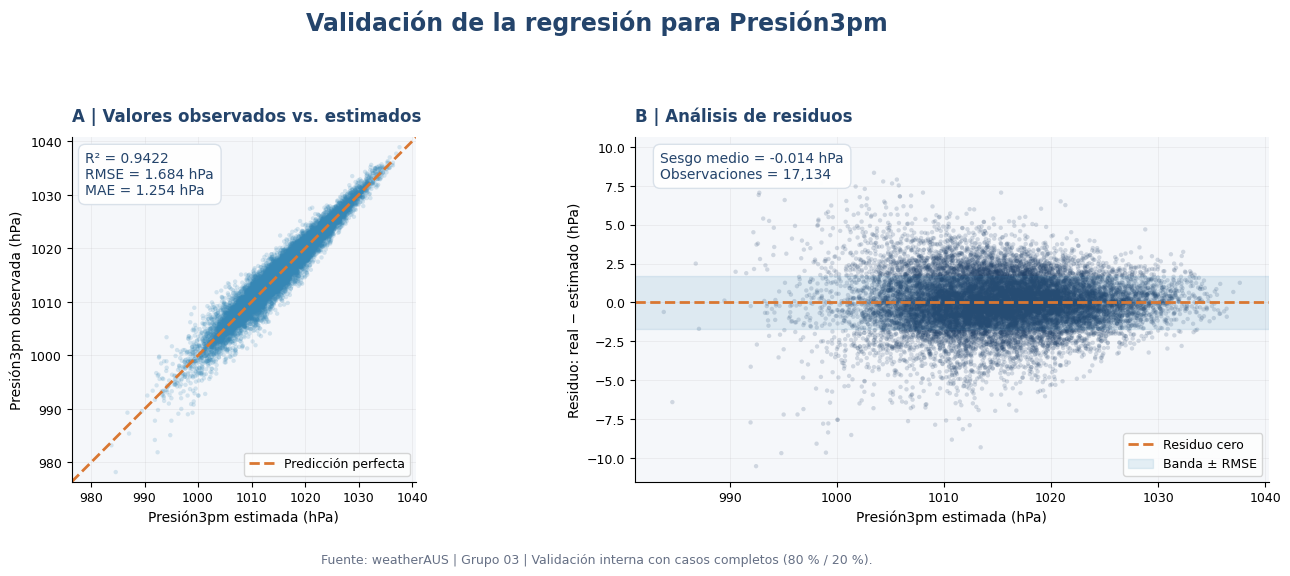

VALIDACIÓN DE REGRESIÓN - PRESIÓN3PM
---------------------------------------------
Observaciones completas: 85,667
Observaciones de validación: 17,134
MAE: 1.254 hPa
RMSE: 1.684 hPa
R²: 0.9422
Sesgo medio: -0.014 hPa


In [6]:

# ============================================================
# VERIFICACIÓN ESPECÍFICA: PRESIÓN3PM
# Regresión con casos completos | Grupo 03 - Sumativa 3
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ------------------------------------------------------------
# 1. PREPARACIÓN Y ENTRENAMIENTO
# ------------------------------------------------------------

v = "Presión3pm"
chosen = choices[v]

complete = train[[v] + chosen].dropna()

xx = complete[chosen]
yy = complete[v]

fi, vi = train_test_split(
    np.arange(len(complete)),
    test_size=0.20,
    random_state=SEED
)

audit = LinearRegression().fit(
    xx.iloc[fi],
    yy.iloc[fi]
)

y_real = yy.iloc[vi].to_numpy()
yhat = audit.predict(xx.iloc[vi])

res = y_real - yhat

# ------------------------------------------------------------
# 2. MÉTRICAS DE VALIDACIÓN
# ------------------------------------------------------------

mae = mean_absolute_error(y_real, yhat)
rmse = np.sqrt(mean_squared_error(y_real, yhat))
r2 = r2_score(y_real, yhat)
sesgo = np.mean(res)

# ------------------------------------------------------------
# 3. CONFIGURACIÓN VISUAL
# ------------------------------------------------------------

AZUL = "#24446B"
CELESTE = "#3687B5"
NARANJA = "#D97732"
GRIS = "#667085"
FONDO = "#F5F7FA"

fig, axs = plt.subplots(
    1, 2,
    figsize=(14, 5.2),
    facecolor="white"
)

fig.suptitle(
    "Validación de la regresión para Presión3pm",
    fontsize=17,
    fontweight="bold",
    color=AZUL,
    y=1.05
)

# ------------------------------------------------------------
# 4. GRÁFICO A: VALORES REALES VS. ESTIMADOS
# ------------------------------------------------------------

ax = axs[0]
ax.set_facecolor(FONDO)

ax.scatter(
    yhat,
    y_real,
    s=10,
    alpha=0.18,
    color=CELESTE,
    edgecolors="none",
    rasterized=True
)

lim_inf = min(
    np.min(y_real),
    np.min(yhat)
)

lim_sup = max(
    np.max(y_real),
    np.max(yhat)
)

margen = 0.03 * (lim_sup - lim_inf)

lim_inf -= margen
lim_sup += margen

ax.plot(
    [lim_inf, lim_sup],
    [lim_inf, lim_sup],
    linestyle="--",
    linewidth=2,
    color=NARANJA,
    label="Predicción perfecta"
)

ax.set_xlim(lim_inf, lim_sup)
ax.set_ylim(lim_inf, lim_sup)
ax.set_aspect("equal", adjustable="box")

ax.set_title(
    "A | Valores observados vs. estimados",
    fontsize=12,
    fontweight="bold",
    color=AZUL,
    loc="left",
    pad=12
)

ax.set_xlabel(
    "Presión3pm estimada (hPa)"
)

ax.set_ylabel(
    "Presión3pm observada (hPa)"
)

ax.text(
    0.04,
    0.96,
    (
        f"R² = {r2:.4f}\n"
        f"RMSE = {rmse:.3f} hPa\n"
        f"MAE = {mae:.3f} hPa"
    ),
    transform=ax.transAxes,
    va="top",
    ha="left",
    fontsize=10,
    color=AZUL,
    bbox={
        "boxstyle": "round,pad=0.5",
        "facecolor": "white",
        "edgecolor": "#D8E0E9",
        "alpha": 0.96
    }
)

ax.legend(
    loc="lower right",
    fontsize=9
)

# ------------------------------------------------------------
# 5. GRÁFICO B: RESIDUOS VS. VALORES ESTIMADOS
# ------------------------------------------------------------

ax = axs[1]
ax.set_facecolor(FONDO)

ax.scatter(
    yhat,
    res,
    s=10,
    alpha=0.18,
    color=AZUL,
    edgecolors="none",
    rasterized=True
)

ax.axhline(
    0,
    color=NARANJA,
    linestyle="--",
    linewidth=2,
    label="Residuo cero"
)

# Banda descriptiva: ± RMSE
ax.axhspan(
    -rmse,
    rmse,
    color=CELESTE,
    alpha=0.12,
    label="Banda ± RMSE"
)

ax.set_title(
    "B | Análisis de residuos",
    fontsize=12,
    fontweight="bold",
    color=AZUL,
    loc="left",
    pad=12
)

ax.set_xlabel(
    "Presión3pm estimada (hPa)"
)

ax.set_ylabel(
    "Residuo: real − estimado (hPa)"
)

ax.text(
    0.04,
    0.96,
    (
        f"Sesgo medio = {sesgo:+.3f} hPa\n"
        f"Observaciones = {len(y_real):,}"
    ),
    transform=ax.transAxes,
    va="top",
    ha="left",
    fontsize=10,
    color=AZUL,
    bbox={
        "boxstyle": "round,pad=0.5",
        "facecolor": "white",
        "edgecolor": "#D8E0E9",
        "alpha": 0.96
    }
)

ax.legend(
    loc="lower right",
    fontsize=9
)

# ------------------------------------------------------------
# 6. FORMATO GENERAL
# ------------------------------------------------------------

for ax in axs:
    ax.grid(
        alpha=0.16,
        linestyle="-",
        linewidth=0.7
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.tick_params(labelsize=9)

fig.text(
    0.5,
    -0.015,
    (
        "Fuente: weatherAUS | Grupo 03 | "
        "Validación interna con casos completos (80 % / 20 %)."
    ),
    ha="center",
    fontsize=9,
    color=GRIS
)

plt.tight_layout(
    rect=[0, 0.03, 1, 0.97],
    w_pad=3
)

plt.show()

# ------------------------------------------------------------
# 7. RESULTADOS ESTADÍSTICOS
# ------------------------------------------------------------

print("VALIDACIÓN DE REGRESIÓN - PRESIÓN3PM")
print("-" * 45)
print(f"Observaciones completas: {len(complete):,}")
print(f"Observaciones de validación: {len(y_real):,}")
print(f"MAE: {mae:.3f} hPa")
print(f"RMSE: {rmse:.3f} hPa")
print(f"R²: {r2:.4f}")
print(f"Sesgo medio: {sesgo:+.3f} hPa")


### Interpretación y conclusión del diagnóstico de Presión3pm

El modelo de regresión lineal múltiple para `Presión3pm` obtuvo un **RMSE de 1,684 hPa y un R² de 0,942**, lo que evidencia una elevada capacidad de estimación en los registros completos utilizados para validación.

El gráfico de valores observados frente a estimados permite evaluar la proximidad de las predicciones a la diagonal de referencia, mientras que el gráfico de residuos facilita la identificación de posibles desviaciones sistemáticas y cambios en la dispersión de los errores.

Adicionalmente, el sesgo residual medio de −0,014 hPa obtenido anteriormente indica una diferencia promedio reducida entre los valores observados y estimados. Sin embargo, este resultado no garantiza ausencia de sesgo en los registros originalmente faltantes.

**Conclusión:** la regresión lineal múltiple presenta un desempeño favorable para estimar `Presión3pm` y constituye una alternativa técnicamente fundamentada para el tratamiento de sus valores faltantes. Su selección definitiva requiere comparar sus efectos sobre el tamaño muestral, las distribuciones y las correlaciones frente a eliminación e imputación por mediana.

### 1.3. Introducción: comparación de estrategias de imputación

En esta etapa se comparan tres métodos de tratamiento de datos faltantes: eliminación de observaciones, imputación por mediana e imputación mediante regresión lineal múltiple.

El análisis considera los resultados exploratorios de S1 y las correlaciones validadas en S2, con especial atención a `Presión3pm`, que presenta un 10,33 % de información ausente.

Se evaluará cómo cada estrategia afecta el tamaño muestral, la distribución de las variables meteorológicas y la conservación de sus correlaciones originales, utilizando parámetros de imputación obtenidos exclusivamente del conjunto de entrenamiento.

**Objetivo:** seleccionar una estrategia de imputación estadísticamente fundamentada que permita preparar los datos para los modelos de regresión logística, minimizando pérdidas de información y posibles distorsiones en las relaciones meteorológicas.


In [7]:

# ============================================================
# 1.3. COMPARACIÓN DE ESTRATEGIAS DE IMPUTACIÓN
# Grupo 03 | Sumativa 3 | weatherAUS
# ============================================================

import numpy as np
import pandas as pd
from IPython.display import display, HTML

# ------------------------------------------------------------
# 1. Preparación de las estrategias
# ------------------------------------------------------------

MAIN = "Regresión"

# Moda binaria calculada exclusivamente en entrenamiento
mode_bin = train["LluviaHoy_bin"].mode(dropna=True).iloc[0]

# Variables necesarias para comparar las estrategias
variables_modelo = NUM + ["LluviaHoy_bin", "LluviaMañana_bin"]

def build_strategy(kind):
    """
    Construye los conjuntos de entrenamiento y prueba
    para eliminación, mediana o regresión.
    """

    if kind == "Eliminación":
        tr = train[variables_modelo].dropna().copy()
        te = test[variables_modelo].dropna().copy()

    elif kind == "Mediana":
        tr = train[variables_modelo].copy()
        te = test[variables_modelo].copy()

        # Las medianas provienen solo de entrenamiento
        tr[NUM] = tr[NUM].fillna(med)
        te[NUM] = te[NUM].fillna(med)

        tr["LluviaHoy_bin"] = (
            tr["LluviaHoy_bin"].fillna(mode_bin)
        )
        te["LluviaHoy_bin"] = (
            te["LluviaHoy_bin"].fillna(mode_bin)
        )

    elif kind == "Regresión":
        tr = train[variables_modelo].copy()
        te = test[variables_modelo].copy()

        # Resultados generados en la sección 1.2
        tr[NUM] = reg_train[NUM]
        te[NUM] = reg_test[NUM]

        tr["LluviaHoy_bin"] = (
            tr["LluviaHoy_bin"].fillna(mode_bin)
        )
        te["LluviaHoy_bin"] = (
            te["LluviaHoy_bin"].fillna(mode_bin)
        )

    else:
        raise ValueError(
            f"Estrategia desconocida: {kind}"
        )

    # Verificación de datos completos
    assert not tr.isna().any().any()
    assert not te.isna().any().any()

    return tr, te


# ------------------------------------------------------------
# 2. Generar las tres estrategias
# ------------------------------------------------------------

strategies = {}

for estrategia in [
    "Eliminación",
    "Mediana",
    "Regresión"
]:
    strategies[estrategia] = build_strategy(estrategia)

# Conjunto principal para etapas posteriores
train_main, test_main = strategies[MAIN]


# ------------------------------------------------------------
# 3. Calcular indicadores comparativos
# ------------------------------------------------------------

compar = []

for estrategia, (tr, te) in strategies.items():

    compar.append({
        "Estrategia": estrategia,
        "Train N": len(tr),
        "Test N": len(te),
        "Total N": len(tr) + len(te),

        "P3pm media": tr["Presión3pm"].mean(),
        "P3pm sd": tr["Presión3pm"].std(),

        "r(P9,P3)": tr[
            ["Presión9am", "Presión3pm"]
        ].corr().iloc[0, 1],

        "r(P3,objetivo)": tr[
            ["Presión3pm", "LluviaMañana_bin"]
        ].corr().iloc[0, 1]
    })

tabla_comparacion = pd.DataFrame(compar)

# Mantener el orden deseado
orden = ["Eliminación", "Mediana", "Regresión"]

tabla_comparacion["Estrategia"] = pd.Categorical(
    tabla_comparacion["Estrategia"],
    categories=orden,
    ordered=True
)

tabla_comparacion = (
    tabla_comparacion
    .sort_values("Estrategia")
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 4. Preparar tablas de resultados
# ------------------------------------------------------------

tabla_muestra = tabla_comparacion[[
    "Estrategia",
    "Train N",
    "Test N",
    "Total N"
]].copy()

# Porcentaje de registros conservados
tabla_muestra["Conservación (%)"] = (
    tabla_muestra["Total N"]
    / (len(train) + len(test))
    * 100
)

tabla_estadisticos = tabla_comparacion[[
    "Estrategia",
    "P3pm media",
    "P3pm sd",
    "r(P9,P3)",
    "r(P3,objetivo)"
]].copy()

# ------------------------------------------------------------
# 5. Funciones de formato
# ------------------------------------------------------------

def formato_entero(x):
    return f"{int(x):,}".replace(",", ".")

for columna in ["Train N", "Test N", "Total N"]:
    tabla_muestra[columna] = (
        tabla_muestra[columna].map(formato_entero)
    )

tabla_muestra["Conservación (%)"] = (
    tabla_muestra["Conservación (%)"]
    .map(lambda x: f"{x:.2f}")
)

for columna in [
    "P3pm media",
    "P3pm sd",
    "r(P9,P3)",
    "r(P3,objetivo)"
]:
    tabla_estadisticos[columna] = (
        tabla_estadisticos[columna]
        .map(lambda x: f"{x:.4f}")
    )

# ------------------------------------------------------------
# 6. Diseño profesional de resultados
# ------------------------------------------------------------

css = """
<style>
.panel-estrategias {
    font-family: Arial, sans-serif;
    max-width: 1200px;
    color: #243247;
}

.panel-estrategias .resumen {
    background: #edf2f7;
    color: #243247;
    padding: 12px 16px;
    border-radius: 7px;
    margin-bottom: 18px;
}

.panel-estrategias .columnas {
    display: flex;
    gap: 20px;
    flex-wrap: wrap;
    align-items: flex-start;
}

.panel-estrategias .columna {
    flex: 1 1 450px;
    min-width: 0;
}

.panel-estrategias h3 {
    font-size: 15px;
    margin: 14px 0 9px;
}

.panel-estrategias table {
    border-collapse: collapse;
    width: 100%;
    font-size: 12px;
    margin-bottom: 18px;
}

.panel-estrategias th {
    background: #24446b;
    color: white;
    text-align: left;
    padding: 9px;
}

.panel-estrategias td {
    padding: 8px;
    border-bottom: 1px solid #d8dfe8;
    color: #222;
}

.panel-estrategias tbody tr:nth-child(even) {
    background: #f3f6fa;
}

.panel-estrategias tbody tr:nth-child(odd) {
    background: white;
}

.panel-estrategias tr.principal td {
    background: #e9f3fb;
    font-weight: bold;
}

.panel-estrategias .nota {
    background: #edf2f7;
    color: #243247;
    border-radius: 6px;
    padding: 12px;
    font-size: 12px;
    line-height: 1.5;
    margin-top: 10px;
}
</style>
"""

# Convertir tablas a HTML
html_muestra = tabla_muestra.to_html(
    index=False,
    escape=True
)

html_estadisticos = tabla_estadisticos.to_html(
    index=False,
    escape=True
)

# Destacar estrategia principal
def destacar_regresion(html):
    return html.replace(
        "<tr>\n      <td>Regresión</td>",
        '<tr class="principal">\n'
        '      <td>Regresión</td>'
    )

html_muestra = destacar_regresion(html_muestra)
html_estadisticos = destacar_regresion(
    html_estadisticos
)

# ------------------------------------------------------------
# 7. Mostrar resultados
# ------------------------------------------------------------

html_final = f"""
{css}

<div class="panel-estrategias">

    <div class="resumen">
        <b>Comparación de estrategias de imputación</b><br>
        Métodos evaluados: 3<br>
        Estrategia principal de trabajo: {MAIN}<br>
        Registros originales con etiqueta:
        {formato_entero(len(train) + len(test))}
    </div>

    <div class="columnas">

        <div class="columna">
            <h3>Tabla 1. Conservación de observaciones</h3>
            {html_muestra}
        </div>

        <div class="columna">
            <h3>Tabla 2. Distribución y correlaciones</h3>
            {html_estadisticos}
        </div>

    </div>

    <div class="nota">
        <b>Nota metodológica:</b><br>
        Las medianas y los modelos de regresión
        se obtuvieron exclusivamente del entrenamiento.
        Las correlaciones y estadísticas descriptivas
        se calculan sobre el entrenamiento de cada
        estrategia.<br><br>
        La correlación entre Presión9am y Presión3pm
        constituye una referencia validada en S2.
        Su conservación permite analizar posibles
        modificaciones provocadas por la imputación.
    </div>

</div>
"""

display(HTML(html_final))


# ------------------------------------------------------------
# 8. Comprobación final
# ------------------------------------------------------------

for estrategia, (tr, te) in strategies.items():
    assert not tr.isna().any().any()
    assert not te.isna().any().any()

print(
    "Validación correcta: las tres estrategias "
    "están preparadas para los modelos logísticos."
)


Estrategia,Train N,Test N,Total N,Conservación (%)
Eliminación,83.817,35.885,119.702,84.18
Mediana,99.535,42.658,142.193,100.00
Regresión,99.535,42.658,142.193,100.00
Estrategia,P3pm media,P3pm sd,"r(P9,P3)","r(P3,objetivo)"
Eliminación,1015.2513,7.0208,0.9618,-0.2279
Mediana,1015.2536,6.6818,0.9600,-0.2151
Regresión,1015.2644,6.6952,0.9570,-0.2109


Validación correcta: las tres estrategias están preparadas para los modelos logísticos.


###  Interpretación de las estrategias de imputación

La comparación de las tres estrategias evidencia diferencias en la conservación de observaciones. La **eliminación** mantiene 119.702 registros (84,18 %), descartando 22.491 observaciones, mientras que la imputación por **mediana y regresión** conserva la totalidad de los 142.193 registros con variable objetivo válida.

Respecto de `Presión3pm`, las tres estrategias mantienen medias similares, entre 1015,25 y 1015,26 hPa. Sin embargo, se observan diferencias en la dispersión, con desviaciones estándar de 7,0208 hPa para eliminación, 6,6818 hPa para mediana y 6,6952 hPa para regresión.

La correlación entre `Presión9am` y `Presión3pm`, validada previamente en S2, permanece elevada en las tres estrategias: 0,9618 para eliminación, 0,9600 para mediana y 0,9570 para regresión. Esto indica que las imputaciones conservan gran parte de la asociación entre ambas mediciones de presión.

Por otra parte, la correlación entre `Presión3pm` y la variable objetivo cambia de −0,2279 con eliminación a −0,2151 con mediana y −0,2109 con regresión. Estas diferencias sugieren que el tratamiento de datos faltantes puede modificar ligeramente las asociaciones utilizadas posteriormente en la clasificación.

### Conclusión

Se selecciona **la imputación mediante regresión lineal múltiple como estrategia principal de trabajo**, porque conserva todas las observaciones etiquetadas y aprovecha las relaciones meteorológicas identificadas en S1 y S2.

No obstante, la mediana también conserva la totalidad de los registros y presenta resultados descriptivos similares. Por ello, la selección de regresión no implica que sea estadísticamente superior en todas las métricas.

La decisión se complementará en la Parte 3, donde se comparará el impacto de las tres estrategias sobre los coeficientes y el desempeño predictivo del modelo logístico final.

---
## PARTE 2. Clasificación mediante regresión logística

### Introducción

En esta etapa se desarrollan modelos de regresión logística para predecir la ocurrencia de lluvia al día siguiente, utilizando el conjunto de datos `weatherAUS.csv` y los antecedentes obtenidos en S1, S2 y F3.

A partir de la estrategia de imputación seleccionada en la Parte 1, se preparan las variables predictoras, se controla la multicolinealidad y se comparan tres modelos: uno basado en las variables originales del proyecto, otro mediante selección stepwise-AIC y un tercero reducido mediante BIC.

Posteriormente, se evalúa la estabilidad de los coeficientes mediante bootstrap, se revisan los supuestos estadísticos y se compara el desempeño predictivo utilizando accuracy, precision, recall, F1-score y AUC-ROC.

**Objetivo:** identificar un modelo logístico fundamentado, estable y reproducible que permita mejorar especialmente la detección de días lluviosos respecto del modelo inicial F3.
### 2.1. Introducción: preparación de datos para regresión logística

En esta etapa se prepara el conjunto de datos resultante de la imputación mediante regresión lineal múltiple, seleccionada como estrategia principal en la Parte 1.

Se verifica la disponibilidad de las variables predictoras, se conserva la partición estratificada 70/30 y se aplica estandarización a las variables meteorológicas continuas, utilizando parámetros calculados exclusivamente con los datos de entrenamiento.

Asimismo, se mantiene la codificación binaria de `LluviaHoy_bin` y se consideran los antecedentes de S1 sobre valores extremos y desbalance de clases.

**Objetivo:** obtener conjuntos de entrenamiento y prueba consistentes, evitando fugas de información y estableciendo las condiciones necesarias para comparar los tres modelos logísticos.

**Tratamiento de outliers:** no se eliminan automáticamente observaciones de lluvia intensa, porque pueden ser meteorológicamente válidas y relevantes para la clasificación. En 2.4 se contrasta su conservación con winsorización suave, sin mirar el test final para seleccionar el tratamiento.

### 2.2. Introducción: selección de variables y ajuste de modelos logísticos

En esta etapa se construyen y comparan tres modelos de regresión logística para predecir la ocurrencia de lluvia al día siguiente, utilizando los antecedentes estadísticos obtenidos en S1, S2 y F3.

El **modelo M1** conserva los cinco predictores originales de F3; el **modelo M2** utiliza selección stepwise mediante el criterio AIC; y el **modelo M3** considera una selección reducida mediante BIC, buscando un equilibrio entre capacidad predictiva y complejidad.

La selección de variables considera las correlaciones validadas en S2, evitando incorporar simultáneamente predictores altamente correlacionados, especialmente las parejas de temperatura y presión atmosférica.

Para reducir el riesgo de fuga de información, la selección se realiza sobre datos de entrenamiento interno, manteniendo separados los conjuntos de validación y prueba. Posteriormente, los modelos se evaluarán mediante métricas predictivas y diagnósticos estadísticos.

**Objetivo:** identificar conjuntos de variables relevantes y construir modelos logísticos comparables, fundamentando su selección en evidencia estadística y criterios de información.

### Guía de ejecución 5. Selección de predictores y validación interna

En esta etapa se realiza la selección de variables para construir tres modelos de regresión logística, considerando los hallazgos de S1, las correlaciones validadas en S2 y el modelo inicial F3.

Del conjunto de entrenamiento (70 %) se reserva un 20 % para validación interna. La selección mediante **stepwise-AIC y BIC** se efectúa utilizando únicamente datos del entrenamiento interno, evitando emplear el conjunto externo de prueba.

Asimismo, se restringe la incorporación simultánea de variables altamente correlacionadas, especialmente las parejas de temperatura y presión identificadas en S2, con el propósito de controlar la multicolinealidad.

**Consideración metodológica:** la imputación principal fue ajustada sobre todo el entrenamiento externo. Por ello, para conseguir una validación interna completamente independiente sería necesario recalcular la imputación dentro del entrenamiento interno, antes de evaluar los modelos en la partición de validación.

**Objetivo:** seleccionar predictores relevantes y comparar modelos logísticos con distinta complejidad, manteniendo la trazabilidad metodológica y reduciendo el riesgo de sobreajuste.

In [8]:

# ==============================================================
# 2.2. SELECCIÓN DE VARIABLES Y VALIDACIÓN INTERNA
# Grupo 03 | Sumativa 3 | Dataset weatherAUS
# ==============================================================

import numpy as np
import pandas as pd
import statsmodels.api as sm

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from IPython.display import display, HTML

# --------------------------------------------------------------
# 1. CONFIGURACIÓN DE VARIABLES Y CONJUNTOS
# --------------------------------------------------------------

TARGET = "LluviaMañana_bin"
MAIN = "Regresión"

trainA, testA = strategies[MAIN]

candidates = [
    "Humedad3pm",
    "TemperaturaMáxima",
    "Presión3pm",
    "Lluvia",
    "LluviaHoy_bin",
    "Humedad9am",
    "TemperaturaMínima",
    "Temperatura3pm",
    "Presión9am",
    "RáfagaViento"
]

all_cont = [
    v for v in candidates
    if v != "LluviaHoy_bin"
]

# Cinco variables originales de F3
BASE = [
    "Humedad3pm",
    "TemperaturaMáxima",
    "Presión3pm",
    "Lluvia",
    "LluviaHoy_bin"
]

ya = trainA[TARGET].astype(int)
yb = testA[TARGET].astype(int)

# --------------------------------------------------------------
# 2. DIVISIÓN INTERNA: AJUSTE Y VALIDACIÓN
# --------------------------------------------------------------

ixfit, ixval = train_test_split(
    np.arange(len(trainA)),
    test_size=0.20,
    random_state=55,
    stratify=ya
)

raw_fit = train.iloc[ixfit].copy()
raw_val = train.iloc[ixval].copy()

# --------------------------------------------------------------
# 3. IMPUTACIÓN INTERNA SIN UTILIZAR VALIDACIÓN
# --------------------------------------------------------------

inner_medians = raw_fit[NUM].median()

inner_mode = (
    raw_fit["LluviaHoy_bin"]
    .mode(dropna=True)
    .iloc[0]
)

inner_fit = raw_fit[candidates].copy()
inner_val = raw_val[candidates].copy()

inner_imputation_report = []

for target in NUM:

    # Correlaciones calculadas solo en entrenamiento interno
    inner_corr = (
        raw_fit[NUM]
        .corr(numeric_only=True)[target]
        .drop(target)
        .abs()
        .sort_values(ascending=False)
    )

    pred = list(inner_corr.head(4).index)

    # Relación prioritaria de S1/S2
    if (
        target in prefer
        and prefer[target] in NUM
        and prefer[target] not in pred
    ):
        pred[-1] = prefer[target]

    if not pred:
        continue

    # Ajuste exclusivamente sobre observaciones completas
    complete_inner = (
        raw_fit[[target] + pred]
        .dropna()
    )

    if len(complete_inner) < 30:
        continue

    imputer_inner = LinearRegression().fit(
        complete_inner[pred],
        complete_inner[target]
    )

    low_inner, high_inner = (
        complete_inner[target]
        .quantile([0.005, 0.995])
    )

    n_fit_imputados = 0
    n_val_imputados = 0

    for nombre, raw_block, filled in [
        ("Ajuste", raw_fit, inner_fit),
        ("Validación", raw_val, inner_val)
    ]:

        missing = raw_block[target].isna()

        if missing.any():

            aux = (
                raw_block.loc[missing, pred]
                .fillna(inner_medians[pred])
            )

            estimaciones = imputer_inner.predict(aux)

            estimaciones = np.clip(
                estimaciones,
                low_inner,
                high_inner
            )

            filled.loc[missing, target] = estimaciones

        if nombre == "Ajuste":
            n_fit_imputados = int(missing.sum())
        else:
            n_val_imputados = int(missing.sum())

    inner_imputation_report.append({
        "Variable": target,
        "Casos completos": len(complete_inner),
        "Imputados ajuste": n_fit_imputados,
        "Imputados validación": n_val_imputados
    })

# Respaldo con medianas exclusivamente del ajuste interno
inner_fit[all_cont] = (
    inner_fit[all_cont]
    .fillna(inner_medians[all_cont])
)

inner_val[all_cont] = (
    inner_val[all_cont]
    .fillna(inner_medians[all_cont])
)

inner_fit["LluviaHoy_bin"] = (
    inner_fit["LluviaHoy_bin"].fillna(inner_mode)
)

inner_val["LluviaHoy_bin"] = (
    inner_val["LluviaHoy_bin"].fillna(inner_mode)
)

# --------------------------------------------------------------
# 4. ESTANDARIZACIÓN INTERNA
# --------------------------------------------------------------

scale_internal = StandardScaler().fit(
    inner_fit[all_cont]
)

inner_fit[all_cont] = (
    scale_internal.transform(inner_fit[all_cont])
)

inner_val[all_cont] = (
    scale_internal.transform(inner_val[all_cont])
)

# Reconstruir la matriz respetando las posiciones originales
A_inner = pd.DataFrame(
    index=trainA.index,
    columns=candidates,
    dtype=float
)

A_inner.iloc[ixfit] = (
    inner_fit[candidates].to_numpy(dtype=float)
)

A_inner.iloc[ixval] = (
    inner_val[candidates].to_numpy(dtype=float)
)

assert not A_inner.isna().any().any()

# --------------------------------------------------------------
# 5. SUBMUESTRA EXCLUSIVA PARA SELECCIÓN
# --------------------------------------------------------------

selection_pool = np.asarray(ixfit)

if len(selection_pool) > 15000:

    ixsel, _ = train_test_split(
        selection_pool,
        train_size=15000,
        random_state=SEED,
        stratify=ya.iloc[selection_pool]
    )

else:
    ixsel = selection_pool

Xs = A_inner.iloc[ixsel].copy()
ys = ya.iloc[ixsel].copy()

# --------------------------------------------------------------
# 6. RESTRICCIONES DE MULTICOLINEALIDAD
# --------------------------------------------------------------

def compatible(existing, v):

    pares_prohibidos = [
        {"TemperaturaMáxima", "Temperatura3pm"},
        {"Presión3pm", "Presión9am"}
    ]

    nuevo_conjunto = set(existing) | {v}

    return not any(
        par.issubset(nuevo_conjunto)
        for par in pares_prohibidos
    )

# --------------------------------------------------------------
# 7. FUNCIÓN AUXILIAR PARA AJUSTAR MODELOS LOGIT
# --------------------------------------------------------------

def ajustar_logit(variables):

    if variables:
        Xmodelo = Xs[variables]
    else:
        Xmodelo = pd.DataFrame(index=Xs.index)

    Xmodelo = sm.add_constant(
        Xmodelo,
        has_constant="add"
    )

    return sm.Logit(
        ys,
        Xmodelo
    ).fit(
        disp=0,
        maxiter=70
    )

# --------------------------------------------------------------
# 8. MODELO M2: STEPWISE BIDIRECCIONAL POR AIC
# --------------------------------------------------------------

def stepwise_aic(maxvars=8):

    chosen = []
    history = []

    cur = ajustar_logit([]).aic

    for step in range(2 * maxvars + 6):

        opts = []

        # Evaluar incorporación de variables
        if len(chosen) < maxvars:

            for v in candidates:

                if v in chosen or not compatible(chosen, v):
                    continue

                try:
                    nuevas = chosen + [v]
                    mod = ajustar_logit(nuevas)

                    opts.append((
                        mod.aic,
                        "Agregar",
                        v,
                        nuevas
                    ))

                except (
                    ValueError,
                    np.linalg.LinAlgError,
                    RuntimeError
                ):
                    continue

        # Evaluar eliminación de variables
        if len(chosen) > 1:

            for v in chosen:

                reduced = [
                    u for u in chosen if u != v
                ]

                try:
                    mod = ajustar_logit(reduced)

                    opts.append((
                        mod.aic,
                        "Quitar",
                        v,
                        reduced
                    ))

                except (
                    ValueError,
                    np.linalg.LinAlgError,
                    RuntimeError
                ):
                    continue

        if not opts:
            break

        score, action, v, new_chosen = min(
            opts,
            key=lambda z: z[0]
        )

        if score >= cur - 1e-5:
            break

        chosen = new_chosen
        cur = score

        history.append({
            "Paso": len(history) + 1,
            "Movimiento": action,
            "Variable": v,
            "AIC": score
        })

    return chosen, pd.DataFrame(
        history,
        columns=["Paso", "Movimiento", "Variable", "AIC"]
    )

# --------------------------------------------------------------
# 9. MODELO M3: SELECCIÓN REDUCIDA POR BIC
# --------------------------------------------------------------

def select_forward(criterion="bic", maxvars=5):

    chosen = []
    history = []

    best_score = getattr(
        ajustar_logit([]),
        criterion
    )

    for step in range(maxvars):

        tests = []

        for v in candidates:

            if v in chosen or not compatible(chosen, v):
                continue

            try:

                nuevas = chosen + [v]
                result = ajustar_logit(nuevas)

                tests.append((
                    getattr(result, criterion),
                    v
                ))

            except (
                ValueError,
                np.linalg.LinAlgError,
                RuntimeError
            ):
                continue

        if not tests:
            break

        score, v = min(tests)

        if score >= best_score - 1e-6:
            break

        chosen.append(v)
        best_score = score

        history.append({
            "Paso": step + 1,
            "Variable incorporada": v,
            criterion.upper(): score
        })

    return chosen, pd.DataFrame(
        history,
        columns=[
            "Paso",
            "Variable incorporada",
            criterion.upper()
        ]
    )

# --------------------------------------------------------------
# 10. SELECCIÓN DE VARIABLES PARA LOS TRES MODELOS
# --------------------------------------------------------------

sel_aic, hist_aic = stepwise_aic(
    maxvars=8
)

sel_bic, hist_bic = select_forward(
    criterion="bic",
    maxvars=5
)

FEATURESETS = {
    "M1 S1/S2": BASE.copy(),
    "M2 Stepwise AIC": sel_aic,
    "M3 Reducido BIC": sel_bic
}

# Verificar que ningún modelo tenga predictores incompatibles
for nombre, variables in FEATURESETS.items():

    if not variables:
        raise ValueError(
            f"El modelo {nombre} no seleccionó variables."
        )

    for variable in variables:
        assert compatible(
            [v for v in variables if v != variable],
            variable
        ), f"Variables incompatibles en {nombre}"

# --------------------------------------------------------------
# 11. ESTANDARIZACIÓN PARA MODELOS FINALES
# --------------------------------------------------------------

# Se ajusta exclusivamente sobre el entrenamiento externo.
scale = StandardScaler().fit(
    trainA[all_cont]
)

A = trainA[candidates].copy()
B = testA[candidates].copy()

A[all_cont] = scale.transform(
    A[all_cont]
)

B[all_cont] = scale.transform(
    B[all_cont]
)

A = A.astype(float)
B = B.astype(float)

assert not A.isna().any().any()
assert not B.isna().any().any()

# --------------------------------------------------------------
# 12. TABLA 1: TAMAÑO DE LAS MUESTRAS
# --------------------------------------------------------------

tabla_muestras = pd.DataFrame({
    "Conjunto": [
        "Entrenamiento externo",
        "Ajuste interno",
        "Validación interna",
        "Selección AIC/BIC",
        "Prueba externa"
    ],
    "Registros": [
        len(trainA),
        len(ixfit),
        len(ixval),
        len(ixsel),
        len(testA)
    ]
})

# --------------------------------------------------------------
# 13. TABLA 2: COMPARACIÓN DE MODELOS
# --------------------------------------------------------------

tabla_modelos = pd.DataFrame([
    {
        "Modelo": nombre,
        "N° variables": len(variables),
        "Predictores seleccionados": ", ".join(variables)
    }
    for nombre, variables in FEATURESETS.items()
])

# --------------------------------------------------------------
# 14. TABLAS 3 Y 4: HISTORIALES AIC / BIC
# --------------------------------------------------------------

tabla_aic = hist_aic.copy()
tabla_bic = hist_bic.copy()

# --------------------------------------------------------------
# 15. DISEÑO VISUAL PROFESIONAL
# --------------------------------------------------------------

css = """
<style>
.panel-seleccion {
    font-family: Arial, sans-serif;
    max-width: 1250px;
    color: #243247;
}

.panel-seleccion .resumen {
    background: #edf2f7;
    color: #243247;
    padding: 12px 16px;
    border-radius: 7px;
    margin-bottom: 18px;
}

.panel-seleccion .columnas {
    display: flex;
    gap: 20px;
    align-items: flex-start;
    flex-wrap: wrap;
}

.panel-seleccion .columna {
    flex: 1 1 420px;
    min-width: 0;
}

.panel-seleccion h3 {
    font-size: 15px;
    margin: 16px 0 9px;
}

.panel-seleccion table {
    width: 100%;
    border-collapse: collapse;
    font-size: 12px;
    margin-bottom: 18px;
}

.panel-seleccion th {
    background: #24446b;
    color: white;
    padding: 9px;
    text-align: left;
}

.panel-seleccion td {
    padding: 8px;
    border-bottom: 1px solid #d8dfe8;
    vertical-align: top;
    color: #222;
}

.panel-seleccion tbody tr:nth-child(even) {
    background: #f3f6fa;
}

.panel-seleccion tbody tr:nth-child(odd) {
    background: white;
}

.panel-seleccion .nota {
    background: #edf2f7;
    padding: 12px;
    border-radius: 6px;
    font-size: 12px;
    line-height: 1.5;
    margin-top: 10px;
}
</style>
"""

# --------------------------------------------------------------
# 16. FORMATO DE LAS TABLAS
# --------------------------------------------------------------

def mostrar_tabla(tabla, decimales=3):

    if tabla.empty:
        return "<p>No se registraron movimientos.</p>"

    return tabla.to_html(
        index=False,
        escape=True,
        na_rep="—",
        float_format=lambda x: f"{x:.{decimales}f}"
    )

# --------------------------------------------------------------
# 17. VISUALIZACIÓN DE RESULTADOS
# --------------------------------------------------------------

html_final = f"""
{css}

<div class="panel-seleccion">

    <div class="resumen">
        <b>Selección de predictores y validación interna</b><br>
        Estrategia principal: {MAIN}<br>
        Modelos comparados: {len(FEATURESETS)}<br>
        Selección AIC/BIC realizada exclusivamente
        con entrenamiento interno.
    </div>

    <h3>Tabla 1. Distribución de muestras</h3>
    {mostrar_tabla(tabla_muestras, 0)}

    <h3>Tabla 2. Variables seleccionadas por modelo</h3>
    {mostrar_tabla(tabla_modelos, 0)}

    <div class="columnas">

        <div class="columna">
            <h3>Tabla 3. Historial Stepwise-AIC</h3>
            {mostrar_tabla(tabla_aic, 2)}
        </div>

        <div class="columna">
            <h3>Tabla 4. Selección reducida BIC</h3>
            {mostrar_tabla(tabla_bic, 2)}
        </div>

    </div>

    <div class="nota">
        <b>Nota metodológica:</b><br>
        La imputación, estandarización y selección
        de variables se ajustaron utilizando
        exclusivamente entrenamiento interno
        para la fase de validación.<br><br>
        El conjunto externo de prueba permaneció
        reservado para evaluar los modelos finales.
        La selección excluyó combinaciones simultáneas
        de las dos temperaturas y de las dos presiones
        altamente correlacionadas identificadas en S2.
    </div>

</div>
"""

display(HTML(html_final))

print(
    "Validación correcta: matrices A y B preparadas, "
    "y tres conjuntos de variables definidos."
)


Validación correcta: matrices A y B preparadas, y tres conjuntos de variables definidos.


### Interpretación de la selección de variables y ajuste de modelos

La selección de predictores se desarrolló utilizando **79.628 registros de ajuste interno**, reservando 19.907 observaciones para validación. De los datos de ajuste, se utilizaron 15.000 registros para aplicar los criterios AIC y BIC, manteniendo independiente el conjunto externo de prueba de 42.658 observaciones.

Se establecieron tres modelos de regresión logística:

- **M1 – S1/S2:** conserva las cinco variables originales de F3, permitiendo mantener una referencia metodológica con las evaluaciones anteriores.
- **M2 – Stepwise-AIC:** seleccionó ocho predictores, incorporando variables adicionales de humedad, temperatura y viento. El criterio AIC disminuyó progresivamente hasta 11.521,00, favoreciendo un modelo de mayor complejidad.
- **M3 – Reducido-BIC:** seleccionó cinco predictores: `Humedad3pm`, `RáfagaViento`, `Presión3pm`, `LluviaHoy_bin` y `Humedad9am`, alcanzando un BIC de 11.612,94.

La selección respetó las restricciones derivadas de S2, evitando incorporar simultáneamente las parejas altamente correlacionadas de temperatura y presión atmosférica. Además, la imputación y estandarización internas se ajustaron exclusivamente con los registros destinados al aprendizaje.

### Conclusión

Los resultados muestran que **AIC seleccionó un modelo más amplio, mientras que BIC favoreció una alternativa más reducida**, con cinco variables meteorológicas.

Ambos criterios permitieron fundamentar la selección sin utilizar el conjunto externo de prueba. Sin embargo, una menor cantidad de predictores no garantiza por sí sola un mejor desempeño predictivo.

Por ello, los tres modelos deberán compararse posteriormente mediante accuracy, precision, recall, F1-score y AUC-ROC, considerando especialmente la detección de días lluviosos y el equilibrio entre sensibilidad y falsas alarmas.

### Guía de ejecución 6. Ajuste e interpretación de los modelos logísticos

En esta etapa se ajustan tres modelos de regresión logística para estimar la probabilidad de lluvia al día siguiente, utilizando los conjuntos de predictores seleccionados previamente mediante los criterios S1/S2, stepwise-AIC y BIC.

El análisis contempla la estimación de coeficientes, errores estándar, significancia estadística e intervalos de confianza del 95 %. Asimismo, se calculan los *odds ratios* (OR), que permiten interpretar la asociación entre cada variable meteorológica y las probabilidades relativas de ocurrencia de lluvia.

Las variables meteorológicas continuas se encuentran estandarizadas, mientras que `LluviaHoy_bin` mantiene su codificación binaria. Esto permite interpretar los OR de las variables continuas por cada incremento de una desviación estándar y el OR de la variable binaria al comparar presencia frente a ausencia de lluvia durante el día actual.

**Objetivo:** evaluar la dirección, magnitud y significancia de las asociaciones estimadas, identificando los predictores relevantes de cada modelo y sus diferencias en complejidad e interpretación estadística.

In [9]:

# ==============================================================
# GUÍA 6. AJUSTE Y EVALUACIÓN DE MODELOS LOGÍSTICOS
# Grupo 03 | Sumativa 3 | weatherAUS
# ==============================================================

import numpy as np
import pandas as pd
import statsmodels.api as sm

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
from IPython.display import display, HTML
from html import escape

# --------------------------------------------------------------
# 1. CONFIGURACIÓN
# --------------------------------------------------------------

POS_WEIGHT = 2.23
THRESHOLD = 0.50

rows = []
models = {}
probs = {}
fitted = {}
metrics_by_split = {}

# Referencia histórica F3
F3_BASELINE = {
    "Accuracy": 0.8345,
    "Precision": 0.7126,
    "Recall": 0.4384,
    "F1": 0.5428,
    "AUC": 0.8342
}

BASE_MAYORITARIA = 0.7758

# --------------------------------------------------------------
# 2. FUNCIÓN DE MÉTRICAS
# --------------------------------------------------------------

def metrics(ytrue, p, threshold=0.50):

    ytrue = np.asarray(ytrue).astype(int)
    p = np.asarray(p, dtype=float)

    yh = (p >= threshold).astype(int)

    return {
        "Accuracy": accuracy_score(ytrue, yh),
        "Precision": precision_score(
            ytrue, yh, zero_division=0
        ),
        "Recall": recall_score(
            ytrue, yh, zero_division=0
        ),
        "F1": f1_score(
            ytrue, yh, zero_division=0
        ),
        "AUC": roc_auc_score(ytrue, p)
    }

# --------------------------------------------------------------
# 3. AJUSTE Y VALIDACIÓN INTERNA
# --------------------------------------------------------------

for name, fs in FEATURESETS.items():

    if not fs:
        continue

    # Modelo ponderado para validación interna
    model_inner = LogisticRegression(
        max_iter=500,
        solver="lbfgs",
        class_weight={0: 1, 1: POS_WEIGHT}
    )

    model_inner.fit(
        A_inner.iloc[ixfit][fs],
        ya.iloc[ixfit]
    )

    # Probabilidades de validación interna
    pv = model_inner.predict_proba(
        A_inner.iloc[ixval][fs]
    )[:, 1]

    resultado_val = metrics(
        ya.iloc[ixval],
        pv,
        threshold=THRESHOLD
    )

    rows.append({
        "Modelo": name,
        "N variables": len(fs),
        "Variables": ", ".join(fs),
        **resultado_val
    })

    # ----------------------------------------------------------
    # 4. MODELO PREDICTIVO FINAL: ENTRENAMIENTO EXTERNO
    # ----------------------------------------------------------

    model = LogisticRegression(
        max_iter=600,
        solver="lbfgs",
        class_weight={0: 1, 1: POS_WEIGHT}
    )

    model.fit(A[fs], ya)

    models[name] = model

    probs[name] = {
        "Train": model.predict_proba(A[fs])[:, 1],
        "Test": model.predict_proba(B[fs])[:, 1]
    }

    # Ajuste estadístico no ponderado para inferencia.
    # Sus coeficientes NO son los del modelo predictivo ponderado.
    fitted[name] = sm.Logit(
        ya,
        sm.add_constant(
            A[fs],
            has_constant="add"
        )
    ).fit(
        disp=0,
        maxiter=100
    )

    # ----------------------------------------------------------
    # 5. MÉTRICAS DE ENTRENAMIENTO Y PRUEBA
    # ----------------------------------------------------------

    for split, ysplit in [
        ("Train", ya),
        ("Test", yb)
    ]:

        metrics_by_split[(name, split)] = metrics(
            ysplit,
            probs[name][split],
            threshold=THRESHOLD
        )

# --------------------------------------------------------------
# 6. TABLA DE VALIDACIÓN INTERNA
# --------------------------------------------------------------

val_table = (
    pd.DataFrame(rows)
    .sort_values(
        ["AUC", "Recall"],
        ascending=[False, False]
    )
    .reset_index(drop=True)
)

if val_table.empty:
    raise ValueError(
        "No se pudieron evaluar modelos en validación."
    )

# Ganador elegido SOLO con validación interna
WINNER = val_table.iloc[0]["Modelo"]
cols = FEATURESETS[WINNER]

# --------------------------------------------------------------
# 7. TABLA DE ENTRENAMIENTO Y TEST EXTERNO
# --------------------------------------------------------------

record = []

for (name, split), vals in metrics_by_split.items():

    record.append({
        "Modelo": name,
        "Partición": (
            "Entrenamiento"
            if split == "Train"
            else "Prueba externa"
        ),
        **vals
    })

tabla_evaluacion = pd.DataFrame(record)

# --------------------------------------------------------------
# 8. COMPARACIÓN CON F3 HISTÓRICO
# --------------------------------------------------------------

metricas_ganador_test = metrics_by_split[
    (WINNER, "Test")
]

tabla_historica = pd.DataFrame([
    {
        "Referencia": "F3 histórico",
        **F3_BASELINE
    },
    {
        "Referencia": f"Sumativa 3 - {WINNER}",
        **metricas_ganador_test
    }
])

# Diferencias descriptivas con F3
tabla_diferencias = pd.DataFrame([
    {
        "Métrica": metrica,
        "F3 histórico": F3_BASELINE[metrica],
        "Modelo actual": metricas_ganador_test[metrica],
        "Diferencia": (
            metricas_ganador_test[metrica]
            - F3_BASELINE[metrica]
        )
    }
    for metrica in [
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "AUC"
    ]
])

# --------------------------------------------------------------
# 9. ESTILO VISUAL DE LAS TABLAS
# --------------------------------------------------------------

CSS = """
<style>
.panel-logistica {
    font-family: Arial, sans-serif;
    max-width: 1250px;
    color: #243247;
}

.panel-logistica .resumen {
    background: #edf2f7;
    color: #243247;
    padding: 12px 16px;
    border-radius: 7px;
    margin-bottom: 18px;
    line-height: 1.7;
}

.panel-logistica h3 {
    font-size: 15px;
    margin: 18px 0 10px;
    color: #243247;
}

.panel-logistica .tabla-scroll {
    width: 100%;
    overflow-x: auto;
    margin-bottom: 15px;
}

.panel-logistica table {
    width: 100%;
    border-collapse: collapse;
    font-size: 12px;
}

.panel-logistica th {
    background: #24446b;
    color: white;
    text-align: left;
    padding: 10px;
    white-space: nowrap;
}

.panel-logistica td {
    padding: 9px;
    border-bottom: 1px solid #d8dfe8;
    color: #222;
    vertical-align: top;
}

.panel-logistica tbody tr:nth-child(even) {
    background: #f3f6fa;
}

.panel-logistica tbody tr:nth-child(odd) {
    background: white;
}

.panel-logistica tr.destacado td {
    background: #e9f3fb;
    font-weight: bold;
}

.panel-logistica .columnas {
    display: flex;
    flex-wrap: wrap;
    gap: 20px;
    align-items: flex-start;
}

.panel-logistica .columna {
    flex: 1 1 440px;
    min-width: 0;
}

.panel-logistica .nota {
    background: #edf2f7;
    color: #243247;
    padding: 12px;
    border-radius: 7px;
    font-size: 12px;
    line-height: 1.6;
    margin-top: 14px;
}
</style>
"""

# --------------------------------------------------------------
# 10. FUNCIÓN PARA GENERAR TABLAS HTML
# --------------------------------------------------------------

def tabla_html(tabla, destacado=None, columna="Modelo"):

    vista = tabla.copy()

    # Formato de métricas
    for col in vista.columns:

        if col in [
            "Accuracy",
            "Precision",
            "Recall",
            "F1",
            "AUC",
            "F3 histórico",
            "Modelo actual",
            "Diferencia"
        ]:
            vista[col] = vista[col].map(
                lambda x: f"{x:.4f}"
                if pd.notna(x) else "—"
            )

    html = ['<div class="tabla-scroll"><table>']

    html.append("<thead><tr>")

    for col in vista.columns:
        html.append(
            f"<th>{escape(str(col))}</th>"
        )

    html.append("</tr></thead><tbody>")

    for _, fila in vista.iterrows():

        resaltar = (
            destacado is not None
            and columna in vista.columns
            and str(fila[columna]) == str(destacado)
        )

        clase = (
            ' class="destacado"'
            if resaltar else ""
        )

        html.append(f"<tr{clase}>")

        for valor in fila:
            html.append(
                f"<td>{escape(str(valor))}</td>"
            )

        html.append("</tr>")

    html.append("</tbody></table></div>")

    return "".join(html)

# --------------------------------------------------------------
# 11. PREPARACIÓN DE VISTAS
# --------------------------------------------------------------

columnas_metricas = [
    "Modelo",
    "N variables",
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "AUC"
]

vista_val = val_table[columnas_metricas].copy()

vista_test = tabla_evaluacion[[
    "Modelo",
    "Partición",
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "AUC"
]].copy()

vista_historica = tabla_historica[[
    "Referencia",
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "AUC"
]].copy()

# --------------------------------------------------------------
# 12. MOSTRAR RESULTADOS
# --------------------------------------------------------------

html_final = f"""
{CSS}

<div class="panel-logistica">

    <div class="resumen">
        <b>Ajuste y evaluación de modelos logísticos</b><br>
        Modelos evaluados: {len(FEATURESETS)}<br>
        Peso de clase positiva: {POS_WEIGHT:.2f}<br>
        Umbral de clasificación: {THRESHOLD:.2f}<br>
        Modelo seleccionado por validación interna:
        <b>{escape(WINNER)}</b><br>
        Variables seleccionadas: {len(cols)}
    </div>

    <h3>Tabla 1. Resultados de validación interna</h3>
    {tabla_html(vista_val, destacado=WINNER)}

    <h3>Tabla 2. Desempeño en entrenamiento y prueba externa</h3>
    {tabla_html(vista_test, destacado=WINNER)}

    <h3>Tabla 3. Comparación descriptiva con F3</h3>
    {tabla_html(vista_historica)}

    <h3>Tabla 4. Diferencias frente al modelo F3</h3>
    {tabla_html(tabla_diferencias)}

    <div class="nota">
        <b>Nota metodológica:</b><br>
        El modelo ganador fue seleccionado exclusivamente
        utilizando AUC y Recall de validación interna.
        Las métricas de prueba externa se presentan
        después de fijar dicha elección.<br><br>

        Se utilizó regresión logística ponderada
        con peso 2.23 para la clase positiva
        y umbral de clasificación 0.50.<br><br>

        Los resultados de F3 corresponden a una
        referencia histórica. Sus diferencias con
        la Sumativa 3 son descriptivas y no prueban
        una mejora causal, pues podrían existir
        diferencias en los conjuntos evaluados.<br><br>

        Los modelos guardados en fitted utilizan
        Logit sin ponderación para análisis inferencial;
        sus coeficientes no deben confundirse
        con los modelos predictivos ponderados.
    </div>

</div>
"""

display(HTML(html_final))

# --------------------------------------------------------------
# 13. VERIFICACIONES FINALES
# --------------------------------------------------------------

assert WINNER in models
assert WINNER in fitted
assert WINNER in probs

assert len(probs[WINNER]["Train"]) == len(ya)
assert len(probs[WINNER]["Test"]) == len(yb)

print(
    "Validación correcta: tres modelos ajustados "
    "y evaluados."
)

print(
    "Ganador por validación interna:",
    WINNER
)

print(
    "Variables del modelo seleccionado:",
    ", ".join(cols)
)


Modelo,N variables,Accuracy,Precision,Recall,F1,AUC
M3 Reducido BIC,5,0.8096,0.5648,0.6565,0.6072,0.8426
M2 Stepwise AIC,8,0.8089,0.5632,0.6572,0.6066,0.8425
M1 S1/S2,5,0.8063,0.5598,0.6377,0.5962,0.8282
Modelo,Partición,Accuracy,Precision,Recall,F1,AUC
M1 S1/S2,Entrenamiento,0.8055,0.5588,0.6300,0.5923,0.8282
M1 S1/S2,Prueba externa,0.8065,0.5607,0.6329,0.5946,0.8289
M2 Stepwise AIC,Entrenamiento,0.8098,0.5660,0.6504,0.6053,0.8416
M2 Stepwise AIC,Prueba externa,0.8113,0.5685,0.6561,0.6092,0.8418
M3 Reducido BIC,Entrenamiento,0.8106,0.5676,0.6515,0.6067,0.8410
M3 Reducido BIC,Prueba externa,0.8115,0.5692,0.6553,0.6092,0.8408


Validación correcta: tres modelos ajustados y evaluados.
Ganador por validación interna: M3 Reducido BIC
Variables del modelo seleccionado: Humedad3pm, RáfagaViento, Presión3pm, LluviaHoy_bin, Humedad9am


### Interpretación de los resultados de los modelos logísticos

Se evaluaron tres modelos de regresión logística ponderada, utilizando un peso de 2,23 para la clase positiva y un umbral de clasificación de 0,50.

En la validación interna, el **modelo M3 Reducido BIC** obtuvo el mayor AUC (0,8426), con accuracy de 0,8096, recall de 0,6565 y F1-score de 0,6072. El modelo M2 presentó resultados muy similares, con AUC de 0,8425 y un recall ligeramente superior (0,6572). Por su parte, M1 alcanzó un AUC de 0,8282.

El modelo M3 fue seleccionado por su mayor AUC de validación y su menor complejidad respecto de M2. Sus cinco predictores son `Humedad3pm`, `RáfagaViento`, `Presión3pm`, `LluviaHoy_bin` y `Humedad9am`.

En la prueba externa, M3 alcanzó accuracy de 0,8115, precision de 0,5692, recall de 0,6553, F1-score de 0,6092 y AUC de 0,8408. La similitud entre entrenamiento y prueba externa sugiere una capacidad de generalización favorable, sin evidencia de sobreajuste importante en estas métricas.

Respecto del modelo histórico F3, el recall aumentó de 0,4384 a 0,6553, equivalente a **21,69 puntos porcentuales**. Asimismo, el F1-score mejoró 6,64 puntos porcentuales y el AUC aumentó 0,66 puntos porcentuales. Sin embargo, accuracy y precision disminuyeron 2,30 y 14,34 puntos porcentuales, respectivamente.

Estas diferencias indican que el modelo actual identifica una mayor proporción de días lluviosos, pero también presenta una mayor proporción de falsas alarmas entre sus predicciones positivas. La comparación con F3 es descriptiva, pues las condiciones de evaluación histórica podrían no ser idénticas.

### Conclusión

Se selecciona **M3 Reducido BIC como modelo principal**, porque alcanzó el mayor AUC en validación interna y utiliza cinco predictores, frente a los ocho de M2.

El aumento del recall representa un resultado favorable para el objetivo de detectar lluvia al día siguiente, aunque implica un compromiso con la precisión.

La elección deberá complementarse con el análisis de coeficientes, odds ratios, multicolinealidad y estabilidad mediante bootstrap, antes de establecer conclusiones definitivas sobre la confiabilidad estadística del modelo.

### Guía de ejecución 6.1. Coeficientes y odds ratios

En esta etapa se interpretan los coeficientes de los tres modelos de regresión logística, considerando su dirección, magnitud y significancia estadística.

Para cada predictor se calculan el coeficiente β, el error estándar, el valor p, el *odds ratio* (OR) y su intervalo de confianza del 95 %.

Un OR superior a 1 representa una asociación con mayores *odds* de lluvia al día siguiente, mientras que un OR inferior a 1 indica menores *odds*, manteniendo constantes los demás predictores.

Las variables meteorológicas continuas fueron estandarizadas, por lo que sus OR representan el cambio asociado a un incremento de una desviación estándar. Para `LluviaHoy_bin`, el OR corresponde al cambio de 0 a 1.

**Consideración metodológica:** la inferencia se obtiene mediante `statsmodels.Logit` sin ponderación, mientras que la predicción utiliza regresión logística ponderada con un peso de 2,23 para la clase positiva. Por ello, ambos conjuntos de coeficientes deben interpretarse por separado.

**Objetivo:** identificar las asociaciones estadísticas de las variables meteorológicas con la lluvia del día siguiente y comparar la interpretación de los tres modelos.

In [10]:

# ============================================================
# GUÍA 6.1 - COEFICIENTES Y ODDS RATIOS
# Grupo 03 | Sumativa 3 | weatherAUS
# ============================================================

import numpy as np
import pandas as pd
from IPython.display import display, HTML
from html import escape

# ------------------------------------------------------------
# 1. RECUPERAR RESULTADOS DE LOS MODELOS
# ------------------------------------------------------------

tablas_or = {}
filas_resumen = []
filas_ponderadas = []

for name, fit in fitted.items():

    # Intervalos de confianza de coeficientes logísticos
    ci = fit.conf_int()

    tabla = pd.DataFrame({
        "Variable": fit.params.index,
        "Beta": fit.params.to_numpy(),
        "Error estándar": fit.bse.to_numpy(),
        "OR": np.exp(fit.params.to_numpy()),
        "IC OR inferior": np.exp(ci.iloc[:, 0].to_numpy()),
        "IC OR superior": np.exp(ci.iloc[:, 1].to_numpy()),
        "Valor p": fit.pvalues.to_numpy()
    })

    tabla["Significativo (5 %)"] = np.where(
        tabla["Valor p"] < 0.05,
        "Sí",
        "No"
    )

    tabla["Variable"] = tabla["Variable"].replace({
        "const": "Intercepto"
    })

    tablas_or[name] = tabla

    filas_resumen.append({
        "Modelo": name,
        "N° variables": len(FEATURESETS[name]),
        "AIC": fit.aic,
        "BIC": fit.bic,
        "Pseudo-R²": fit.prsquared
    })

    # Coeficientes de los clasificadores ponderados
    modelo_ponderado = models[name]

    for variable, beta in zip(
        FEATURESETS[name],
        modelo_ponderado.coef_[0]
    ):
        filas_ponderadas.append({
            "Modelo": name,
            "Variable": variable,
            "Beta ponderada": float(beta),
            "OR ponderado": float(np.exp(beta))
        })

tabla_ajuste = pd.DataFrame(filas_resumen)
tabla_ponderada = pd.DataFrame(filas_ponderadas)

# ------------------------------------------------------------
# 2. FORMATO ACADÉMICO DE TABLAS
# ------------------------------------------------------------

def formatear_numero(x, decimales=4):
    return f"{x:.{decimales}f}"

def formatear_p(x):
    if x < 0.0001:
        return "< 0,0001"
    return f"{x:.4f}".replace(".", ",")

def tabla_profesional(df, variable_destacada=None):

    vista = df.copy()

    # Formato adecuado para cada tipo de columna
    for col in vista.columns:

        if col == "Valor p":
            vista[col] = vista[col].map(formatear_p)

        elif col in [
            "Beta",
            "Error estándar",
            "OR",
            "IC OR inferior",
            "IC OR superior",
            "Pseudo-R²",
            "Beta ponderada",
            "OR ponderado"
        ]:
            vista[col] = vista[col].map(
                lambda x: formatear_numero(x, 4)
            )

        elif col in ["AIC", "BIC"]:
            vista[col] = vista[col].map(
                lambda x: formatear_numero(x, 2)
            )

    partes = ['<div class="tabla-scroll"><table>']

    partes.append("<thead><tr>")

    for col in vista.columns:
        partes.append(f"<th>{escape(str(col))}</th>")

    partes.append("</tr></thead><tbody>")

    for _, fila in vista.iterrows():

        destacar = (
            variable_destacada is not None
            and "Variable" in vista.columns
            and fila["Variable"] == variable_destacada
        )

        clase = ' class="destacada"' if destacar else ""
        partes.append(f"<tr{clase}>")

        for valor in fila:
            partes.append(
                f"<td>{escape(str(valor))}</td>"
            )

        partes.append("</tr>")

    partes.append("</tbody></table></div>")

    return "".join(partes)

# ------------------------------------------------------------
# 3. ESTILO VISUAL
# ------------------------------------------------------------

css = """
<style>
.panel-or {
    font-family: Arial, sans-serif;
    max-width: 1250px;
    color: #243247;
}

.panel-or .resumen {
    background: #edf2f7;
    color: #243247;
    padding: 13px 16px;
    border-radius: 7px;
    margin-bottom: 18px;
    line-height: 1.7;
}

.panel-or h3 {
    font-size: 15px;
    margin: 18px 0 10px;
    color: #243247;
}

.panel-or .tabla-scroll {
    overflow-x: auto;
    margin-bottom: 18px;
}

.panel-or table {
    width: 100%;
    border-collapse: collapse;
    font-size: 12px;
}

.panel-or th {
    background: #24446b;
    color: white;
    text-align: left;
    padding: 10px;
    white-space: nowrap;
}

.panel-or td {
    padding: 9px;
    color: #222;
    border-bottom: 1px solid #d8dfe8;
}

.panel-or tbody tr:nth-child(odd) {
    background: white;
}

.panel-or tbody tr:nth-child(even) {
    background: #f3f6fa;
}

.panel-or tr.destacada td {
    background: #e9f3fb;
    font-weight: bold;
}

.panel-or .nota {
    background: #edf2f7;
    color: #243247;
    padding: 12px;
    border-radius: 7px;
    margin-top: 14px;
    line-height: 1.6;
    font-size: 12px;
}
</style>
"""

# ------------------------------------------------------------
# 4. GENERAR LA PRESENTACIÓN COMPLETA
# ------------------------------------------------------------

bloques = []

bloques.append("""
<h3>Tabla 1. Indicadores de ajuste estadístico</h3>
""")

bloques.append(tabla_profesional(tabla_ajuste))

for numero, (name, tabla) in enumerate(
    tablas_or.items(),
    start=2
):

    bloques.append(
        f"<h3>Tabla {numero}. "
        f"Coeficientes y odds ratios - "
        f"{escape(name)}</h3>"
    )

    bloques.append(
        tabla_profesional(
            tabla,
            variable_destacada="Humedad3pm"
        )
    )

# Tabla de coeficientes ponderados
numero_ponderada = len(tablas_or) + 2

bloques.append(
    f"<h3>Tabla {numero_ponderada}. "
    "Coeficientes del clasificador ponderado</h3>"
)

bloques.append(
    tabla_profesional(tabla_ponderada)
)

contenido_tablas = "\n".join(bloques)

html_final = f"""
{css}

<div class="panel-or">

    <div class="resumen">
        <b>Coeficientes y odds ratios</b><br>
        Modelos analizados: {len(fitted)}<br>
        Modelo seleccionado: {escape(WINNER)}<br>
        Nivel de confianza: 95 %<br>
        Nivel de significancia: 5 %
    </div>

    {contenido_tablas}

    <div class="nota">
        <b>Nota metodológica:</b><br>
        Las tablas de coeficientes, valores p,
        intervalos de confianza e indicadores
        AIC/BIC corresponden a los modelos
        statsmodels.Logit sin ponderación.<br><br>

        Los OR de variables continuas representan
        cambios de una desviación estándar,
        manteniendo constantes los demás predictores.
        Para LluviaHoy_bin corresponden al cambio
        entre las categorías 0 y 1.<br><br>

        La tabla final muestra los coeficientes
        del clasificador ponderado utilizado
        para predecir. Sus OR son descriptivos;
        no se les atribuyen los valores p ni
        intervalos de confianza del Logit sin pesos.
    </div>

</div>
"""

display(HTML(html_final))

# ------------------------------------------------------------
# 5. VERIFICACIÓN FINAL
# ------------------------------------------------------------

assert len(tablas_or) == len(FEATURESETS)

for name in FEATURESETS:
    assert name in tablas_or
    assert name in models

print(
    "Validación correcta: coeficientes, OR, "
    "intervalos y valores p calculados."
)


Validación correcta: coeficientes, OR, intervalos y valores p calculados.


### Interpretación de coeficientes y odds ratios

El análisis de regresión logística permitió estimar la dirección, magnitud y significancia estadística de las variables meteorológicas asociadas con la ocurrencia de lluvia al día siguiente.

En los tres modelos, todos los predictores incluidos presentaron valores p inferiores a 0,0001, evidenciando asociaciones estadísticamente significativas bajo los supuestos del modelo Logit sin ponderación.

Respecto de los indicadores de ajuste, **M2 Stepwise AIC** obtuvo el menor AIC (76.394,86), el menor BIC (76.480,43) y el mayor pseudo-R² (0,2790). Por su parte, **M3 Reducido BIC** presentó un AIC de 76.663,74, BIC de 76.720,79 y pseudo-R² de 0,2764. Esto demuestra que M2 presenta un mejor ajuste estadístico global, aunque requiere ocho predictores frente a los cinco de M3.

En el modelo principal **M3 Reducido BIC**, los resultados fueron los siguientes:

- **Humedad3pm (OR = 3,0283):** un aumento de una desviación estándar se asocia con aproximadamente tres veces las *odds* de lluvia al día siguiente, manteniendo constantes las demás variables.
- **RáfagaViento (OR = 1,6432):** un incremento de una desviación estándar se asocia con un aumento aproximado del 64,32 % en las *odds* de lluvia.
- **Presión3pm (OR = 0,6356):** un aumento de una desviación estándar se asocia con una disminución aproximada del 36,44 % en las *odds* de lluvia.
- **LluviaHoy_bin (OR = 1,7528):** la presencia de lluvia durante el día actual se asocia con *odds* de lluvia al día siguiente aproximadamente un 75,28 % mayores que cuando no llueve.
- **Humedad9am (OR = 1,2836):** un aumento de una desviación estándar se asocia con un incremento aproximado del 28,36 % en las *odds* de lluvia.

Todos los intervalos de confianza del 95 % de estos predictores excluyen el valor OR = 1, reforzando la evidencia estadística de sus asociaciones.

Los coeficientes del clasificador ponderado mantienen las mismas direcciones que los obtenidos mediante Logit sin ponderación, aunque presentan diferencias de magnitud. Por ello, los valores p e intervalos de confianza informados corresponden exclusivamente al ajuste no ponderado.

### Conclusión

Los resultados respaldan la relevancia de las variables de humedad, presión atmosférica, ráfagas de viento y presencia de lluvia actual para explicar estadísticamente la ocurrencia de lluvia al día siguiente.

Aunque M2 obtuvo mejores indicadores de ajuste estadístico, **M3 Reducido BIC se mantiene como modelo predictivo principal**, debido a su selección previa mediante validación interna, su menor complejidad y su desempeño predictivo competitivo.

La siguiente etapa permitirá evaluar la estabilidad de sus coeficientes mediante bootstrap y complementar el análisis con diagnósticos de multicolinealidad y residuos.

### Interpretación: selección del modelo logístico

La selección del modelo principal se realizó mediante validación interna, utilizando AUC como criterio prioritario y recall como criterio secundario, sin emplear el conjunto externo de prueba para tomar esta decisión.

El modelo **M3 Reducido BIC** alcanzó el mayor AUC de validación (0,8426), seguido de M2 Stepwise AIC (0,8425). Aunque la diferencia fue mínima, M3 presentó un desempeño competitivo utilizando solamente cinco predictores, frente a los ocho de M2.

En el ajuste inferencial posterior, M2 obtuvo menores valores de AIC y BIC y un pseudo-R² ligeramente superior. Sin embargo, estos indicadores no modifican la selección predictiva previamente establecida mediante validación interna.

Es importante distinguir que los **coeficientes, odds ratios, intervalos de confianza y valores p** corresponden al modelo `statsmodels.Logit` sin ponderación. En cambio, las probabilidades y métricas predictivas provienen de la regresión logística ponderada, con peso 2,23 para la clase positiva.

**Conclusión:** se mantiene M3 como modelo principal por su equilibrio entre desempeño predictivo y simplicidad. La estabilidad de sus coeficientes y la confiabilidad de sus asociaciones serán examinadas posteriormente mediante bootstrap y diagnósticos estadísticos.

## 2.3. Bootstrap de los coeficientes (10 puntos)

### Introducción

Como continuación del análisis estadístico desarrollado en S2, se aplicará la técnica de remuestreo bootstrap para evaluar la estabilidad de los coeficientes del modelo logístico seleccionado, **M3 Reducido BIC**.

Se realizarán 1.000 remuestras con reemplazo, utilizando una regresión binomial ponderada con peso de 2,23 para la clase positiva. Este procedimiento permitirá estimar la variabilidad de los coeficientes ante cambios en las observaciones utilizadas para el ajuste.

Para cada predictor se calcularán intervalos de confianza percentiles del 95 % de los coeficientes β y sus respectivos *odds ratios* (OR). Asimismo, se verificará la estabilidad del signo de los coeficientes y se contrastarán los intervalos bootstrap con los intervalos Wald obtenidos mediante un modelo binomial ponderado.

**Objetivo:** evaluar la estabilidad estadística de los predictores del modelo seleccionado y determinar si la dirección de sus asociaciones se mantiene frente al remuestreo.

### Guía de ejecución 7. Bootstrap ponderado del modelo seleccionado

Se ajustará una regresión binomial ponderada sobre **1.000 remuestras con reemplazo**, obtenidas a partir de una submuestra estratificada de 5.000 registros del entrenamiento.

En cada iteración se estimarán los coeficientes del modelo M3, manteniendo sus cinco predictores y la ponderación de 2,23 para la clase positiva.

Posteriormente, se calcularán los intervalos de confianza percentiles del 95 % para los coeficientes β y los OR, comparándolos con los intervalos Wald del mismo modelo binomial ponderado. También se evaluará la proporción de remuestras en que cada coeficiente conserva su signo.

**Consideración metodológica:** el bootstrap evaluará la estabilidad de los coeficientes condicionada a los predictores y al preprocesamiento previamente seleccionados. No repetirá la selección de variables ni la imputación en cada remuestra y supondrá independencia entre observaciones.

**Resultado esperado:** obtener al menos 1.000 ajustes válidos y determinar, a partir de sus intervalos y signos, qué predictores presentan asociaciones más estables.

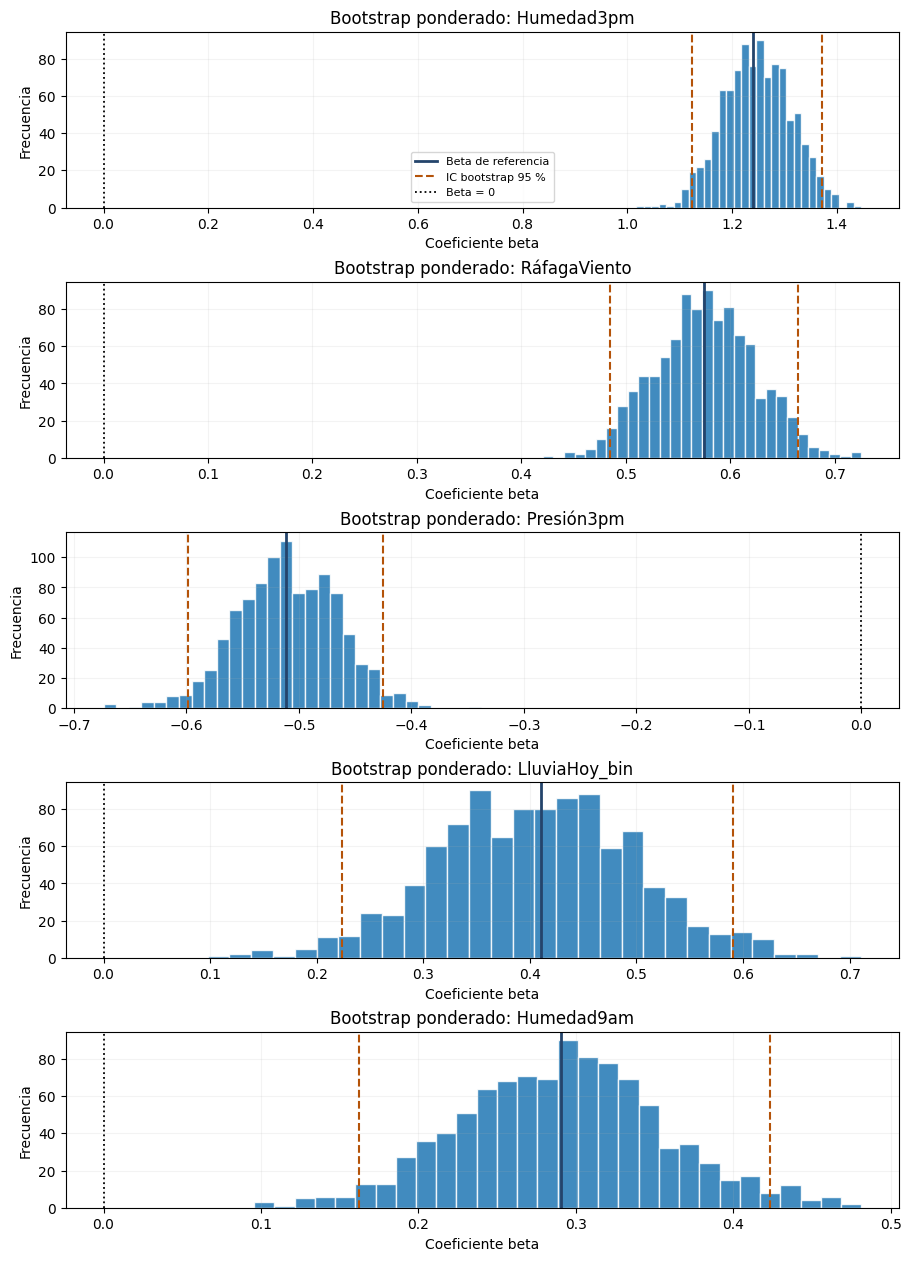

Bootstrap completado correctamente: 1000 remuestras exitosas.
Ajustes fallidos: 0 | Intentos totales: 1000
Predictores con IC bootstrap que excluye cero: 5 de 5


In [11]:

# ==============================================================
# 2.3. BOOTSTRAP PONDERADO DE LOS COEFICIENTES
# Grupo 03 | Sumativa 3 | weatherAUS
# Modelo ganador: M3 Reducido BIC
# ==============================================================

import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from IPython.display import display, HTML
from html import escape

# --------------------------------------------------------------
# 1. CONFIGURACIÓN REPRODUCIBLE
# --------------------------------------------------------------

BOOT = 1000
MAX_INTENTOS = 1200
BOOT_SEED = 81
BOOT_N = min(5000, len(A) - 1)

rng = np.random.default_rng(BOOT_SEED)

# Se mantienen los predictores del modelo ganador
terms = ["const"] + list(cols)

# --------------------------------------------------------------
# 2. SUBMUESTRA ESTRATIFICADA DE ENTRENAMIENTO
# --------------------------------------------------------------

ix_boot, _ = train_test_split(
    np.arange(len(A)),
    train_size=BOOT_N,
    random_state=BOOT_SEED,
    stratify=ya
)

boot_X = (
    A.iloc[ix_boot][cols]
    .reset_index(drop=True)
)

boot_y = (
    ya.iloc[ix_boot]
    .reset_index(drop=True)
)

boot_Xc = sm.add_constant(
    boot_X,
    has_constant="add"
)

boot_Xc = boot_Xc[terms]

# Ponderación consistente con la clasificación
weights = np.where(
    boot_y.to_numpy() == 1,
    POS_WEIGHT,
    1.0
)

# --------------------------------------------------------------
# 3. AJUSTE GLM BINOMIAL PONDERADO DE REFERENCIA
# --------------------------------------------------------------

ref_glm = sm.GLM(
    boot_y,
    boot_Xc,
    family=sm.families.Binomial(),
    freq_weights=weights
).fit(maxiter=100)

if not ref_glm.converged:
    raise RuntimeError(
        "El GLM ponderado de referencia no convergió."
    )

# --------------------------------------------------------------
# 4. BOOTSTRAP CON REEMPLAZO
# --------------------------------------------------------------

boot_coefs = []
fails = 0
errors = []
intentos = 0

while (
    len(boot_coefs) < BOOT
    and intentos < MAX_INTENTOS
):

    intentos += 1

    indices = rng.integers(
        0,
        len(boot_y),
        size=len(boot_y)
    )

    bs_x = (
        boot_Xc.iloc[indices]
        .reset_index(drop=True)
    )

    bs_y = (
        boot_y.iloc[indices]
        .reset_index(drop=True)
    )

    bs_w = np.where(
        bs_y.to_numpy() == 1,
        POS_WEIGHT,
        1.0
    )

    try:

        bm = sm.GLM(
            bs_y,
            bs_x,
            family=sm.families.Binomial(),
            freq_weights=bs_w
        ).fit(maxiter=70)

        beta = bm.params.reindex(terms).to_numpy()

        if not bm.converged or not np.isfinite(beta).all():
            fails += 1
            continue

        boot_coefs.append(beta)

    except Exception as e:

        fails += 1

        if len(errors) < 5:
            errors.append(str(e)[:120])

# Exigir 1.000 ajustes exitosos
if len(boot_coefs) != BOOT:
    raise RuntimeError(
        f"Bootstrap incompleto: "
        f"{len(boot_coefs)} exitosas de {BOOT}. "
        f"Intentos: {intentos}; fallidas: {fails}."
    )

boot_arr = np.asarray(boot_coefs)

# --------------------------------------------------------------
# 5. COEFICIENTES E INTERVALOS DE CONFIANZA
# --------------------------------------------------------------

ci_wald = ref_glm.conf_int()

boot_rows = []

for k, t in enumerate(terms):

    distribucion = boot_arr[:, k]

    beta_ref = float(ref_glm.params[t])

    lo, hi = np.percentile(
        distribucion,
        [2.5, 97.5]
    )

    wald_lo = float(ci_wald.loc[t, 0])
    wald_hi = float(ci_wald.loc[t, 1])

    # Proporción que mantiene el signo de referencia
    if beta_ref > 0:
        estabilidad = np.mean(distribucion > 0)

    elif beta_ref < 0:
        estabilidad = np.mean(distribucion < 0)

    else:
        estabilidad = np.nan

    boot_rows.append({
        "Variable": t,
        "beta ponderado": beta_ref,
        "IC ponderado inf": wald_lo,
        "IC ponderado sup": wald_hi,
        "IC bootstrap inf": lo,
        "IC bootstrap sup": hi,
        "OR ponderado": np.exp(beta_ref),
        "OR bootstrap inf": np.exp(lo),
        "OR bootstrap sup": np.exp(hi),
        "Signo estable": bool(lo > 0 or hi < 0),
        "Estabilidad signo (%)": estabilidad * 100
    })

tabla_bootstrap = pd.DataFrame(boot_rows)

# Conservar el nombre original del notebook
boot_rows = tabla_bootstrap.to_dict("records")

# --------------------------------------------------------------
# 6. TABLA 1: RESUMEN DEL PROCEDIMIENTO
# --------------------------------------------------------------

tabla_resumen = pd.DataFrame([
    {
        "Indicador": "Modelo evaluado",
        "Resultado": WINNER
    },
    {
        "Indicador": "Predictores",
        "Resultado": len(cols)
    },
    {
        "Indicador": "Observaciones de referencia",
        "Resultado": len(boot_y)
    },
    {
        "Indicador": "Remuestras solicitadas",
        "Resultado": BOOT
    },
    {
        "Indicador": "Remuestras exitosas",
        "Resultado": len(boot_arr)
    },
    {
        "Indicador": "Ajustes fallidos",
        "Resultado": fails
    },
    {
        "Indicador": "Intentos totales",
        "Resultado": intentos
    },
    {
        "Indicador": "Peso clase positiva",
        "Resultado": POS_WEIGHT
    }
])

# --------------------------------------------------------------
# 7. TABLAS ESTADÍSTICAS
# --------------------------------------------------------------

tabla_betas = tabla_bootstrap[[
    "Variable",
    "beta ponderado",
    "IC ponderado inf",
    "IC ponderado sup",
    "IC bootstrap inf",
    "IC bootstrap sup"
]].copy()

tabla_or = tabla_bootstrap[[
    "Variable",
    "OR ponderado",
    "OR bootstrap inf",
    "OR bootstrap sup"
]].copy()

tabla_signos = tabla_bootstrap[[
    "Variable",
    "Signo estable",
    "Estabilidad signo (%)"
]].copy()

tabla_signos["Signo estable"] = (
    tabla_signos["Signo estable"]
    .map({True: "Sí", False: "No"})
)

# --------------------------------------------------------------
# 8. FORMATO PROFESIONAL HTML
# --------------------------------------------------------------

css = """
<style>
.panel-bootstrap {
    font-family: Arial, sans-serif;
    max-width: 1250px;
    color: #243247;
}

.panel-bootstrap h3 {
    font-size: 15px;
    margin: 18px 0 10px;
    color: #243247;
}

.panel-bootstrap .resumen {
    padding: 12px 16px;
    background: #edf2f7;
    border-radius: 7px;
    margin-bottom: 18px;
    line-height: 1.7;
}

.panel-bootstrap .columnas {
    display: flex;
    gap: 18px;
    flex-wrap: wrap;
    align-items: flex-start;
}

.panel-bootstrap .columna {
    flex: 1 1 420px;
    min-width: 0;
}

.panel-bootstrap .tabla-scroll {
    overflow-x: auto;
    margin-bottom: 16px;
}

.panel-bootstrap table {
    width: 100%;
    border-collapse: collapse;
    font-size: 12px;
}

.panel-bootstrap th {
    background: #24446b;
    color: white;
    text-align: left;
    padding: 10px;
    white-space: nowrap;
}

.panel-bootstrap td {
    padding: 9px;
    border-bottom: 1px solid #d8dfe8;
    color: #222;
}

.panel-bootstrap tbody tr:nth-child(odd) {
    background: white;
}

.panel-bootstrap tbody tr:nth-child(even) {
    background: #f3f6fa;
}

.panel-bootstrap tr.destacado td {
    background: #e9f3fb;
    font-weight: bold;
}

.panel-bootstrap .nota {
    background: #edf2f7;
    padding: 12px;
    border-radius: 7px;
    font-size: 12px;
    line-height: 1.6;
    margin-top: 12px;
}
</style>
"""

def html_tabla(df, decimales=4):

    vista = df.copy()

    for col in vista.columns:

        if pd.api.types.is_float_dtype(vista[col]):
            vista[col] = vista[col].map(
                lambda x: (
                    f"{x:.{decimales}f}"
                    if pd.notna(x) else "—"
                )
            )

    partes = [
        '<div class="tabla-scroll"><table>',
        "<thead><tr>"
    ]

    for col in vista.columns:
        partes.append(
            f"<th>{escape(str(col))}</th>"
        )

    partes.append("</tr></thead><tbody>")

    for _, fila in vista.iterrows():

        destacar = (
            "Variable" in vista.columns
            and fila["Variable"] == "Humedad3pm"
        )

        clase = (
            ' class="destacado"'
            if destacar else ""
        )

        partes.append(f"<tr{clase}>")

        for valor in fila:
            partes.append(
                f"<td>{escape(str(valor))}</td>"
            )

        partes.append("</tr>")

    partes.append("</tbody></table></div>")

    return "".join(partes)

# --------------------------------------------------------------
# 9. PRESENTACIÓN DE LAS CUATRO TABLAS
# --------------------------------------------------------------

html_final = f"""
{css}

<div class="panel-bootstrap">

    <div class="resumen">
        <b>Bootstrap ponderado del modelo seleccionado</b><br>
        Modelo: {escape(WINNER)}<br>
        Remuestras válidas: {len(boot_arr)} / {BOOT}<br>
        Observaciones por remuestra: {len(boot_y)}<br>
        Peso positivo: {POS_WEIGHT:.2f}<br>
        Nivel de confianza: 95 %
    </div>

    <div class="columnas">

        <div class="columna">
            <h3>Tabla 1. Resumen del bootstrap</h3>
            {html_tabla(tabla_resumen)}
        </div>

        <div class="columna">
            <h3>Tabla 4. Estabilidad de los signos</h3>
            {html_tabla(tabla_signos, 2)}
        </div>

    </div>

    <h3>Tabla 2. Coeficientes e intervalos al 95 %</h3>
    {html_tabla(tabla_betas)}

    <h3>Tabla 3. Odds ratios e IC bootstrap al 95 %</h3>
    {html_tabla(tabla_or)}

    <div class="nota">
        <b>Nota metodológica:</b><br>
        Se realizaron 1.000 ajustes bootstrap exitosos
        sobre remuestras con reemplazo de una submuestra
        estratificada del entrenamiento externo.<br><br>

        Los intervalos bootstrap se calcularon mediante
        percentiles 2,5 y 97,5. Los intervalos Wald
        corresponden al GLM binomial ponderado ajustado
        sobre la misma submuestra original.<br><br>

        El análisis evalúa la estabilidad condicional
        de los coeficientes: no repite la selección
        de variables ni el proceso de imputación.
        Se supone independencia entre observaciones.
    </div>

</div>
"""

display(HTML(html_final))

# --------------------------------------------------------------
# 10. GRÁFICOS DE DISTRIBUCIONES BOOTSTRAP
# --------------------------------------------------------------

n = len(cols)

fig, axes = plt.subplots(
    n,
    1,
    figsize=(9, 2.5 * n),
    constrained_layout=True
)

axes = np.atleast_1d(axes)

for ax, variable in zip(axes, cols):

    j = terms.index(variable)

    distribucion = boot_arr[:, j]

    lo, hi = np.percentile(
        distribucion,
        [2.5, 97.5]
    )

    ax.hist(
        distribucion,
        bins=30,
        alpha=0.85,
        edgecolor="white"
    )

    ax.axvline(
        ref_glm.params[variable],
        color="#24446b",
        linewidth=2,
        label="Beta de referencia"
    )

    ax.axvline(
        lo,
        color="#b45309",
        linestyle="--",
        label="IC bootstrap 95 %"
    )

    ax.axvline(
        hi,
        color="#b45309",
        linestyle="--"
    )

    ax.axvline(
        0,
        color="black",
        linestyle=":",
        linewidth=1.3,
        label="Beta = 0"
    )

    ax.set_title(
        f"Bootstrap ponderado: {variable}"
    )

    ax.set_xlabel("Coeficiente beta")
    ax.set_ylabel("Frecuencia")
    ax.grid(alpha=0.15)

axes[0].legend(
    fontsize=8,
    loc="best"
)

plt.show()

# --------------------------------------------------------------
# 11. VALIDACIONES FINALES
# --------------------------------------------------------------

assert boot_arr.shape == (
    BOOT,
    len(terms)
)

assert np.isfinite(boot_arr).all()

print(
    f"Bootstrap completado correctamente: "
    f"{len(boot_arr)} remuestras exitosas."
)

print(
    f"Ajustes fallidos: {fails} | "
    f"Intentos totales: {intentos}"
)

print(
    "Predictores con IC bootstrap que excluye cero:",
    int(
        tabla_bootstrap.loc[
            tabla_bootstrap["Variable"] != "const",
            "Signo estable"
        ].sum()
    ),
    "de",
    len(cols)
)

if errors:
    print("Ejemplos de errores:", errors[:2])



###  Interpretación y conclusión del bootstrap

Se realizaron **1.000 remuestras exitosas**, sin fallas de convergencia, sobre 5.000 observaciones, utilizando regresión logística ponderada con peso positivo de 2,23.

Los cinco predictores de **M3 Reducido BIC** conservaron su signo en el 100 % de las remuestras y sus intervalos bootstrap del 95 % excluyeron el cero.

`Humedad3pm` presentó la mayor asociación positiva (OR = 3,4582), seguida de `RáfagaViento` (OR = 1,7768). En contraste, `Presión3pm` mostró una asociación negativa (OR = 0,5997). Los intervalos bootstrap fueron compatibles con los intervalos Wald en cuanto a la dirección de las asociaciones.

**Conclusión:** los resultados respaldan la estabilidad de los coeficientes del modelo M3 bajo las condiciones evaluadas. Sin embargo, esta estabilidad es condicional, ya que el bootstrap no repite la imputación ni la selección de variables y no considera explícitamente dependencias temporales o regionales.

## 2.4. Diagnósticos del modelo logístico

### Introducción

En esta etapa se realizan diagnósticos estadísticos del modelo **M3 Reducido BIC**, seleccionado mediante validación interna y evaluado posteriormente con bootstrap.

El análisis contempla la multicolinealidad mediante el factor de inflación de la varianza (VIF), el comportamiento de los residuos, la identificación de observaciones influyentes y la sensibilidad del modelo frente a valores extremos.

Estos procedimientos permiten detectar posibles limitaciones del ajuste y evaluar la consistencia de los coeficientes, considerando las relaciones meteorológicas identificadas previamente en S1 y S2.

**Objetivo:** verificar la estabilidad y las condiciones estadísticas del modelo logístico antes de realizar su evaluación predictiva final.

### Guía de ejecución 8. Diagnóstico del modelo logístico

Se evaluará el modelo **M3 Reducido BIC** mediante tres procedimientos: análisis de multicolinealidad con VIF, prueba exploratoria de no linealidad del logit y diagnóstico de residuos de Pearson y distancia de Cook.

El VIF permitirá identificar posibles redundancias entre los predictores. La prueba de razón de verosimilitudes (LR) evaluará si la incorporación de términos no lineales mejora el ajuste. Finalmente, los residuos y las distancias de Cook ayudarán a identificar observaciones que requieren revisión.

**Objetivo:** detectar posibles limitaciones del modelo y evaluar su consistencia estadística, sin eliminar automáticamente observaciones extremas que puedan representar fenómenos meteorológicos reales.

**Alcance:** la prueba de no linealidad y los diagnósticos de influencia serán exploratorios y se realizarán sobre una submuestra del entrenamiento.

Variable,VIF,Diagnóstico
Humedad3pm,1.795,Baja multicolinealidad
RáfagaViento,1.274,Baja multicolinealidad
Presión3pm,1.212,Baja multicolinealidad
LluviaHoy_bin,1.252,Baja multicolinealidad
Humedad9am,1.949,Baja multicolinealidad
Indicador,Resultado,Descripción
Modelo base - Logit,-1830.9811,Log-verosimilitud
Modelo con términos adicionales,-1828.3617,Log-verosimilitud
Estadístico LR,5.2388,Razón de verosimilitudes
Grados de libertad,4,Términos adicionales


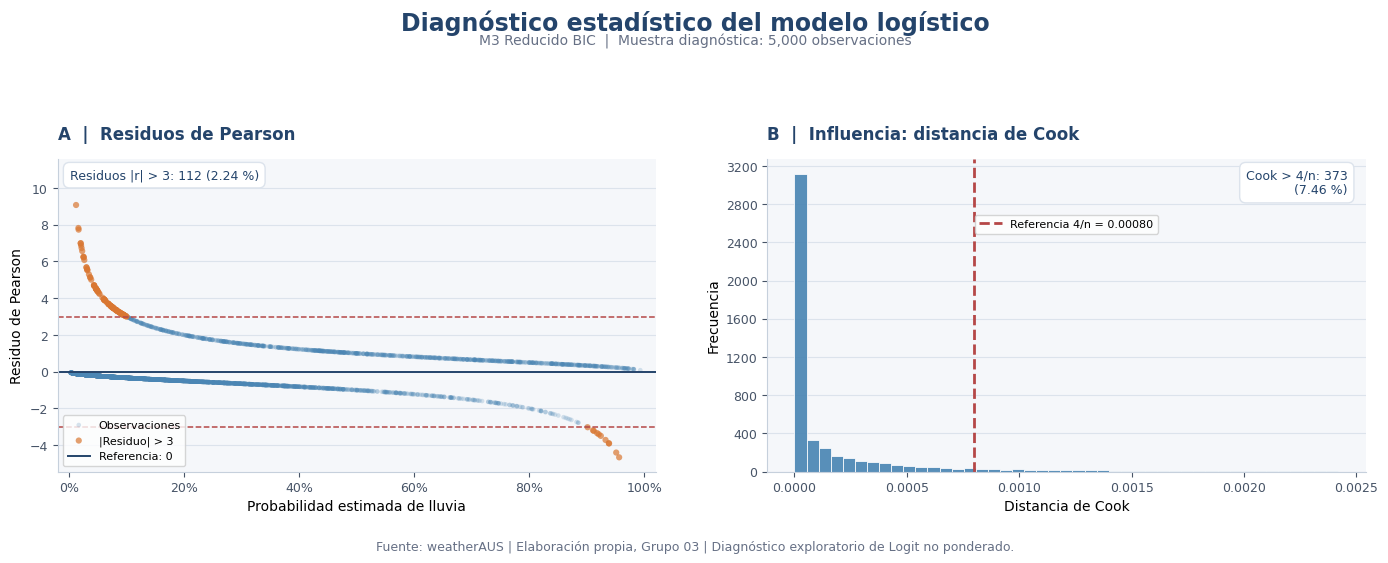

Diagnóstico ejecutado correctamente.
VIF máximo: 1.949
Prueba LR - p: 0.263662
Residuos elevados: 112 | Observaciones con Cook > 4/n: 373


In [12]:

# ============================================================
# 2.4. GUÍA 8 - DIAGNÓSTICO DEL MODELO LOGÍSTICO
# Grupo 03 | Sumativa 3 | M3 Reducido BIC
# ============================================================

import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt

from scipy import stats
from statsmodels.stats.outliers_influence import (
    variance_inflation_factor
)
from IPython.display import display, HTML
from html import escape

# ------------------------------------------------------------
# 1. MULTICOLINEALIDAD - VIF
# ------------------------------------------------------------

Xwin = A[cols].copy()

with_const = sm.add_constant(
    Xwin,
    has_constant="add"
)

vif = pd.DataFrame({
    "Variable": cols,
    "VIF": [
        variance_inflation_factor(
            with_const.to_numpy(),
            j
        )
        for j in range(1, with_const.shape[1])
    ]
})

vif["Diagnóstico"] = np.select(
    [
        vif["VIF"] < 5,
        vif["VIF"] < 10
    ],
    [
        "Baja multicolinealidad",
        "Revisar"
    ],
    default="Alta multicolinealidad"
)

# ------------------------------------------------------------
# 2. PRUEBA EXPLORATORIA DE NO LINEALIDAD
# ------------------------------------------------------------

# Submuestra creada previamente para el bootstrap
smallX = boot_X.copy()
smally = boot_y.copy()

base_d = sm.add_constant(
    smallX,
    has_constant="add"
)

# Términos adicionales de exploración
terms_add = {}

for v in cols:

    if v == "LluviaHoy_bin":
        continue

    q = smallX[v].to_numpy(dtype=float)

    terms_add[v + "_xlogabs"] = (
        q * np.log(np.abs(q) + 0.1)
    )

full_d = base_d.join(
    pd.DataFrame(
        terms_add,
        index=smallX.index
    )
)

# Comparación no ponderada, igual que el diagnóstico original
base_mod = sm.Logit(
    smally,
    base_d
).fit(
    disp=0,
    maxiter=100
)

extra_mod = sm.Logit(
    smally,
    full_d
).fit(
    disp=0,
    maxiter=100
)

LR = max(
    0.0,
    2 * (extra_mod.llf - base_mod.llf)
)

gl = len(terms_add)
p_lr = stats.chi2.sf(LR, gl)

tabla_linealidad = pd.DataFrame([
    {
        "Indicador": "Modelo base - Logit",
        "Resultado": f"{base_mod.llf:.4f}",
        "Descripción": "Log-verosimilitud"
    },
    {
        "Indicador": "Modelo con términos adicionales",
        "Resultado": f"{extra_mod.llf:.4f}",
        "Descripción": "Log-verosimilitud"
    },
    {
        "Indicador": "Estadístico LR",
        "Resultado": f"{LR:.4f}",
        "Descripción": "Razón de verosimilitudes"
    },
    {
        "Indicador": "Grados de libertad",
        "Resultado": str(gl),
        "Descripción": "Términos adicionales"
    },
    {
        "Indicador": "Valor p",
        "Resultado": f"{p_lr:.6g}",
        "Descripción": "Prueba exploratoria"
    },
    {
        "Indicador": "Resultado",
        "Resultado": (
            "Evidencia de no linealidad"
            if p_lr < 0.05
            else "Sin evidencia suficiente"
        ),
        "Descripción": "Criterio: alfa = 0,05"
    }
])

# ------------------------------------------------------------
# 3. RESIDUOS DE PEARSON Y DISTANCIA DE COOK
# ------------------------------------------------------------

# Ajuste clásico sobre la misma submuestra
sub_fit = base_mod

p_hat = np.clip(
    np.asarray(sub_fit.predict(base_d)),
    1e-5,
    1 - 1e-5
)

resid = (
    smally.to_numpy() - p_hat
) / np.sqrt(
    p_hat * (1 - p_hat)
)

infl = sub_fit.get_influence()
cooks = np.asarray(infl.cooks_distance[0])

n_resid_altos = int(
    np.sum(np.abs(resid) > 3)
)

limite_cook = 4 / len(cooks)

n_cook_altos = int(
    np.sum(cooks > limite_cook)
)

tabla_diagnostico = pd.DataFrame([
    {
        "Indicador": "Observaciones analizadas",
        "Resultado": len(resid)
    },
    {
        "Indicador": "Residuos Pearson |r| > 3",
        "Resultado": n_resid_altos
    },
    {
        "Indicador": "Porcentaje de residuos elevados",
        "Resultado": (
            f"{100*n_resid_altos/len(resid):.2f} %"
        )
    },
    {
        "Indicador": "Umbral de Cook (4/n)",
        "Resultado": f"{limite_cook:.6f}"
    },
    {
        "Indicador": "Observaciones Cook > 4/n",
        "Resultado": n_cook_altos
    },
    {
        "Indicador": "Porcentaje Cook elevado",
        "Resultado": (
            f"{100*n_cook_altos/len(cooks):.2f} %"
        )
    },
    {
        "Indicador": "Máxima distancia de Cook",
        "Resultado": f"{np.max(cooks):.6f}"
    }
])

# ------------------------------------------------------------
# 4. FORMATO VISUAL PROFESIONAL
# ------------------------------------------------------------

css = """
<style>
.panel-diag {
    font-family: Arial, sans-serif;
    max-width: 1250px;
    color: #243247;
}

.panel-diag .resumen {
    background: #edf2f7;
    color: #243247;
    padding: 12px 16px;
    border-radius: 7px;
    margin-bottom: 18px;
    line-height: 1.7;
}

.panel-diag .columnas {
    display: flex;
    flex-wrap: wrap;
    gap: 20px;
    align-items: flex-start;
}

.panel-diag .columna {
    flex: 1 1 420px;
    min-width: 0;
}

.panel-diag h3 {
    font-size: 15px;
    color: #243247;
    margin: 17px 0 10px;
}

.panel-diag table {
    width: 100%;
    border-collapse: collapse;
    font-size: 12px;
    margin-bottom: 18px;
}

.panel-diag th {
    background: #24446b;
    color: white;
    text-align: left;
    padding: 10px;
}

.panel-diag td {
    padding: 9px;
    border-bottom: 1px solid #d8dfe8;
    color: #222;
}

.panel-diag tbody tr:nth-child(odd) {
    background: white;
}

.panel-diag tbody tr:nth-child(even) {
    background: #f3f6fa;
}

.panel-diag .nota {
    background: #edf2f7;
    color: #243247;
    padding: 12px;
    border-radius: 7px;
    font-size: 12px;
    line-height: 1.6;
    margin-top: 10px;
}
</style>
"""

def html_tabla(df, decimales=4):

    vista = df.copy()

    for col in vista.columns:
        if pd.api.types.is_float_dtype(vista[col]):
            vista[col] = vista[col].map(
                lambda x: f"{x:.{decimales}f}"
            )

    return vista.to_html(
        index=False,
        escape=True,
        classes="tabla-diagnostico",
        border=0
    )

# ------------------------------------------------------------
# 5. MOSTRAR TABLAS
# ------------------------------------------------------------

html_final = f"""
{css}

<div class="panel-diag">

    <div class="resumen">
        <b>Diagnóstico del modelo logístico</b><br>
        Modelo: {escape(WINNER)}<br>
        Variables predictoras: {len(cols)}<br>
        Observaciones en diagnóstico exploratorio:
        {len(smally)}
    </div>

    <div class="columnas">

        <div class="columna">
            <h3>Tabla 1. Multicolinealidad (VIF)</h3>
            {html_tabla(vif, 3)}
        </div>

        <div class="columna">
            <h3>Tabla 2. Prueba exploratoria
            de no linealidad</h3>
            {html_tabla(tabla_linealidad)}
        </div>

    </div>

    <h3>Tabla 3. Residuos e influencia</h3>
    {html_tabla(tabla_diagnostico)}

    <div class="nota">
        <b>Nota metodológica:</b><br>
        El VIF se calculó con el entrenamiento externo
        del modelo seleccionado.<br><br>

        La prueba de no linealidad utiliza términos
        exploratorios x·log(|x| + 0,1), construidos
        sobre variables estandarizadas. No constituye
        una prueba definitiva de todos los tipos
        de no linealidad.<br><br>

        Los residuos y las distancias de Cook
        corresponden a un Logit no ponderado
        ajustado sobre la submuestra de diagnóstico.
        Los umbrales empleados son orientativos
        y no implican eliminar registros.
    </div>

</div>
"""

display(HTML(html_final))

# ------------------------------------------------------------

# ============================================================
# 6. VISUALIZACIONES PROFESIONALES DEL DIAGNÓSTICO
# Grupo 03 | Sumativa 3 | Modelo M3 Reducido BIC
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import MaxNLocator, PercentFormatter

# Paleta académica
AZUL = "#24446B"
AZUL_CLARO = "#4B86B4"
NARANJA = "#D97732"
ROJO = "#B54747"
GRIS = "#667085"
FONDO = "#F5F7FA"

# Datos previamente calculados en la Guía 8:
# p_hat, resid, cooks, limite_cook, WINNER

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5.3),
    facecolor="white"
)

fig.suptitle(
    "Diagnóstico estadístico del modelo logístico",
    fontsize=17,
    fontweight="bold",
    color=AZUL,
    y=1.025
)

fig.text(
    0.5, 0.965,
    f"{WINNER}  |  Muestra diagnóstica: {len(resid):,} observaciones",
    ha="center",
    va="center",
    fontsize=10,
    color=GRIS
)

# ------------------------------------------------------------
# GRÁFICO A: RESIDUOS DE PEARSON
# ------------------------------------------------------------

ax = axes[0]
ax.set_facecolor(FONDO)

# Observaciones habituales y residuos extremos
normal = np.abs(resid) <= 3
extremos = ~normal

ax.scatter(
    np.asarray(p_hat)[normal],
    np.asarray(resid)[normal],
    s=11,
    alpha=0.22,
    color=AZUL_CLARO,
    edgecolors="none",
    rasterized=True,
    label="Observaciones"
)

ax.scatter(
    np.asarray(p_hat)[extremos],
    np.asarray(resid)[extremos],
    s=20,
    alpha=0.70,
    color=NARANJA,
    edgecolors="none",
    rasterized=True,
    label="|Residuo| > 3"
)

ax.axhline(
    0,
    color=AZUL,
    linewidth=1.4,
    label="Referencia: 0"
)

for y in (-3, 3):
    ax.axhline(
        y,
        color=ROJO,
        linestyle="--",
        linewidth=1.1
    )

ax.set_title(
    "A  |  Residuos de Pearson",
    loc="left",
    fontsize=12,
    fontweight="bold",
    color=AZUL,
    pad=14
)

ax.set_xlabel(
    "Probabilidad estimada de lluvia",
    fontsize=10
)

ax.set_ylabel(
    "Residuo de Pearson",
    fontsize=10
)

ax.set_xlim(-0.02, 1.02)

ax.xaxis.set_major_formatter(
    PercentFormatter(xmax=1, decimals=0)
)

ax.grid(
    axis="y",
    color="#DCE3EC",
    linewidth=0.8
)

ax.set_axisbelow(True)

ax.text(
    0.02, 0.97,
    f"Residuos |r| > 3: {np.sum(extremos):,} "
    f"({100*np.mean(extremos):.2f} %)",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=9,
    color=AZUL,
    bbox=dict(
        facecolor="white",
        edgecolor="#DCE3EC",
        boxstyle="round,pad=0.5"
    )
)

ax.legend(
    loc="lower left",
    fontsize=8,
    frameon=True,
    facecolor="white"
)

# ------------------------------------------------------------
# GRÁFICO B: DISTANCIA DE COOK
# ------------------------------------------------------------

ax = axes[1]
ax.set_facecolor(FONDO)

# Recortar solo el rango mostrado para hacer legible el gráfico.
# El cálculo de observaciones influyentes conserva TODOS los datos.
limite_visual = max(
    float(np.quantile(cooks, 0.99)),
    float(limite_cook) * 2
)

limite_visual = min(
    limite_visual,
    float(np.max(cooks)) * 1.05
)

if limite_visual <= 0:
    limite_visual = 0.001

cooks_visibles = cooks[cooks <= limite_visual]

ax.hist(
    cooks_visibles,
    bins=45,
    color=AZUL_CLARO,
    alpha=0.92,
    edgecolor="white",
    linewidth=0.6
)

ax.axvline(
    limite_cook,
    color=ROJO,
    linewidth=2,
    linestyle="--",
    label=f"Referencia 4/n = {limite_cook:.5f}"
)

ax.set_title(
    "B  |  Influencia: distancia de Cook",
    loc="left",
    fontsize=12,
    fontweight="bold",
    color=AZUL,
    pad=14
)

ax.set_xlabel(
    "Distancia de Cook",
    fontsize=10
)

ax.set_ylabel(
    "Frecuencia",
    fontsize=10
)

ax.yaxis.set_major_locator(
    MaxNLocator(integer=True)
)

ax.grid(
    axis="y",
    color="#DCE3EC",
    linewidth=0.8
)

ax.set_axisbelow(True)

n_influyentes = int(np.sum(cooks > limite_cook))

ax.text(
    0.97, 0.97,
    f"Cook > 4/n: {n_influyentes:,}\n"
    f"({100*n_influyentes/len(cooks):.2f} %)",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=9,
    color=AZUL,
    bbox=dict(
        facecolor="white",
        edgecolor="#DCE3EC",
        boxstyle="round,pad=0.5"
    )
)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, 0.84),
    fontsize=8,
    frameon=True
)

# ------------------------------------------------------------
# ESTILO GENERAL
# ------------------------------------------------------------

for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#C6D0DC")
    ax.spines["bottom"].set_color("#C6D0DC")
    ax.tick_params(labelsize=9, colors="#475467")

fig.text(
    0.5, 0.005,
    "Fuente: weatherAUS | Elaboración propia, Grupo 03 | "
    "Diagnóstico exploratorio de Logit no ponderado.",
    ha="center",
    fontsize=9,
    color=GRIS
)

plt.tight_layout(
    rect=[0, 0.045, 1, 0.91],
    w_pad=3
)

# Exportación opcional, calidad para informe
# fig.savefig(
#     "diagnostico_modelo_M3.png",
#     dpi=300,
#     bbox_inches="tight",
#     facecolor="white"
# )

plt.show()

# ------------------------------------------------------------
# 7. VERIFICACIÓN FINAL
# ------------------------------------------------------------

assert np.isfinite(vif["VIF"]).all()
assert np.isfinite(resid).all()
assert np.isfinite(cooks).all()

print(
    "Diagnóstico ejecutado correctamente."
)

print(
    "VIF máximo:",
    round(vif["VIF"].max(), 3)
)

print(
    "Prueba LR - p:",
    f"{p_lr:.6g}"
)

print(
    "Residuos elevados:",
    n_resid_altos,
    "| Observaciones con Cook > 4/n:",
    n_cook_altos
)


### Interpretación de los gráficos de diagnóstico

**Gráfico A. Residuos de Pearson:** representa los errores del modelo frente a las probabilidades estimadas de lluvia. Las líneas ±3 permiten identificar observaciones con residuos elevados, que podrían corresponder a eventos meteorológicos difíciles de predecir. Su presencia requiere revisión, pero no implica necesariamente errores en los datos.

**Gráfico B. Distancia de Cook:** permite identificar observaciones potencialmente influyentes sobre los coeficientes del modelo. Los valores superiores al umbral 4/n señalan registros que requieren análisis individual, sin justificar su eliminación automática.

**Conclusión:** ambos gráficos permiten identificar posibles limitaciones del ajuste del modelo M3 Reducido BIC. Los residuos elevados y las observaciones influyentes deben analizarse considerando la naturaleza de los datos meteorológicos, antes de modificar o excluir registros.

### 2.4.1. Análisis de sensibilidad frente a valores extremos

En esta etapa se evalúa la influencia de los valores extremos sobre el desempeño del modelo **M3 Reducido BIC**, considerando los antecedentes meteorológicos identificados en S1.

Se comparan dos escenarios: mantener los valores originales y aplicar **winsorización suave**, limitando las variables continuas a los percentiles 0,5 % y 99,5 %.

Los límites de winsorización y la estandarización se determinan exclusivamente con el entrenamiento interno. Posteriormente, ambos escenarios se comparan sobre la validación interna mediante AUC, recall y F1-score, sin utilizar el conjunto externo de prueba.

**Objetivo:** determinar si los valores extremos afectan significativamente el desempeño predictivo y establecer si conviene conservarlos o aplicar un tratamiento moderado, evitando eliminar observaciones meteorológicamente válidas.

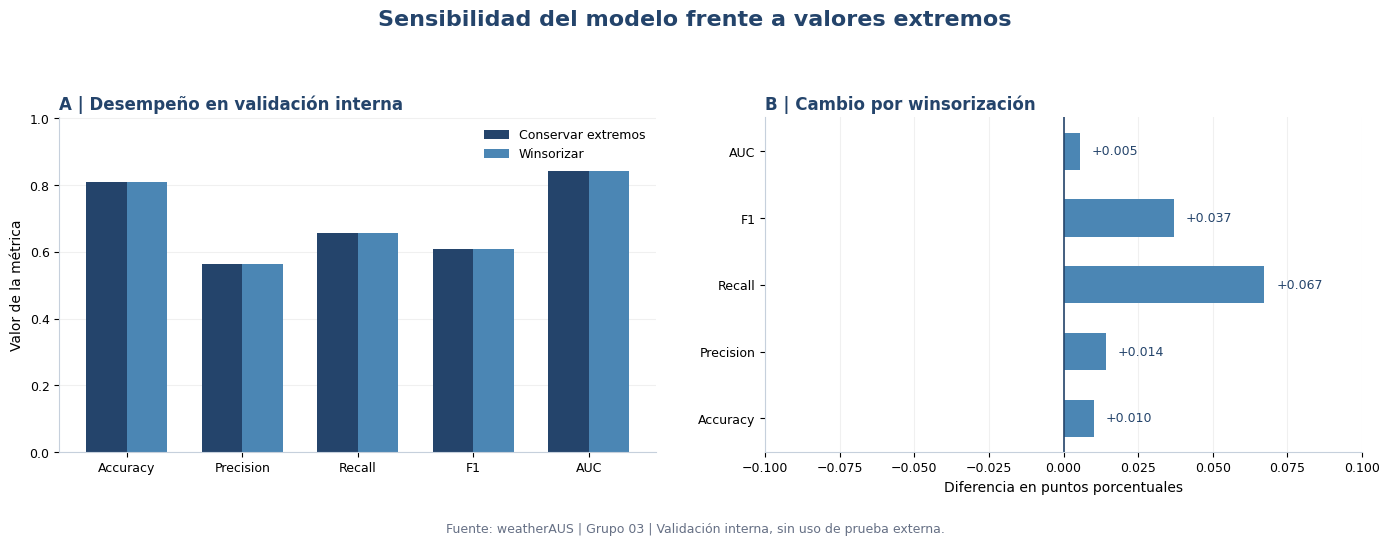

Validación correcta: sensibilidad evaluada sin utilizar el test externo.
Delta AUC (winsorización - referencia): 5e-05


In [13]:

# ============================================================
# 2.4.1. SENSIBILIDAD FRENTE A VALORES EXTREMOS
# Grupo 03 | Sumativa 3 | weatherAUS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from IPython.display import display, HTML

# ------------------------------------------------------------
# 1. CONFIGURACIÓN
# ------------------------------------------------------------

internal_cols = FEATURESETS[WINNER]

Xorig_fit = A_inner.iloc[ixfit][internal_cols].copy()
Xorig_val = A_inner.iloc[ixval][internal_cols].copy()

yorig_fit = ya.iloc[ixfit]
yorig_val = ya.iloc[ixval]

continuous = [
    v for v in internal_cols
    if v != "LluviaHoy_bin"
]

# ------------------------------------------------------------
# 2. PERCENTILES OBTENIDOS SOLO DEL ENTRENAMIENTO INTERNO
# ------------------------------------------------------------

qlo = Xorig_fit[continuous].quantile(0.005)
qhi = Xorig_fit[continuous].quantile(0.995)

Xwins_fit = Xorig_fit.copy()
Xwins_val = Xorig_val.copy()

Xwins_fit[continuous] = (
    Xwins_fit[continuous]
    .clip(lower=qlo, upper=qhi, axis=1)
)

Xwins_val[continuous] = (
    Xwins_val[continuous]
    .clip(lower=qlo, upper=qhi, axis=1)
)

# ------------------------------------------------------------
# 3. CUANTIFICAR LOS VALORES MODIFICADOS
# ------------------------------------------------------------

changes = pd.DataFrame([
    {
        "Variable": v,
        "P0.5% escalado": qlo[v],
        "P99.5% escalado": qhi[v],
        "N modificados train": int(
            Xorig_fit[v].ne(Xwins_fit[v]).sum()
        ),
        "% train": (
            100 * Xorig_fit[v].ne(Xwins_fit[v]).mean()
        ),
        "N modificados valid": int(
            Xorig_val[v].ne(Xwins_val[v]).sum()
        ),
        "% valid": (
            100 * Xorig_val[v].ne(Xwins_val[v]).mean()
        )
    }
    for v in continuous
])

# ------------------------------------------------------------
# 4. AJUSTAR DOS MODELOS PONDERADOS
# ------------------------------------------------------------

def logit_weighted():
    return LogisticRegression(
        max_iter=1000,
        solver="lbfgs",
        class_weight={0: 1, 1: POS_WEIGHT}
    )

# Escenario A: conservar extremos
ref_sens = logit_weighted().fit(
    Xorig_fit,
    yorig_fit
)

# Escenario B: winsorización suave
wins_sens = logit_weighted().fit(
    Xwins_fit,
    yorig_fit
)

# Predicciones exclusivamente en validación interna
prob_orig = ref_sens.predict_proba(
    Xorig_val
)[:, 1]

prob_wins = wins_sens.predict_proba(
    Xwins_val
)[:, 1]

# ------------------------------------------------------------
# 5. COMPARACIÓN PREDICTIVA
# ------------------------------------------------------------

res_sens = pd.DataFrame([
    {
        "Escenario": "Conservar extremos",
        **metrics(yorig_val, prob_orig)
    },
    {
        "Escenario": "Winsorizar 0.5–99.5%",
        **metrics(yorig_val, prob_wins)
    }
])

metric_names = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "AUC"
]

diferencias = pd.DataFrame([
    {
        "Métrica": m,
        "Original": res_sens.loc[0, m],
        "Winsorizado": res_sens.loc[1, m],
        "Diferencia": (
            res_sens.loc[1, m]
            - res_sens.loc[0, m]
        )
    }
    for m in metric_names
])

# ------------------------------------------------------------
# 6. PRESENTACIÓN PROFESIONAL DE TABLAS
# ------------------------------------------------------------

css = """
<style>
.panel-sensibilidad {
    font-family: Arial, sans-serif;
    max-width: 1200px;
    color: #243247;
}

.panel-sensibilidad h3 {
    font-size: 15px;
    color: #243247;
    margin: 18px 0 10px;
}

.panel-sensibilidad .resumen {
    background: #edf2f7;
    padding: 12px 16px;
    border-radius: 7px;
    line-height: 1.7;
    margin-bottom: 18px;
}

.panel-sensibilidad .tabla-scroll {
    overflow-x: auto;
    margin-bottom: 18px;
}

.panel-sensibilidad table {
    width: 100%;
    border-collapse: collapse;
    font-size: 12px;
}

.panel-sensibilidad th {
    background: #24446b;
    color: white;
    padding: 10px;
    text-align: left;
    white-space: nowrap;
}

.panel-sensibilidad td {
    padding: 9px;
    color: #222;
    border-bottom: 1px solid #d8dfe8;
}

.panel-sensibilidad tbody tr:nth-child(odd) {
    background: white;
}

.panel-sensibilidad tbody tr:nth-child(even) {
    background: #f3f6fa;
}

.panel-sensibilidad .nota {
    background: #edf2f7;
    padding: 12px;
    border-radius: 7px;
    font-size: 12px;
    line-height: 1.6;
    margin-top: 12px;
}
</style>
"""

def html_tabla_sens(tabla, decimales=4):
    vista = tabla.copy()

    for columna in vista.columns:
        if pd.api.types.is_float_dtype(vista[columna]):
            vista[columna] = vista[columna].map(
                lambda x: f"{x:.{decimales}f}"
            )

    return (
        '<div class="tabla-scroll">'
        + vista.to_html(index=False, border=0)
        + '</div>'
    )

html_final = f"""
{css}

<div class="panel-sensibilidad">

    <div class="resumen">
        <b>Análisis de sensibilidad a valores extremos</b><br>
        Modelo: {WINNER}<br>
        Escenarios evaluados: 2<br>
        Entrenamiento interno: {len(Xorig_fit):,} registros<br>
        Validación interna: {len(Xorig_val):,} registros<br>
        Winsorización: percentiles 0,5 % y 99,5 %
    </div>

    <h3>Tabla 1. Valores modificados por variable</h3>
    {html_tabla_sens(changes, 3)}

    <h3>Tabla 2. Desempeño de los escenarios</h3>
    {html_tabla_sens(res_sens, 4)}

    <h3>Tabla 3. Variación de métricas</h3>
    {html_tabla_sens(diferencias, 5)}

    <div class="nota">
        <b>Nota metodológica:</b><br>
        Los límites de winsorización provienen únicamente
        del entrenamiento interno y se aplican sin
        recalcularlos sobre validación.<br><br>
        Los dos modelos utilizan idénticos predictores,
        ponderación positiva de 2,23 y umbral de 0,50.
        Solo cambia el tratamiento de valores extremos.<br><br>
        Las diferencias corresponden a winsorización
        menos conservación de extremos.
        El conjunto externo de prueba no intervino.
    </div>

</div>
"""

display(HTML(html_final))

# ------------------------------------------------------------
# 7. GRÁFICOS COMPARATIVOS PROFESIONALES
# ------------------------------------------------------------

AZUL = "#24446B"
CELESTE = "#4B86B4"
NARANJA = "#D97732"
GRIS = "#667085"

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5),
    facecolor="white"
)

fig.suptitle(
    "Sensibilidad del modelo frente a valores extremos",
    fontsize=16,
    fontweight="bold",
    color=AZUL,
    y=1.03
)

# GRÁFICO A - COMPARACIÓN PREDICTIVA

ax = axes[0]

pos = np.arange(len(metric_names))
ancho = 0.35

val_orig = res_sens.loc[0, metric_names].astype(float)
val_wins = res_sens.loc[1, metric_names].astype(float)

ax.bar(
    pos - ancho/2,
    val_orig,
    width=ancho,
    color=AZUL,
    label="Conservar extremos"
)

ax.bar(
    pos + ancho/2,
    val_wins,
    width=ancho,
    color=CELESTE,
    label="Winsorizar"
)

ax.set_xticks(pos)
ax.set_xticklabels(metric_names)

ax.set_ylim(
    0,
    min(1.08, max(val_orig.max(), val_wins.max()) + 0.16)
)

ax.set_ylabel("Valor de la métrica")

ax.set_title(
    "A | Desempeño en validación interna",
    fontweight="bold",
    color=AZUL,
    loc="left"
)

ax.legend(
    frameon=False,
    fontsize=9
)

ax.grid(
    axis="y",
    alpha=0.18
)

ax.set_axisbelow(True)

# GRÁFICO B - CAMBIO EN MÉTRICAS

ax = axes[1]

deltas_pp = diferencias["Diferencia"].to_numpy() * 100

colores = [
    CELESTE if d >= 0 else NARANJA
    for d in deltas_pp
]

barras = ax.barh(
    metric_names,
    deltas_pp,
    color=colores,
    height=0.56
)

ax.axvline(
    0,
    color=AZUL,
    linewidth=1.2
)

ax.set_title(
    "B | Cambio por winsorización",
    fontweight="bold",
    color=AZUL,
    loc="left"
)

ax.set_xlabel("Diferencia en puntos porcentuales")

limite = max(0.1, np.max(np.abs(deltas_pp)) * 1.35)

ax.set_xlim(-limite, limite)

for barra, valor in zip(barras, deltas_pp):

    ax.text(
        valor + (0.04 * limite if valor >= 0
                 else -0.04 * limite),
        barra.get_y() + barra.get_height()/2,
        f"{valor:+.3f}",
        ha="left" if valor >= 0 else "right",
        va="center",
        fontsize=9,
        color=AZUL
    )

ax.grid(
    axis="x",
    alpha=0.18
)

ax.set_axisbelow(True)

# ESTILO GENERAL

for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#C6D0DC")
    ax.spines["bottom"].set_color("#C6D0DC")
    ax.tick_params(labelsize=9)

fig.text(
    0.5,
    -0.015,
    "Fuente: weatherAUS | Grupo 03 | "
    "Validación interna, sin uso de prueba externa.",
    ha="center",
    fontsize=9,
    color=GRIS
)

plt.tight_layout(
    rect=[0, 0.03, 1, 0.96],
    w_pad=3
)

plt.show()

# ------------------------------------------------------------
# 8. VERIFICACIONES FINALES
# ------------------------------------------------------------

assert len(res_sens) == 2
assert np.isfinite(
    res_sens[metric_names].to_numpy()
).all()

print(
    "Validación correcta: sensibilidad evaluada "
    "sin utilizar el test externo."
)

print(
    "Delta AUC (winsorización - referencia):",
    round(float(diferencias.loc[
        diferencias["Métrica"] == "AUC",
        "Diferencia"
    ].iloc[0]), 5)
)


### Interpretación de resultados y gráficos

La comparación muestra que la winsorización modificó menos del 1 % de los valores de cada predictor en entrenamiento y produjo cambios mínimos en el desempeño del modelo M3 Reducido BIC.

**Gráfico A – Comparación predictiva:** las barras presentan valores prácticamente iguales en ambos escenarios, evidenciando que conservar o limitar los valores extremos no modifica de manera relevante las métricas de clasificación.

**Gráfico B – Variación de métricas:** se observan pequeñas mejoras con winsorización en AUC (+0,00005), recall (+0,00067) y F1 (+0,00037). Estas diferencias son muy reducidas y no representan una mejora predictiva relevante.

**Conclusión:** el modelo presenta baja sensibilidad al tratamiento de valores extremos. Se recomienda conservar los valores originales, ya que las mejoras por winsorización son prácticamente nulas y los registros extremos pueden representar fenómenos meteorológicos reales.

### 2.4.2. Linealidad en el logit: evaluación de una alternativa flexible

La prueba exploratoria LR anterior no proporcionó evidencia estadística suficiente para rechazar la especificación lineal (p = 0,263662). No obstante, se evaluará una alternativa flexible con splines como análisis de sensibilidad predictiva, sin interpretar esta comparación como una prueba confirmatoria de no linealidad.

Para evaluar esta condición, se comparará el modelo **M3 Reducido BIC** con una regresión logística que incorpora *splines cúbicos* en las variables continuas, manteniendo `LluviaHoy_bin` sin transformar.

Los splines se ajustarán exclusivamente con entrenamiento interno y ambas alternativas se evaluarán en validación interna mediante AUC, F1-score y métricas de calibración, sin utilizar el conjunto externo de prueba.

**Objetivo:** determinar si una representación no lineal mejora el desempeño predictivo respecto del modelo logístico original.

**Criterio:** una mejora relevante justificaría explorar la alternativa flexible; de lo contrario, se favorecerá conservar M3 por su simplicidad e interpretabilidad.

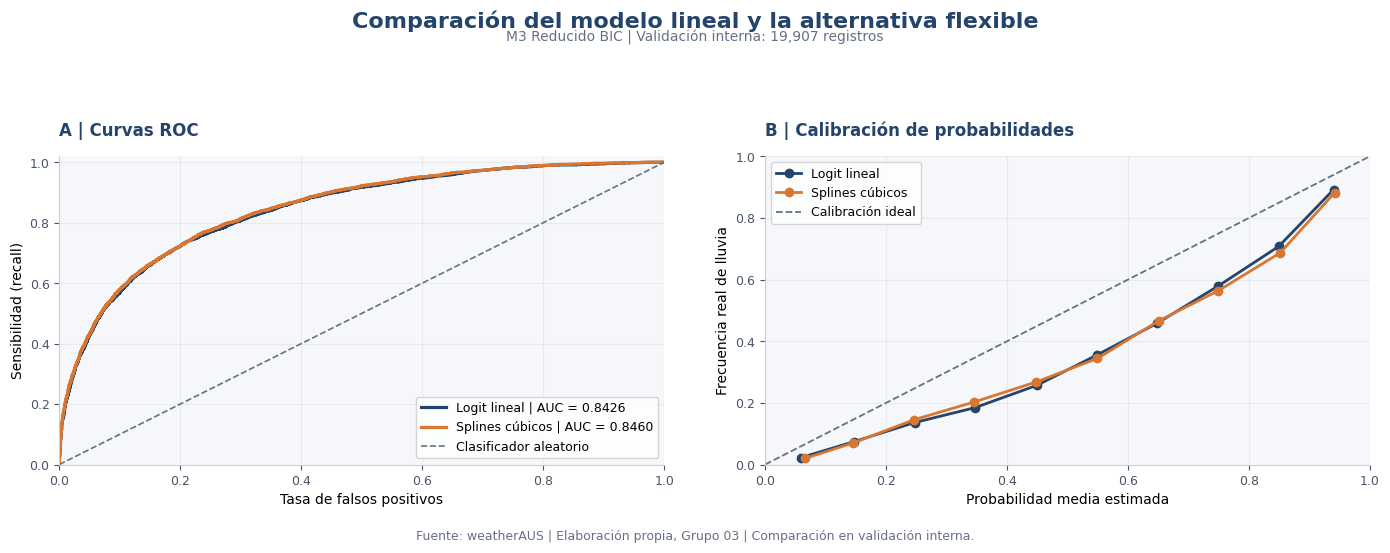

Validación correcta: comparación lineal vs. splines realizada sin utilizar el test externo.
Delta AUC (splines - lineal): 0.00334
Delta LogLoss (splines - lineal): -0.00307


In [14]:

# ============================================================
# 2.4.2. LINEALIDAD EN EL LOGIT: MODELO CON SPLINES
# Grupo 03 | Sumativa 3 | weatherAUS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from html import escape
from IPython.display import display, HTML
from sklearn.preprocessing import SplineTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_curve, roc_auc_score, log_loss,
    brier_score_loss
)

# ------------------------------------------------------------
# 1. CONFIGURACIÓN
# ------------------------------------------------------------

internal_cols = list(FEATURESETS[WINNER])

continuous = [
    c for c in internal_cols
    if c != "LluviaHoy_bin"
]

binary = [
    c for c in internal_cols
    if c == "LluviaHoy_bin"
]

# ------------------------------------------------------------
# 2. CONSTRUCCIÓN DEL MODELO CON SPLINES CÚBICOS
# ------------------------------------------------------------

transformers = [
    (
        "spline",
        SplineTransformer(
            n_knots=4,
            degree=3,
            include_bias=False,
            extrapolation="linear"
        ),
        continuous
    )
]

if binary:
    transformers.append(
        ("binary", "passthrough", binary)
    )

spline_pipeline = Pipeline([
    (
        "features",
        ColumnTransformer(
            transformers,
            remainder="drop"
        )
    ),
    (
        "logit",
        LogisticRegression(
            max_iter=1500,
            solver="lbfgs",
            class_weight={0: 1, 1: POS_WEIGHT},
            C=1.0
        )
    )
])

# Ajuste exclusivo en entrenamiento interno
spline_pipeline.fit(
    Xorig_fit,
    yorig_fit
)

# Evaluación en validación interna
prob_spline = spline_pipeline.predict_proba(
    Xorig_val
)[:, 1]

# Mantener la referencia lineal ya calculada
prob_lineal = np.asarray(prob_orig)

# ------------------------------------------------------------
# 3. EVALUACIÓN PREDICTIVA
# ------------------------------------------------------------

lineal_metrics = metrics(
    yorig_val,
    prob_lineal
)

spline_metrics = metrics(
    yorig_val,
    prob_spline
)

lineal_metrics["LogLoss"] = log_loss(
    yorig_val,
    prob_lineal
)

spline_metrics["LogLoss"] = log_loss(
    yorig_val,
    prob_spline
)

lineal_metrics["Brier"] = brier_score_loss(
    yorig_val,
    prob_lineal
)

spline_metrics["Brier"] = brier_score_loss(
    yorig_val,
    prob_spline
)

nonlinear_table = pd.DataFrame([
    {
        "Modelo": "Lineal en el logit",
        **lineal_metrics
    },
    {
        "Modelo": "Splines cúbicos + logística",
        **spline_metrics
    }
])

# ------------------------------------------------------------
# 4. DIFERENCIAS ENTRE MODELOS
# ------------------------------------------------------------

metric_names = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "AUC",
    "LogLoss",
    "Brier"
]

tabla_diferencias_spline = pd.DataFrame([
    {
        "Métrica": m,
        "Lineal": lineal_metrics[m],
        "Splines": spline_metrics[m],
        "Diferencia": (
            spline_metrics[m] - lineal_metrics[m]
        )
    }
    for m in metric_names
])

# ------------------------------------------------------------
# 5. PRESENTACIÓN PROFESIONAL DE TABLAS
# ------------------------------------------------------------

css = """
<style>
.panel-splines {
    font-family: Arial, sans-serif;
    max-width: 1250px;
    color: #243247;
}

.panel-splines .resumen {
    background: #edf2f7;
    padding: 12px 16px;
    border-radius: 7px;
    line-height: 1.7;
    margin-bottom: 18px;
    color: #243247;
}

.panel-splines h3 {
    font-size: 15px;
    color: #243247;
    margin: 18px 0 10px;
}

.panel-splines .tabla-scroll {
    overflow-x: auto;
    margin-bottom: 18px;
}

.panel-splines table {
    width: 100%;
    border-collapse: collapse;
    font-size: 12px;
}

.panel-splines th {
    background: #24446b;
    color: white;
    padding: 10px;
    text-align: left;
    white-space: nowrap;
}

.panel-splines td {
    padding: 9px;
    border-bottom: 1px solid #d8dfe8;
    color: #222;
}

.panel-splines tbody tr:nth-child(odd) {
    background: white;
}

.panel-splines tbody tr:nth-child(even) {
    background: #f3f6fa;
}

.panel-splines .nota {
    background: #edf2f7;
    color: #243247;
    padding: 12px;
    border-radius: 7px;
    font-size: 12px;
    line-height: 1.6;
}
</style>
"""

def tabla_html_spline(df, decimales=5):

    vista = df.copy()

    for col in vista.columns:
        if pd.api.types.is_float_dtype(vista[col]):
            vista[col] = vista[col].map(
                lambda x: f"{x:.{decimales}f}"
            )

    return (
        '<div class="tabla-scroll">'
        + vista.to_html(index=False, border=0)
        + '</div>'
    )

html_final = f"""
{css}

<div class="panel-splines">

    <div class="resumen">
        <b>Evaluación de linealidad en el logit</b><br>
        Modelo principal: {escape(WINNER)}<br>
        Alternativa: splines cúbicos de grado 3<br>
        Nudos por variable continua: 4<br>
        Peso de clase positiva: {POS_WEIGHT:.2f}<br>
        Observaciones de validación: {len(yorig_val):,}
    </div>

    <h3>Tabla 1. Comparación de desempeño</h3>
    {tabla_html_spline(nonlinear_table)}

    <h3>Tabla 2. Diferencias entre modelos</h3>
    {tabla_html_spline(tabla_diferencias_spline)}

    <div class="nota">
        <b>Nota metodológica:</b><br>
        La transformación spline se ajustó exclusivamente
        sobre el entrenamiento interno.
        La validación interna se mantuvo separada.<br><br>

        AUC, recall y F1 mayores indican mejor desempeño
        según sus respectivos criterios.
        LogLoss y Brier menores indican mejor calidad
        de las probabilidades estimadas.<br><br>

        Ambos modelos utilizan ponderación positiva
        de 2,23. Sus probabilidades pueden requerir
        calibración adicional para interpretarse
        como riesgos reales de lluvia.
        El conjunto externo de prueba no se utilizó.
    </div>

</div>
"""

display(HTML(html_final))

# ------------------------------------------------------------
# 6. GRÁFICOS PROFESIONALES
# ------------------------------------------------------------

AZUL = "#24446B"
CELESTE = "#3687B5"
NARANJA = "#D97732"
GRIS = "#667085"
FONDO = "#F5F7FA"

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5.2),
    facecolor="white"
)

fig.suptitle(
    "Comparación del modelo lineal y la alternativa flexible",
    fontsize=16,
    fontweight="bold",
    color=AZUL,
    y=1.025
)

fig.text(
    0.5, 0.965,
    f"{WINNER} | Validación interna: {len(yorig_val):,} registros",
    ha="center",
    fontsize=10,
    color=GRIS
)

# ------------------------------------------------------------
# GRÁFICO A: CURVAS ROC
# ------------------------------------------------------------

ax = axes[0]
ax.set_facecolor(FONDO)

for etiqueta, probabilidad, color in [
    ("Logit lineal", prob_lineal, AZUL),
    ("Splines cúbicos", prob_spline, NARANJA)
]:

    fpr, tpr, _ = roc_curve(
        yorig_val,
        probabilidad
    )

    auc = roc_auc_score(
        yorig_val,
        probabilidad
    )

    ax.plot(
        fpr,
        tpr,
        linewidth=2.3,
        color=color,
        label=f"{etiqueta} | AUC = {auc:.4f}"
    )

ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color=GRIS,
    linewidth=1.2,
    label="Clasificador aleatorio"
)

ax.set_title(
    "A | Curvas ROC",
    loc="left",
    fontweight="bold",
    color=AZUL,
    pad=15
)

ax.set_xlabel("Tasa de falsos positivos")
ax.set_ylabel("Sensibilidad (recall)")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.grid(alpha=0.18)
ax.legend(fontsize=9, frameon=True)

# ------------------------------------------------------------
# GRÁFICO B: CALIBRACIÓN DE PROBABILIDADES
# ------------------------------------------------------------

ax = axes[1]
ax.set_facecolor(FONDO)

def puntos_calibracion(y, p, n_bins=10, minimo=30):

    y = np.asarray(y).astype(int)
    p = np.asarray(p, dtype=float)

    bordes = np.linspace(0, 1, n_bins + 1)

    indices = np.clip(
        np.digitize(p, bordes) - 1,
        0,
        n_bins - 1
    )

    estimadas = []
    observadas = []

    for k in range(n_bins):

        mask = indices == k

        if mask.sum() >= minimo:
            estimadas.append(p[mask].mean())
            observadas.append(y[mask].mean())

    return np.array(estimadas), np.array(observadas)

for etiqueta, probabilidad, color in [
    ("Logit lineal", prob_lineal, AZUL),
    ("Splines cúbicos", prob_spline, NARANJA)
]:

    xx, yy = puntos_calibracion(
        yorig_val,
        probabilidad
    )

    ax.plot(
        xx,
        yy,
        marker="o",
        markersize=6,
        linewidth=2,
        color=color,
        label=etiqueta
    )

ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color=GRIS,
    linewidth=1.3,
    label="Calibración ideal"
)

ax.set_title(
    "B | Calibración de probabilidades",
    loc="left",
    fontweight="bold",
    color=AZUL,
    pad=15
)

ax.set_xlabel("Probabilidad media estimada")
ax.set_ylabel("Frecuencia real de lluvia")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.grid(alpha=0.18)
ax.legend(fontsize=9, frameon=True)

# ------------------------------------------------------------
# 7. ESTILO FINAL
# ------------------------------------------------------------

for ax in axes:

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.spines["left"].set_color("#C6D0DC")
    ax.spines["bottom"].set_color("#C6D0DC")

    ax.tick_params(
        labelsize=9,
        colors="#475467"
    )

    ax.set_axisbelow(True)

fig.text(
    0.5,
    0.005,
    "Fuente: weatherAUS | Elaboración propia, Grupo 03 | "
    "Comparación en validación interna.",
    ha="center",
    fontsize=9,
    color=GRIS
)

plt.tight_layout(
    rect=[0, 0.04, 1, 0.91],
    w_pad=3
)

plt.show()

# ------------------------------------------------------------
# 8. VERIFICACIÓN FINAL
# ------------------------------------------------------------

assert len(prob_spline) == len(yorig_val)
assert np.isfinite(prob_spline).all()
assert np.isfinite(prob_lineal).all()

print(
    "Validación correcta: comparación lineal vs. "
    "splines realizada sin utilizar el test externo."
)

print(
    "Delta AUC (splines - lineal):",
    round(
        spline_metrics["AUC"]
        - lineal_metrics["AUC"],
        5
    )
)

print(
    "Delta LogLoss (splines - lineal):",
    round(
        spline_metrics["LogLoss"]
        - lineal_metrics["LogLoss"],
        5
    )
)


###  Interpretación de resultados y gráficos

La regresión logística con splines cúbicos mejoró ligeramente el AUC de **0,84262 a 0,84595** y redujo el LogLoss de 0,42591 a 0,42285. Sin embargo, el recall disminuyó de 0,65651 a 0,64531, mientras que el F1-score prácticamente no cambió.

**Gráfico A – Curvas ROC:** el modelo con splines presenta una discriminación ligeramente superior, aunque la diferencia entre ambas curvas es reducida (ΔAUC = +0,00334).

**Gráfico B – Calibración:** el modelo con splines obtuvo menores valores de LogLoss y Brier (0,13400 frente a 0,13594), lo que indica una mejora moderada en la calidad global de las probabilidades estimadas. Sin embargo, ambos modelos pueden presentar desviaciones de calibración debido a la ponderación de clases.

**Conclusión:** los splines permiten capturar relaciones no lineales y mejorar ligeramente algunas métricas, pero disminuyen la sensibilidad para detectar días lluviosos. Se mantiene **M3 Reducido BIC** como modelo principal por su simplicidad, interpretabilidad y mayor recall, dejando la alternativa flexible como una posibilidad de mejora futura.

## 2.5. Evaluación de Desempeño 

### Introducción

En esta etapa se evalúa el desempeño de los tres modelos de regresión logística mediante las métricas accuracy, precision, recall, F1-score y AUC-ROC, utilizando los conjuntos de entrenamiento y prueba previamente definidos.

Se incorporan matrices de confusión y curvas ROC para analizar la capacidad de discriminación y los errores de clasificación, especialmente los falsos negativos asociados con días lluviosos no detectados.

Se mantiene **M3 Reducido BIC** como modelo principal, seleccionado mediante validación interna, y se compara descriptivamente su desempeño con el modelo histórico F3.

**Objetivo:** evaluar la capacidad predictiva, generalización y limitaciones de los modelos, prestando especial atención al recall de la clase positiva y al equilibrio entre detección de lluvia y falsas alarmas.

### Guía de ejecución 6.2. Matrices de confusión y curvas ROC

En esta etapa se evalúa el desempeño de los modelos **M1 S1/S2, M2 Stepwise AIC y M3 Reducido BIC** mediante matrices de confusión y curvas ROC, utilizando las particiones de entrenamiento y prueba externa.

Se construirán seis matrices de confusión para identificar verdaderos positivos, verdaderos negativos, falsos positivos y falsos negativos. Asimismo, se compararán las curvas ROC y sus respectivos valores AUC para analizar la capacidad de discriminación.

El análisis considera especialmente el **recall de la clase positiva (lluvia)**, debido a que la exactitud global puede ocultar dificultades para identificar correctamente los días lluviosos.

**Objetivo:** comparar la capacidad predictiva y los errores de clasificación de los tres modelos, verificando su generalización y contrastando descriptivamente los resultados con el modelo histórico F3.

**Consideración metodológica:** las métricas de F3 corresponden a una evaluación anterior, por lo que sus diferencias con los modelos actuales no pueden atribuirse exclusivamente a la selección de predictores.

Modelo,Partición,Registros,VN,FP,FN,VP,Accuracy,Precision,Recall,F1,AUC
M1 S1/S2,Entrenamiento,99535,66120,11101,8256,14058,0.8055,0.5588,0.6300,0.5923,0.8282
M1 S1/S2,Prueba externa,42658,28353,4742,3511,6052,0.8065,0.5607,0.6329,0.5946,0.8289
M2 Stepwise AIC,Entrenamiento,99535,66094,11127,7800,14514,0.8098,0.5660,0.6504,0.6053,0.8416
M2 Stepwise AIC,Prueba externa,42658,28333,4762,3289,6274,0.8113,0.5685,0.6561,0.6092,0.8418
M3 Reducido BIC,Entrenamiento,99535,66148,11073,7776,14538,0.8106,0.5676,0.6515,0.6067,0.8410
M3 Reducido BIC,Prueba externa,42658,28352,4743,3296,6267,0.8115,0.5692,0.6553,0.6092,0.8408


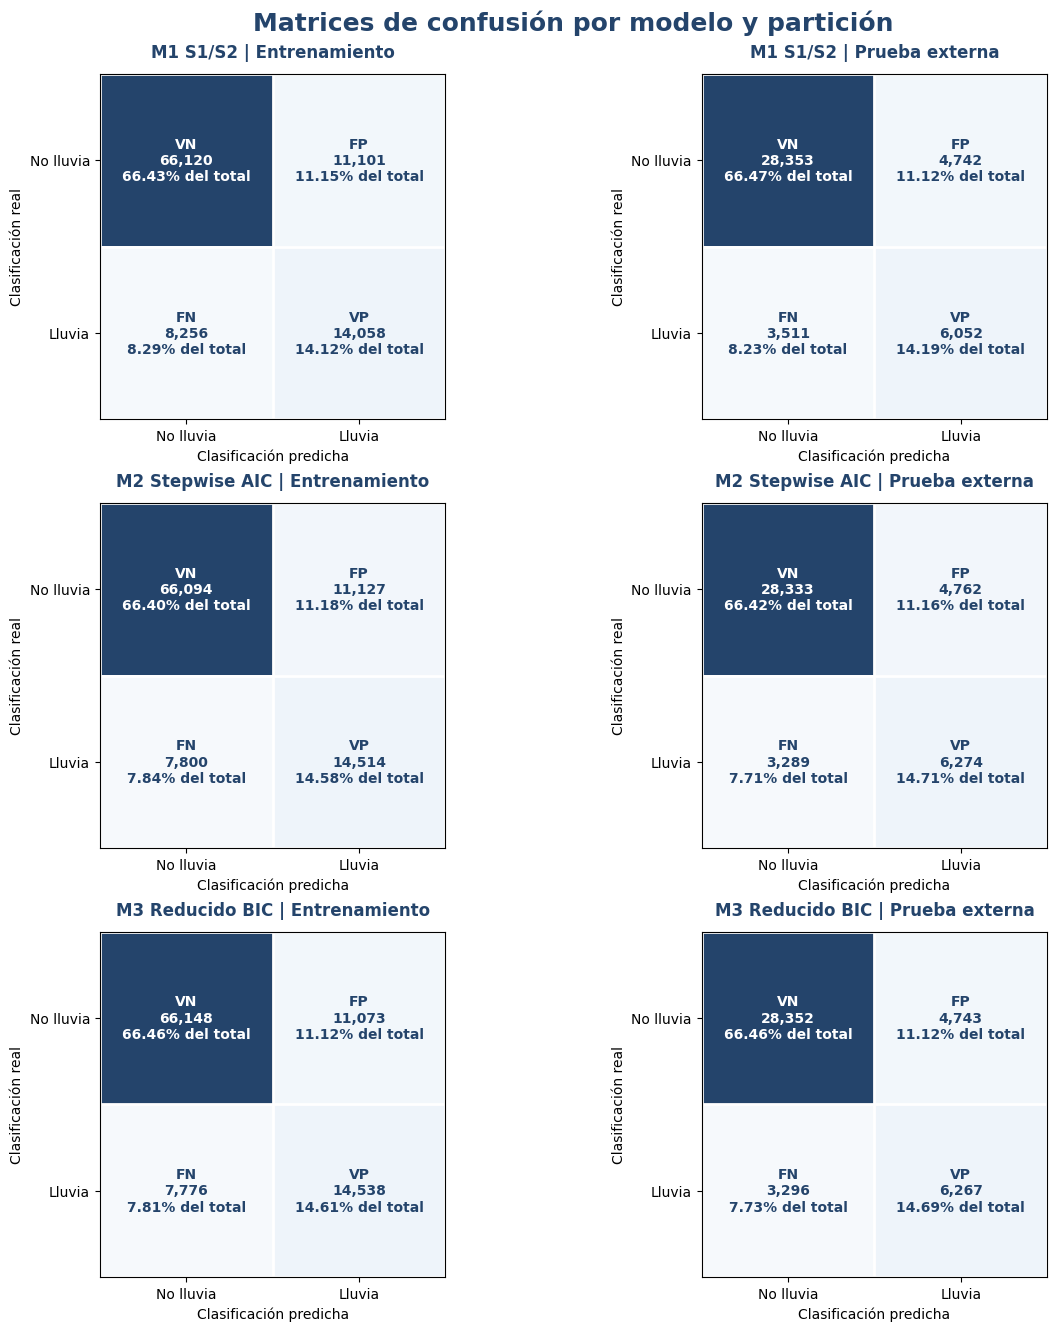

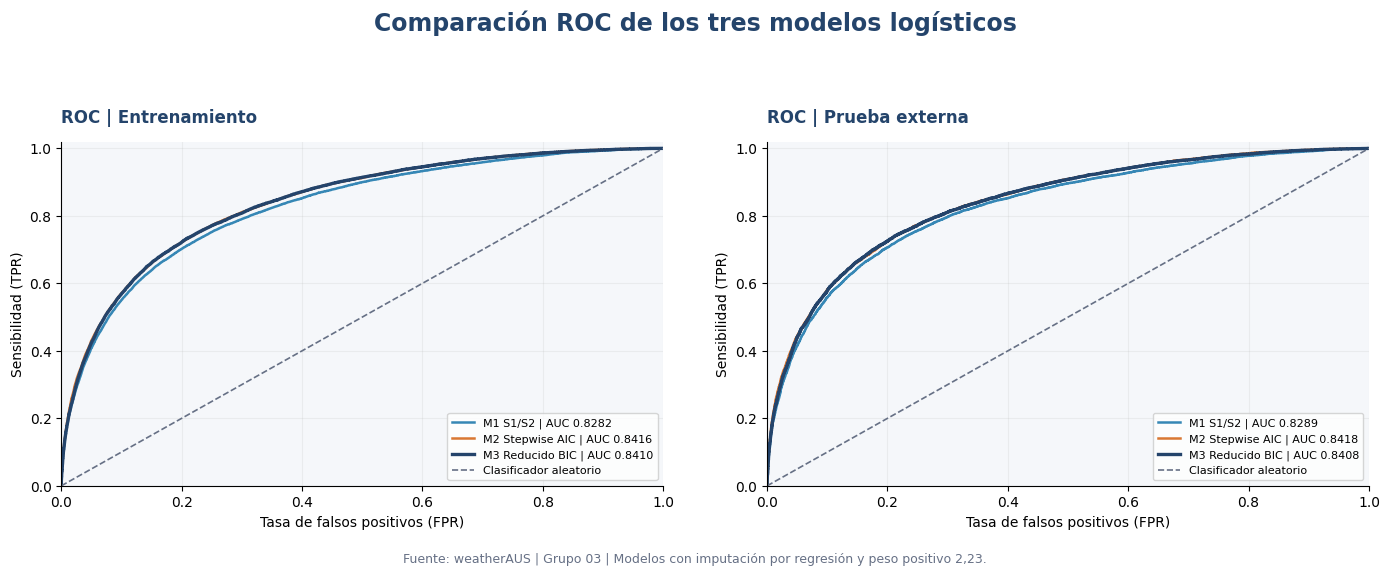

Validación correcta: seis matrices de confusión y curvas ROC generadas.
Modelo principal seleccionado: M3 Reducido BIC
Recall del modelo principal en prueba externa: 0.6553
AUC del modelo principal en prueba externa: 0.8408


In [15]:

# ============================================================
# 2.5. EVALUACIÓN DE DESEMPEÑO
# Guía 6.2 | Grupo 03 | Sumativa 3 | weatherAUS
# Matrices de confusión, métricas y curvas ROC
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import PercentFormatter
from sklearn.metrics import (
    confusion_matrix,
    roc_curve,
    roc_auc_score
)
from IPython.display import display, HTML
from html import escape

# ------------------------------------------------------------
# 1. CONFIGURACIÓN VISUAL Y ESTADÍSTICA
# ------------------------------------------------------------

THRESHOLD = 0.50

AZUL = "#24446B"
CELESTE = "#3687B5"
NARANJA = "#D97732"
VERDE = "#238476"
GRIS = "#667085"
FONDO = "#F5F7FA"

colores_modelos = {
    "M1 S1/S2": CELESTE,
    "M2 Stepwise AIC": NARANJA,
    "M3 Reducido BIC": AZUL
}

orden_modelos = list(models.keys())

nombres_split = {
    "Train": "Entrenamiento",
    "Test": "Prueba externa"
}

# ------------------------------------------------------------
# 2. MÉTRICAS Y MATRICES DE CONFUSIÓN
# ------------------------------------------------------------

filas_metricas = []
matrices = {}

for name in orden_modelos:

    for split, truth in [
        ("Train", ya),
        ("Test", yb)
    ]:

        p = np.asarray(probs[name][split])
        y = np.asarray(truth).astype(int)

        pred = (p >= THRESHOLD).astype(int)

        cm = confusion_matrix(
            y,
            pred,
            labels=[0, 1]
        )

        matrices[(name, split)] = cm

        vn, fp, fn, vp = cm.ravel()

        resultado = metrics(
            y,
            p,
            threshold=THRESHOLD
        )

        filas_metricas.append({
            "Modelo": name,
            "Partición": nombres_split[split],
            "Registros": len(y),
            "VN": int(vn),
            "FP": int(fp),
            "FN": int(fn),
            "VP": int(vp),
            **resultado
        })

tabla_desempeno = pd.DataFrame(filas_metricas)

# ------------------------------------------------------------
# 3. TABLA PROFESIONAL DE MÉTRICAS
# ------------------------------------------------------------

css = """
<style>
.panel-evaluacion {
    font-family: Arial, sans-serif;
    max-width: 1250px;
    color: #243247;
}

.panel-evaluacion .resumen {
    background: #edf2f7;
    color: #243247;
    padding: 12px 16px;
    border-radius: 7px;
    margin-bottom: 18px;
    line-height: 1.7;
}

.panel-evaluacion h3 {
    font-size: 15px;
    color: #243247;
    margin: 17px 0 10px;
}

.panel-evaluacion .tabla-scroll {
    overflow-x: auto;
    margin-bottom: 18px;
}

.panel-evaluacion table {
    width: 100%;
    border-collapse: collapse;
    font-size: 12px;
}

.panel-evaluacion th {
    background: #24446b;
    color: white;
    text-align: left;
    padding: 10px;
    white-space: nowrap;
}

.panel-evaluacion td {
    padding: 9px;
    border-bottom: 1px solid #d8dfe8;
    color: #222;
}

.panel-evaluacion tbody tr:nth-child(odd) {
    background: white;
}

.panel-evaluacion tbody tr:nth-child(even) {
    background: #f3f6fa;
}

.panel-evaluacion tr.destacado td {
    background: #e9f3fb;
    font-weight: bold;
}

.panel-evaluacion .nota {
    background: #edf2f7;
    color: #243247;
    padding: 12px;
    border-radius: 7px;
    font-size: 12px;
    line-height: 1.6;
}
</style>
"""

def tabla_html_evaluacion(df):

    vista = df.copy()

    columnas_metricas = [
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "AUC"
    ]

    for col in columnas_metricas:
        vista[col] = vista[col].map(
            lambda x: f"{x:.4f}"
        )

    partes = [
        '<div class="tabla-scroll"><table>',
        "<thead><tr>"
    ]

    for columna in vista.columns:
        partes.append(
            f"<th>{escape(str(columna))}</th>"
        )

    partes.append("</tr></thead><tbody>")

    for _, fila in vista.iterrows():

        clase = (
            ' class="destacado"'
            if fila["Modelo"] == WINNER
            else ""
        )

        partes.append(f"<tr{clase}>")

        for valor in fila:
            partes.append(
                f"<td>{escape(str(valor))}</td>"
            )

        partes.append("</tr>")

    partes.append("</tbody></table></div>")

    return "".join(partes)

html_final = f"""
{css}

<div class="panel-evaluacion">

    <div class="resumen">
        <b>Evaluación final de modelos logísticos</b><br>
        Modelos analizados: {len(orden_modelos)}<br>
        Modelo principal: {escape(WINNER)}<br>
        Umbral de clasificación: {THRESHOLD:.2f}<br>
        Clase positiva: lluvia al día siguiente<br>
        Conjunto externo de prueba: {len(yb):,} registros
    </div>

    <h3>Tabla 1. Métricas y errores de clasificación</h3>
    {tabla_html_evaluacion(tabla_desempeno)}

    <div class="nota">
        <b>Interpretación de la matriz:</b><br>
        VN: días sin lluvia correctamente identificados.<br>
        FP: falsas alarmas de lluvia.<br>
        FN: días lluviosos no detectados.<br>
        VP: días lluviosos correctamente identificados.<br><br>

        La selección de {escape(WINNER)} se realizó
        previamente mediante validación interna.
        Las métricas de prueba externa se utilizan
        para la evaluación final, no para volver
        a seleccionar el modelo.
    </div>

</div>
"""

display(HTML(html_final))

# ------------------------------------------------------------
# 4. FIGURA 1: SEIS MATRICES DE CONFUSIÓN
# ------------------------------------------------------------

cmap_azul = LinearSegmentedColormap.from_list(
    "azul_academico",
    ["#FFFFFF", "#D9E7F4", AZUL]
)

fig, axes = plt.subplots(
    len(orden_modelos),
    2,
    figsize=(12, 4.4 * len(orden_modelos)),
    facecolor="white",
    constrained_layout=True
)

axes = np.asarray(axes).reshape(
    len(orden_modelos),
    2
)

fig.suptitle(
    "Matrices de confusión por modelo y partición",
    fontsize=18,
    fontweight="bold",
    color=AZUL
)

etiquetas_celdas = np.array([
    ["VN", "FP"],
    ["FN", "VP"]
])

for j, name in enumerate(orden_modelos):

    for k, split in enumerate(["Train", "Test"]):

        ax = axes[j, k]
        cm = matrices[(name, split)]

        total = cm.sum()
        porcentajes = 100 * cm / total

        ax.imshow(
            cm,
            cmap=cmap_azul,
            vmin=0,
            vmax=cm.max() if cm.max() else 1
        )

        ax.set_title(
            f"{name} | {nombres_split[split]}",
            fontsize=12,
            fontweight="bold",
            color=AZUL,
            pad=12
        )

        ax.set_xticks([0, 1])
        ax.set_yticks([0, 1])

        ax.set_xticklabels([
            "No lluvia",
            "Lluvia"
        ])

        ax.set_yticklabels([
            "No lluvia",
            "Lluvia"
        ])

        ax.set_xlabel(
            "Clasificación predicha",
            fontsize=10
        )

        ax.set_ylabel(
            "Clasificación real",
            fontsize=10
        )

        # Texto de cada celda
        for fila in range(2):

            for columna in range(2):

                cantidad = int(cm[fila, columna])
                porcentaje = porcentajes[fila, columna]

                color_texto = (
                    "white"
                    if cantidad > cm.max() * 0.55
                    else AZUL
                )

                ax.text(
                    columna,
                    fila,
                    (
                        f"{etiquetas_celdas[fila, columna]}\n"
                        f"{cantidad:,}\n"
                        f"{porcentaje:.2f}% del total"
                    ),
                    ha="center",
                    va="center",
                    fontsize=10,
                    fontweight="bold",
                    color=color_texto
                )

        # Separadores entre las cuatro celdas
        ax.set_xticks(
            np.arange(-0.5, 2, 1),
            minor=True
        )

        ax.set_yticks(
            np.arange(-0.5, 2, 1),
            minor=True
        )

        ax.grid(
            which="minor",
            color="white",
            linewidth=2
        )

        ax.tick_params(
            which="minor",
            bottom=False,
            left=False
        )

        ax.tick_params(labelsize=10)

plt.show()

# ------------------------------------------------------------
# 5. FIGURA 2: CURVAS ROC - TRAIN Y TEST
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5.4),
    facecolor="white"
)

fig.suptitle(
    "Comparación ROC de los tres modelos logísticos",
    fontsize=17,
    fontweight="bold",
    color=AZUL,
    y=1.03
)

for ax, (split, truth) in zip(
    axes,
    [("Train", ya), ("Test", yb)]
):

    ax.set_facecolor(FONDO)

    for name in orden_modelos:

        p = probs[name][split]

        fpr, tpr, _ = roc_curve(
            truth,
            p
        )

        auc = roc_auc_score(
            truth,
            p
        )

        ax.plot(
            fpr,
            tpr,
            linewidth=2.4 if name == WINNER else 1.8,
            color=colores_modelos.get(name, AZUL),
            label=f"{name} | AUC {auc:.4f}"
        )

    ax.plot(
        [0, 1], [0, 1],
        color=GRIS,
        linestyle="--",
        linewidth=1.2,
        label="Clasificador aleatorio"
    )

    ax.set_title(
        f"ROC | {nombres_split[split]}",
        fontsize=12,
        fontweight="bold",
        color=AZUL,
        loc="left",
        pad=14
    )

    ax.set_xlabel(
        "Tasa de falsos positivos (FPR)"
    )

    ax.set_ylabel(
        "Sensibilidad (TPR)"
    )

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)

    ax.grid(alpha=0.17)

    ax.legend(
        fontsize=8,
        loc="lower right",
        frameon=True
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.text(
    0.5,
    0.005,
    "Fuente: weatherAUS | Grupo 03 | "
    "Modelos con imputación por regresión y peso positivo 2,23.",
    ha="center",
    fontsize=9,
    color=GRIS
)

plt.tight_layout(
    rect=[0, 0.04, 1, 0.95],
    w_pad=3
)

plt.show()

# ------------------------------------------------------------
# 6. VERIFICACIÓN FINAL
# ------------------------------------------------------------

assert len(matrices) == 2 * len(orden_modelos)

for name in orden_modelos:

    for split, truth in [
        ("Train", ya),
        ("Test", yb)
    ]:

        assert matrices[(name, split)].sum() == len(truth)

print(
    "Validación correcta: seis matrices de confusión "
    "y curvas ROC generadas."
)

print(
    "Modelo principal seleccionado:",
    WINNER
)

print(
    "Recall del modelo principal en prueba externa:",
    f"{metrics_by_split[(WINNER, 'Test')]['Recall']:.4f}"
)

print(
    "AUC del modelo principal en prueba externa:",
    f"{metrics_by_split[(WINNER, 'Test')]['AUC']:.4f}"
)


### Interpretación de resultados y gráficos

**1. Tabla 1 – Métricas de desempeño**

Los tres modelos presentan resultados similares entre entrenamiento y prueba externa, sin evidenciar diferencias importantes que sugieran sobreajuste.

En prueba externa, **M1 S1/S2** obtuvo un AUC de 0,8289 y recall de 0,6329, mostrando el menor desempeño de discriminación. **M2 Stepwise AIC** alcanzó el mayor AUC (0,8418) y recall (0,6561). Por su parte, **M3 Reducido BIC** obtuvo accuracy de 0,8115, precision de 0,5692, recall de 0,6553, F1 de 0,6092 y AUC de 0,8408, con solo cinco predictores.

**2. Gráfico 1 – Matrices de confusión**

Las matrices permiten identificar los aciertos y errores de clasificación de cada modelo.

- **M1:** detectó 6.052 días lluviosos, omitió 3.511 y generó 4.742 falsas alarmas.
- **M2:** detectó 6.274 días lluviosos, omitió 3.289 y generó 4.762 falsas alarmas.
- **M3:** detectó 6.267 días lluviosos, omitió 3.296 y generó 4.743 falsas alarmas.

Los resultados muestran que M2 y M3 reducen los falsos negativos respecto de M1. La diferencia entre ambos es mínima: M2 identifica siete días lluviosos adicionales, pero produce 19 falsas alarmas más.

**3. Gráfico 2 – Curvas ROC**

Las curvas ROC muestran la capacidad de los modelos para distinguir días lluviosos y no lluviosos a distintos umbrales de clasificación.

En prueba externa, M2 presenta el mayor AUC (0,8418), seguido muy de cerca por M3 (0,8408), mientras que M1 alcanza 0,8289. La similitud entre las curvas de entrenamiento y prueba externa es consistente con un desempeño estable en las particiones evaluadas.

### Conclusión final

Los modelos M2 y M3 presentan mejor capacidad de discriminación y detección de lluvia que M1. Aunque M2 obtiene un AUC y recall ligeramente superiores, **M3 Reducido BIC mantiene un desempeño prácticamente equivalente utilizando cinco variables en lugar de ocho**.

Se conserva M3 como modelo principal, de acuerdo con su selección previa mediante validación interna, su menor complejidad y sus resultados en prueba externa.

**Su principal fortaleza es detectar el 65,53 % de los días lluviosos**, aunque todavía no identifica el 34,47 % de ellos y genera 4.743 falsas alarmas. Por tanto, constituye una alternativa predictiva competitiva, pero requiere considerar estos errores antes de utilizarse para decisiones operacionales.

## Parte 3. Análisis comparativo del impacto de la imputación 

### Introducción

En esta etapa se evalúa cómo las tres estrategias de tratamiento de datos faltantes —**eliminación, mediana y regresión lineal múltiple**— afectan el desempeño y la interpretación del modelo logístico seleccionado, **M3 Reducido BIC**.

Se mantienen los mismos cinco predictores y la ponderación positiva de 2,23, comparando el tamaño muestral, los coeficientes, los *odds ratios* (OR), sus intervalos de confianza y las métricas predictivas.

Adicionalmente, se realiza una evaluación sobre un **subconjunto común de casos completos**, para distinguir las diferencias asociadas con la composición de las muestras de aquellas relacionadas con el ajuste de cada modelo.

**Objetivo:** determinar el impacto del tratamiento de valores faltantes sobre la estabilidad estadística y la capacidad predictiva del modelo, identificando las ventajas y limitaciones de cada estrategia.

### Guía de ejecución 9. Impacto de las estrategias de imputación

En esta etapa se ajusta el modelo **M3 Reducido BIC** utilizando las tres estrategias de tratamiento de datos faltantes: eliminación, mediana y regresión lineal múltiple.

Se comparan los tamaños muestrales, coeficientes, *odds ratios* (OR), intervalos de confianza y métricas predictivas, manteniendo los mismos cinco predictores y la ponderación positiva de 2,23.

El análisis considera dos evaluaciones:

- **Prueba propia de cada estrategia:** permite evaluar el desempeño sobre los registros disponibles después de aplicar cada tratamiento.
- **Prueba común de 35.885 observaciones completas:** permite comparar los tres modelos sobre exactamente los mismos registros, evitando confundir diferencias de desempeño con diferencias en la composición de la muestra de evaluación.

**Objetivo:** determinar cómo las estrategias de imputación influyen en el desempeño y la interpretación del modelo logístico, considerando tanto la conservación de información como la comparabilidad de los resultados.

**Consideración metodológica:** aunque la prueba común permite una comparación más consistente, los modelos se entrenan sobre conjuntos de distinto tamaño. Por ello, las diferencias no pueden atribuirse exclusivamente al método de imputación.

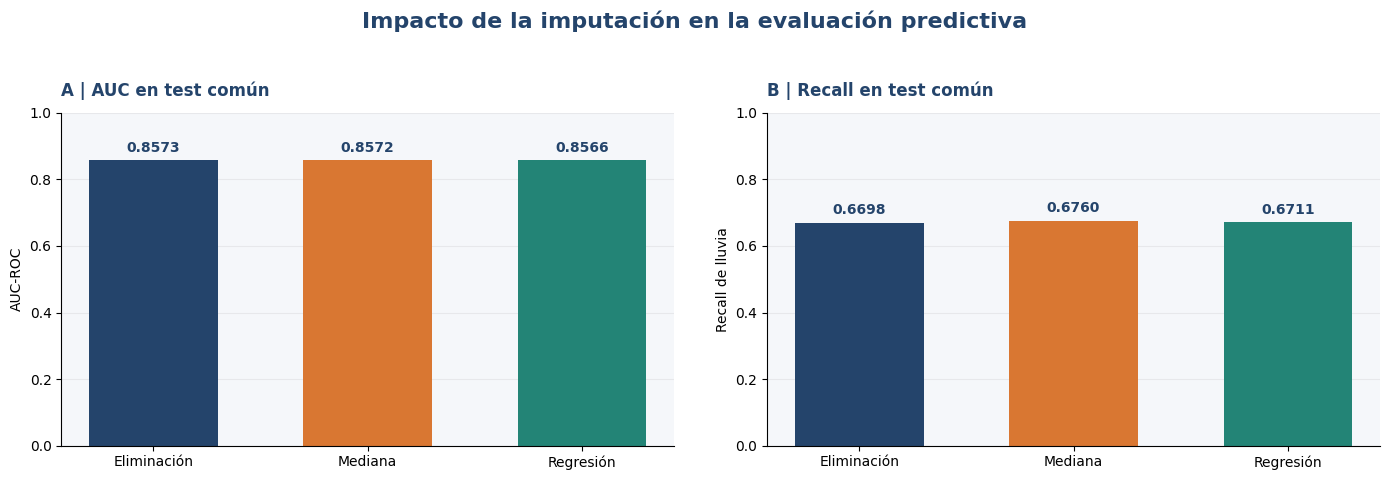

Comparación emparejada realizada correctamente.
Test común: 35,885 registros (84.12% del total).
Diferencia máxima entre AUC en test común: 0.00063
El test externo se utilizó para evaluación, no para reentrenar los modelos.


In [16]:

# ==============================================================
# PARTE 3 | GUÍA 9
# IMPACTO DE LAS ESTRATEGIAS DE IMPUTACIÓN
# Grupo 03 - Sumativa 3 - weatherAUS
# ==============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

from html import escape
from IPython.display import display, HTML
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# --------------------------------------------------------------
# 1. CONFIGURACIÓN
# --------------------------------------------------------------

AZUL = "#24446B"
CELESTE = "#3687B5"
NARANJA = "#D97732"
VERDE = "#238476"
GRIS = "#667085"

COLORES = {
    "Eliminación": AZUL,
    "Mediana": NARANJA,
    "Regresión": VERDE
}

variables_continuas = [
    v for v in cols
    if v != "LluviaHoy_bin"
]

imputation_results = []
coef_tables = []
strat_probs = {}
strat_models = {}

# --------------------------------------------------------------
# 2. ENTRENAMIENTO Y EVALUACIÓN POR ESTRATEGIA
# --------------------------------------------------------------

for strat, (ta, tb) in strategies.items():

    # Estandarización ajustada SOLO con train
    scaler = StandardScaler().fit(
        ta[variables_continuas]
    )

    xa = ta[cols].copy()
    xb = tb[cols].copy()

    xa[variables_continuas] = scaler.transform(
        xa[variables_continuas]
    )

    xb[variables_continuas] = scaler.transform(
        xb[variables_continuas]
    )

    # Modelo predictivo ponderado
    lm = LogisticRegression(
        max_iter=600,
        solver="lbfgs",
        class_weight={0: 1, 1: POS_WEIGHT},
        random_state=42
    )

    lm.fit(
        xa,
        ta[TARGET]
    )

    strat_models[strat] = lm

    pp = lm.predict_proba(xb)[:, 1]

    strat_probs[strat] = pd.Series(
        pp,
        index=tb.index
    )

    resultado = metrics(
        tb[TARGET],
        pp
    )

    imputation_results.append({
        "Imputación": strat,
        "N train": len(ta),
        "N test": len(tb),
        "Cobertura test (%)": (
            100 * len(tb) / len(test)
        ),
        **resultado
    })

    # Modelo de inferencia NO ponderado
    # Separado del clasificador predictivo
    inf = sm.Logit(
        ta[TARGET],
        sm.add_constant(
            xa,
            has_constant="add"
        )
    ).fit(
        disp=0,
        maxiter=120
    )

    ci = inf.conf_int()

    for v in cols:

        beta = inf.params[v]

        coef_tables.append({
            "Estrategia": strat,
            "Variable": v,
            "Beta": beta,
            "OR": np.exp(beta),
            "IC95_OR_inf": np.exp(ci.loc[v, 0]),
            "IC95_OR_sup": np.exp(ci.loc[v, 1])
        })

# --------------------------------------------------------------
# 3. TABLAS DE RESULTADOS
# --------------------------------------------------------------

tabla_imputacion = pd.DataFrame(
    imputation_results
)

tabla_coeficientes = pd.DataFrame(
    coef_tables
)

# Subconjunto común: intersección de los índices disponibles
# en TODAS las estrategias de evaluación

common = test.index

for _, (_, tb) in strategies.items():
    common = common.intersection(
        tb.index,
        sort=False
    )

common = test.index[
    test.index.isin(common)
]

y_common = test.loc[
    common,
    TARGET
]

paired = []

for name, pp in strat_probs.items():

    prob_common = pp.loc[common]

    resultado = metrics(
        y_common,
        prob_common
    )

    paired.append({
        "Estrategia": name,
        "N test común": len(common),
        "Cobertura test (%)": (
            100 * len(common) / len(test)
        ),
        **resultado
    })

tabla_pareada = pd.DataFrame(paired)

# Comparación de diferencias respecto de la estrategia
# de regresión, en el MISMO test común

referencia = tabla_pareada.set_index(
    "Estrategia"
).loc["Regresión"]

filas_diferencias = []

for _, fila in tabla_pareada.iterrows():

    filas_diferencias.append({
        "Estrategia": fila["Estrategia"],
        "Δ Accuracy": (
            fila["Accuracy"] - referencia["Accuracy"]
        ),
        "Δ Precision": (
            fila["Precision"] - referencia["Precision"]
        ),
        "Δ Recall": (
            fila["Recall"] - referencia["Recall"]
        ),
        "Δ F1": (
            fila["F1"] - referencia["F1"]
        ),
        "Δ AUC": (
            fila["AUC"] - referencia["AUC"]
        )
    })

tabla_diferencias = pd.DataFrame(
    filas_diferencias
)

# --------------------------------------------------------------
# 4. PRESENTACIÓN PROFESIONAL DE TABLAS
# --------------------------------------------------------------

CSS = """
<style>
.panel-imp {
    font-family: Arial, sans-serif;
    max-width: 1250px;
    color: #243247;
}
.panel-imp .resumen {
    background: #edf2f7;
    padding: 13px 16px;
    border-radius: 7px;
    line-height: 1.8;
    margin-bottom: 18px;
}
.panel-imp h3 {
    color: #24446b;
    font-size: 15px;
    margin: 20px 0 10px;
}
.panel-imp .scroll {
    overflow-x: auto;
    margin-bottom: 18px;
}
.panel-imp table {
    border-collapse: collapse;
    width: 100%;
    font-size: 12px;
}
.panel-imp th {
    background: #24446b;
    color: white;
    padding: 10px;
    text-align: left;
    white-space: nowrap;
}
.panel-imp td {
    padding: 9px;
    border-bottom: 1px solid #d8dfe8;
}
.panel-imp tbody tr:nth-child(odd) {
    background: white;
}
.panel-imp tbody tr:nth-child(even) {
    background: #f3f6fa;
}
.panel-imp .nota {
    background: #edf2f7;
    padding: 13px;
    border-radius: 7px;
    font-size: 12px;
    line-height: 1.7;
}
</style>
"""

def tabla_html_imp(df, decimals=5):

    vista = df.copy()

    for c in vista.columns:
        if pd.api.types.is_float_dtype(vista[c]):
            vista[c] = vista[c].map(
                lambda x: f"{x:.{decimals}f}"
            )

    return (
        '<div class="scroll">'
        + vista.to_html(
            index=False,
            border=0,
            escape=True
        )
        + "</div>"
    )

html_resultados = f"""
{CSS}
<div class="panel-imp">

<div class="resumen">
<b>Impacto del tratamiento de valores faltantes</b><br>
Modelo: {escape(WINNER)}<br>
Predictores: {len(cols)}<br>
Peso positivo: {POS_WEIGHT:.2f}<br>
Test completo: {len(test):,} observaciones<br>
Test común: {len(common):,} observaciones
</div>

<h3>Tabla 1. Desempeño por estrategia y tamaño muestral</h3>
{tabla_html_imp(tabla_imputacion)}

<h3>Tabla 2. Coeficientes, odds ratios e IC 95 %</h3>
{tabla_html_imp(tabla_coeficientes)}

<h3>Tabla 3. Evaluación emparejada en test común</h3>
{tabla_html_imp(tabla_pareada)}

<h3>Tabla 4. Diferencias respecto de regresión en test común</h3>
{tabla_html_imp(tabla_diferencias)}

<div class="nota">
<b>Consideraciones metodológicas:</b><br>
1. La estandarización se ajusta únicamente en entrenamiento.<br>
2. La regresión logística predictiva utiliza peso positivo
de {POS_WEIGHT:.2f}.<br>
3. Los coeficientes e intervalos de confianza corresponden
a un Logit no ponderado, utilizado para inferencia descriptiva.<br>
4. La prueba común contiene exactamente las mismas
observaciones para las tres estrategias.<br>
5. Las diferencias pueden reflejar tanto el tratamiento
de faltantes como el tamaño y composición del entrenamiento.
</div>

</div>
"""

display(HTML(html_resultados))

# --------------------------------------------------------------
# 5. GRÁFICOS COMPARATIVOS
# --------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5),
    facecolor="white"
)

fig.suptitle(
    "Impacto de la imputación en la evaluación predictiva",
    fontsize=16,
    fontweight="bold",
    color=AZUL
)

orden = tabla_pareada["Estrategia"].tolist()

colores_barras = [
    COLORES.get(s, CELESTE)
    for s in orden
]

# GRÁFICO A: AUC EN TEST COMÚN

ax = axes[0]

auc_vals = tabla_pareada["AUC"].to_numpy()

barras = ax.bar(
    orden,
    auc_vals,
    color=colores_barras,
    width=0.60
)

ax.set_title(
    "A | AUC en test común",
    color=AZUL,
    fontweight="bold",
    loc="left",
    pad=12
)

ax.set_ylabel("AUC-ROC")
ax.set_ylim(0, 1)

for barra, valor in zip(barras, auc_vals):
    ax.annotate(
        f"{valor:.4f}",
        (
            barra.get_x() + barra.get_width() / 2,
            barra.get_height()
        ),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
        color=AZUL
    )

# GRÁFICO B: RECALL EN TEST COMÚN

ax = axes[1]

recall_vals = tabla_pareada["Recall"].to_numpy()

barras = ax.bar(
    orden,
    recall_vals,
    color=colores_barras,
    width=0.60
)

ax.set_title(
    "B | Recall en test común",
    color=AZUL,
    fontweight="bold",
    loc="left",
    pad=12
)

ax.set_ylabel("Recall de lluvia")
ax.set_ylim(0, 1)

for barra, valor in zip(barras, recall_vals):
    ax.annotate(
        f"{valor:.4f}",
        (
            barra.get_x() + barra.get_width() / 2,
            barra.get_height()
        ),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
        color=AZUL
    )

for ax in axes:
    ax.set_facecolor("#F5F7FA")
    ax.grid(
        axis="y",
        alpha=0.20
    )
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(
        axis="x",
        labelsize=10
    )

plt.tight_layout(
    rect=[0, 0.03, 1, 0.94],
    w_pad=3
)

plt.show()

# --------------------------------------------------------------
# 6. VERIFICACIONES
# --------------------------------------------------------------

assert len(tabla_imputacion) == 3
assert len(tabla_pareada) == 3
assert len(common) > 0

for name, pp in strat_probs.items():
    assert pp.loc[common].notna().all()
    assert test.loc[common, TARGET].notna().all()

print(
    "Comparación emparejada realizada correctamente."
)

print(
    f"Test común: {len(common):,} registros "
    f"({100 * len(common) / len(test):.2f}% del total)."
)

print(
    "Diferencia máxima entre AUC en test común:",
    round(
        tabla_pareada["AUC"].max()
        - tabla_pareada["AUC"].min(),
        5
    )
)

print(
    "El test externo se utilizó para evaluación, "
    "no para reentrenar los modelos."
)


### Interpretación de resultados

**Tabla 1 – Desempeño por estrategia**

La eliminación obtuvo el mayor AUC en su propio test (0,85727), pero descartó el 15,88 % de los registros de prueba; por ello, esta comparación con el test completo de las otras estrategias no es directamente emparejada. Mediana y regresión conservaron el 100 % de los datos, con AUC de 0,84619 y 0,84079, respectivamente.

**Tabla 2 – Coeficientes e intervalos de confianza**

Las tres estrategias mantuvieron la dirección de los coeficientes. Humedad3pm presentó la mayor asociación positiva con la lluvia, mientras que Presión3pm mostró una asociación negativa. Todos los intervalos de confianza del 95 % para los OR excluyeron el valor 1.

**Tabla 3 – Evaluación en prueba común**

Al comparar los modelos sobre las mismas 35.885 observaciones, los AUC fueron prácticamente iguales: eliminación (0,85727), mediana (0,85720) y regresión (0,85664).

**Tabla 4 – Diferencias entre estrategias**

La regresión obtuvo mayor accuracy, precision y F1, mientras que mediana alcanzó el mayor recall. Las diferencias fueron pequeñas y no permiten afirmar superioridad estadística.

### Interpretación de gráficos

**Gráfico A – AUC:** las tres estrategias presentan una capacidad de discriminación prácticamente equivalente.

**Gráfico B – Recall:** mediana alcanza el mayor recall (0,67595), seguida de regresión (0,67112) y eliminación (0,66985).

### Conclusión final

El tratamiento de valores faltantes modifica la magnitud de los coeficientes, pero tiene un impacto predictivo reducido al evaluar sobre los mismos registros.

**Se mantiene la imputación por regresión lineal múltiple**, porque conserva el 100 % de los datos y ofrece un desempeño competitivo, sin diferencias relevantes de AUC respecto de las otras estrategias. Esta decisión favorece la conservación de información y la consistencia metodológica del proyecto.


# PARTE 4. Conclusiones Integradas

## 10.1. Resumen S1 → S2 → S3

El proyecto desarrolló un análisis progresivo de datos meteorológicos para predecir la ocurrencia de lluvia al día siguiente mediante regresión logística.

**S1 – Exploración:** se identificaron valores faltantes, observaciones extremas y relaciones exploratorias entre variables meteorológicas, estableciendo la base para el preprocesamiento.

**S2 – Validación estadística:** se analizaron correlaciones, estabilidad de asociaciones y posibles problemas de multicolinealidad. Se identificaron relaciones elevadas entre temperatura máxima y temperatura de las 15:00, así como entre las presiones de las 9:00 y las 15:00.

**F3 – Modelo histórico:** se estableció una línea base de regresión logística con accuracy de 0,8345, recall de 0,4384 y AUC de 0,8342.

**S3 – Modelamiento:** se compararon tres estrategias de imputación y tres modelos logísticos, incorporando ponderación de clases, selección de variables, bootstrap, diagnósticos y evaluación predictiva.

Esta continuidad permitió fundamentar la selección del modelo final mediante evidencia estadística y criterios de interpretabilidad.

## 10.2. Modelo final y principales resultados

### Modelo seleccionado: M3 Reducido BIC

El modelo fue seleccionado mediante validación interna y utiliza cinco predictores:

1. **Humedad3pm:** humedad relativa a las 15:00.
2. **RáfagaViento:** velocidad máxima de ráfaga.
3. **Presión3pm:** presión atmosférica a las 15:00.
4. **LluviaHoy_bin:** indicador de lluvia durante el día actual.
5. **Humedad9am:** humedad relativa a las 9:00.

### Desempeño en prueba externa

Sobre 42.658 observaciones, M3 obtuvo:

| Métrica | Resultado |
|---|---:|
| Accuracy | 0,8115 |
| Precision | 0,5692 |
| Recall | 0,6553 |
| F1-score | 0,6092 |
| AUC-ROC | 0,8408 |

El modelo identificó correctamente 6.267 días lluviosos y 28.352 días sin lluvia. Sin embargo, no detectó 3.296 días lluviosos y generó 4.743 falsas alarmas.

### Interpretación de odds ratios

Los OR del modelo Logit no ponderado indican las siguientes asociaciones, manteniendo constantes los demás predictores:

- **Humedad3pm (OR = 3,0283):** asociación positiva con lluvia al día siguiente.
- **RáfagaViento (OR = 1,6432):** asociación positiva.
- **Presión3pm (OR = 0,6356):** asociación negativa.
- **LluviaHoy_bin (OR = 1,7529):** haber registrado lluvia durante el día se asocia con mayores odds de lluvia al día siguiente.
- **Humedad9am (OR = 1,2836):** asociación positiva de menor magnitud.

Los OR de las variables continuas corresponden a incrementos de una desviación estándar dentro de la estrategia de imputación utilizada. Estas asociaciones no representan relaciones causales ni deben confundirse con los coeficientes del clasificador ponderado.

## 10.3. Guía de ejecución 10. Síntesis reproducible

Esta guía consolida los resultados obtenidos durante la Sumativa 3, verificando el modelo seleccionado, sus predictores, métricas de desempeño y comparación con F3.

También incorpora los resultados de las estrategias de imputación, permitiendo comprobar la coherencia entre los análisis, las conclusiones y la información presentada en el informe final.

**Objetivo:** garantizar la trazabilidad y reproducibilidad de los resultados, evitando modificar manualmente las métricas obtenidas durante la ejecución.

In [17]:

# ============================================================
# PARTE 4 - GUÍA 10: SÍNTESIS REPRODUCIBLE
# Sumativa 3 | Grupo 03 | weatherAUS
# ============================================================

import pandas as pd
from IPython.display import display, HTML
from html import escape

# 1. Recuperar resultados del notebook
modelo = WINNER
predictores = FEATURESETS[WINNER]
resultados = metrics_by_split[(WINNER, "Test")]

# Referencia histórica de F3
f3 = {
    "Accuracy": 0.8345,
    "Precision": 0.7126,
    "Recall": 0.4384,
    "F1": 0.5428,
    "AUC": 0.8342
}

# 2. Tabla de predictores
tabla_variables = pd.DataFrame({
    "N°": range(1, len(predictores) + 1),
    "Variable": predictores
})

# 3. Tabla comparativa de modelos
filas = []

for nombre in models:
    m = metrics_by_split[(nombre, "Test")]

    filas.append({
        "Modelo": nombre,
        "Predictores": len(FEATURESETS[nombre]),
        **{k: m[k] for k in f3}
    })

tabla_modelos = pd.DataFrame(filas)

# 4. Comparación con F3
tabla_f3 = pd.DataFrame([
    {
        "Modelo": "F3 histórico",
        **f3
    },
    {
        "Modelo": f"S3 - {modelo}",
        **{k: resultados[k] for k in f3}
    }
])

tabla_diferencias = pd.DataFrame([
    {
        "Métrica": k,
        "F3": f3[k],
        "S3": resultados[k],
        "Diferencia": resultados[k] - f3[k]
    }
    for k in f3
])

# 5. Tabla de imputaciones (calculada en la Parte 3)
tabla_imp_final = tabla_pareada.copy()

# 6. Estilo profesional
estilos = """
<style>
.resumen-s3 {
    font-family: Arial, sans-serif;
    color: #243247;
    max-width: 1200px;
}
.resumen-s3 .encabezado {
    background: #edf2f7;
    border-radius: 8px;
    padding: 15px;
    line-height: 1.8;
    margin-bottom: 20px;
}
.resumen-s3 h3 {
    font-size: 15px;
    color: #24446b;
    margin-top: 20px;
}
.resumen-s3 .scroll {
    overflow-x: auto;
    margin-bottom: 18px;
}
.resumen-s3 table {
    border-collapse: collapse;
    width: 100%;
    font-size: 12px;
}
.resumen-s3 th {
    background: #24446b;
    color: white;
    text-align: left;
    padding: 10px;
}
.resumen-s3 td {
    padding: 9px;
    border-bottom: 1px solid #d8dfe8;
}
.resumen-s3 tbody tr:nth-child(odd) {
    background: white;
}
.resumen-s3 tbody tr:nth-child(even) {
    background: #f3f6fa;
}
.resumen-s3 .nota {
    background: #edf2f7;
    border-radius: 7px;
    padding: 12px;
    line-height: 1.7;
    font-size: 12px;
}
</style>
"""

def mostrar_tabla(df):
    vista = df.copy()

    for columna in vista.select_dtypes(
        include=["float"]
    ).columns:
        vista[columna] = vista[columna].map(
            lambda x: f"{x:.4f}"
        )

    return (
        '<div class="scroll">'
        + vista.to_html(index=False, border=0)
        + '</div>'
    )

# 7. Informe HTML dentro de JupyterLab
contenido = f"""
{estilos}

<div class="resumen-s3">

<div class="encabezado">
<b>RESUMEN AUTOMÁTICO - SUMATIVA 3</b><br>
Proyecto: Predicción de lluvia | weatherAUS<br>
Modelo seleccionado: <b>{escape(modelo)}</b><br>
Número de predictores: {len(predictores)}<br>
Imputación seleccionada: Regresión lineal múltiple<br>
Peso positivo: {POS_WEIGHT:.2f}<br>
Prueba externa: {len(yb):,} observaciones
</div>

<h3>Tabla 1. Variables del modelo seleccionado</h3>
{mostrar_tabla(tabla_variables)}

<h3>Tabla 2. Comparación final de modelos logísticos</h3>
{mostrar_tabla(tabla_modelos)}

<h3>Tabla 3. Comparación histórica F3 versus S3</h3>
{mostrar_tabla(tabla_f3)}

<h3>Tabla 4. Diferencias de desempeño F3 versus S3</h3>
{mostrar_tabla(tabla_diferencias)}

<h3>Tabla 5. Estrategias de imputación en prueba común</h3>
{mostrar_tabla(tabla_imp_final)}

<div class="nota">
<b>Consideraciones metodológicas:</b><br>
El modelo final fue seleccionado mediante validación interna.<br>
La comparación F3-S3 es descriptiva, no una evaluación
experimental bajo condiciones idénticas.<br>
Las estrategias de imputación se compararon
sobre las mismas observaciones completas.
</div>

</div>
"""

display(HTML(contenido))

# 8. Verificación final
assert modelo in models
assert modelo in FEATURESETS
assert len(predictores) == 5

print("VALIDACIÓN FINAL - SUMATIVA 3")
print("Modelo seleccionado:", modelo)
print("Accuracy:", round(resultados["Accuracy"], 4))
print("Recall:", round(resultados["Recall"], 4))
print("AUC:", round(resultados["AUC"], 4))

print(
    "Cambio de recall frente a F3:",
    f"{100 * (resultados['Recall'] - f3['Recall']):+.2f}",
    "puntos porcentuales"
)

print("\nVERIFICACIONES ANTES DE ENTREGAR")
print("1. Ejecutar Run All desde el inicio.")
print("2. Revisar tablas y gráficos.")
print("3. Actualizar el informe y la presentación.")
print("4. Exportar el notebook con las salidas.")


VALIDACIÓN FINAL - SUMATIVA 3
Modelo seleccionado: M3 Reducido BIC
Accuracy: 0.8115
Recall: 0.6553
AUC: 0.8408
Cambio de recall frente a F3: +21.69 puntos porcentuales

VERIFICACIONES ANTES DE ENTREGAR
1. Ejecutar Run All desde el inicio.
2. Revisar tablas y gráficos.
3. Actualizar el informe y la presentación.
4. Exportar el notebook con las salidas.


## 10.4. Interpretación de la síntesis reproducible

**Tabla 1 – Variables seleccionadas**

El modelo M3 utiliza cinco predictores meteorológicos: humedad a las 15:00, ráfaga de viento, presión a las 15:00, lluvia del día actual y humedad a las 9:00. Esta selección permite mantener un modelo interpretable y de complejidad reducida.

**Tabla 2 – Comparación de modelos logísticos**

M2 obtuvo el mayor AUC (0,8418), seguido por M3 (0,8408). Sin embargo, M3 utiliza cinco predictores frente a los ocho de M2, con una diferencia de AUC de apenas 0,0010, justificando su selección por simplicidad y desempeño competitivo.

**Tablas 3 y 4 – Comparación histórica F3 versus S3**

M3 incrementó el recall de 0,4384 a 0,6553 (**+21,69 puntos porcentuales**) y el F1 de 0,5428 a 0,6092. No obstante, la precisión disminuyó de 0,7126 a 0,5692 y la accuracy de 0,8345 a 0,8115.

Esto evidencia una mayor capacidad para detectar lluvia, acompañada de una menor proporción de aciertos entre las predicciones positivas. La comparación es descriptiva debido a las diferencias metodológicas.

**Tabla 5 – Estrategias de imputación**

Sobre 35.885 observaciones comunes, las estrategias presentaron AUC prácticamente equivalentes: eliminación (0,8573), mediana (0,8572) y regresión (0,8566).

La regresión obtuvo la mayor accuracy y F1, mientras que mediana presentó el mayor recall. Se mantuvo la imputación por regresión por conservar todos los registros disponibles y ofrecer resultados competitivos.

## 10.5. Recomendaciones para la toma de decisiones

### Comparación de modelos

M2 y M3 mostraron mejor capacidad de discriminación que M1. Aunque M2 alcanzó el mayor AUC (0,8418), M3 obtuvo un resultado muy similar (0,8408) utilizando cinco predictores en lugar de ocho.

Respecto del modelo histórico F3, M3 incrementó el recall en **21,69 puntos porcentuales**, aunque redujo la precisión y la exactitud global. Esta diferencia representa una mayor capacidad para detectar lluvia, acompañada de un mayor costo en falsas alarmas.

### Impacto de la imputación

Las tres estrategias presentaron AUC prácticamente equivalentes en la prueba común de 35.885 observaciones: eliminación (0,85727), mediana (0,85720) y regresión (0,85664).

Se mantuvo la imputación por regresión lineal múltiple porque conserva el 100 % de los registros y ofrece resultados competitivos.

### Valores extremos, linealidad y bootstrap

El tratamiento de valores extremos produjo cambios mínimos en el AUC, por lo que no se justificó modificar automáticamente observaciones meteorológicamente plausibles.

Los splines cúbicos mejoraron ligeramente el AUC de validación interna (0,84262 a 0,84595), pero disminuyeron el recall. Se mantuvo el modelo lineal por simplicidad e interpretabilidad.

El bootstrap mostró estabilidad de signo para los cinco predictores en el procedimiento de remuestreo realizado.

### Recomendaciones

El modelo puede utilizarse como herramienta de apoyo para identificar condiciones meteorológicas asociadas con una mayor probabilidad estimada de lluvia.

Sin embargo, antes de aplicarlo en decisiones operacionales, se recomienda evaluar el costo de las falsas alarmas y los días lluviosos no detectados, ajustar el umbral de clasificación según el contexto y revisar la calibración de probabilidades.

## 10.6. Limitaciones y conclusiones finales

### Limitaciones del análisis

La partición aleatoria de los datos no garantiza que el modelo mantenga su desempeño en nuevas localidades o períodos.

La imputación determinista puede reducir la variabilidad observada y la ponderación de clases puede afectar la calibración de probabilidades.

Asimismo, los intervalos de confianza del modelo Logit no ponderado no representan directamente la incertidumbre del clasificador predictivo ponderado. El bootstrap ponderado se realizó sobre una submuestra estratificada de 5.000 observaciones y no incorpora la incertidumbre de la selección de predictores ni del proceso de imputación.

Finalmente, las diferencias pequeñas entre modelos e imputaciones no permiten afirmar superioridad estadística sin pruebas adicionales.

### Conclusión final

El proyecto permitió desarrollar un modelo de regresión logística interpretable para predecir lluvia al día siguiente, integrando exploración, análisis estadístico y validación predictiva.

**M3 Reducido BIC** obtuvo un AUC de 0,8408 y recall de 0,6553 en prueba externa, con resultados competitivos frente a modelos de mayor complejidad.

La imputación por regresión lineal múltiple permitió conservar todas las observaciones, manteniendo un desempeño similar al de las estrategias alternativas sobre casos completos.

En conclusión, el modelo ofrece un equilibrio razonable entre capacidad predictiva, simplicidad e interpretabilidad, aunque su aplicación práctica requiere mejorar la identificación de días lluviosos no detectados y validar su generalización temporal y geográfica.

## 10.7. Comprobación final antes de la entrega

- Ejecutar **Run All** desde el comienzo con `weatherAUS.csv` disponible y confirmar que todas las celdas se completan sin errores.
- Verificar que tablas, gráficos, métricas y conclusiones del informe coincidan con la ejecución final.
- Diferenciar el **Logit no ponderado** (inferencia clásica) del **clasificador ponderado** (predicción) y del **bootstrap GLM ponderado** (estabilidad condicional).
- Recordar que la comparación F3–S3 es **descriptiva** y que el test externo no se utiliza para elegir el modelo.
- Exportar el notebook a HTML con las salidas y revisar en Canvas la fecha y los requisitos formales de entrega.
